<h1 align="center">
  <span style="color:#1565C0;">
    🏥 Phân loại chuyên khoa dựa trên chẩn đoán lâm sàng
  </span>
</h1>

# <span style="color:#1E88E5;">📌 MỞ ĐẦU</span>

### <span style="color:#E53935;">🔴 Thực trạng</span>
- Số lượng bệnh nhân ngày càng tăng, trong khi việc lựa chọn đúng chuyên khoa ban đầu còn gặp nhiều khó khăn.
- Khám sai chuyên khoa làm tăng thời gian chờ, chi phí và ảnh hưởng đến hiệu quả điều trị.

### <span style="color:#43A047;">🟢 Giải pháp</span>
- Ứng dụng **Học máy (Machine Learning)** để phân tích dữ liệu chẩn đoán lâm sàng và dự đoán chuyên khoa phù hợp.

### <span style="color:#8E24AA;">🎯 Mục tiêu</span>
- Hỗ trợ phân luồng bệnh nhân nhanh chóng và chính xác.
- Nâng cao hiệu quả khám chữa bệnh và tối ưu quy trình tiếp nhận bệnh nhân.

# 🔄 Quy trình nghiên cứu


```mermaid
flowchart LR
A[📂 Thu thập dữ liệu] --> B[🧹 Tiền xử lý]
B --> C[📊 Phân tích dữ liệu]
C --> D[🎯 Lựa chọn đặc trưng]
D --> E[🤖 Huấn luyện mô hình]
E --> F[📈 Đánh giá]
F --> G[🏆 Chọn mô hình tối ưu]
```

# 🛠️ Cài đặt thư viện


In [218]:
pip install lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


- nltk.corpus: module chứa các bộ dữ liệu (corpora) được NLTK cung cấp sẵn.
- nltk.stem: Module của NLTK chứa các công cụ đưa từ về dạng gốc.
- WordNetLemmatizer: Lớp dùng để lemmatization, tức là chuyển từ về dạng từ điển (lemma).
- LightGBM dùng để:
+ Học từ các đặc trưng TF-IDF của văn bản.
+ Dự đoán chuyên khoa y tế (Cardiology, Neurology, Orthopedic,...).


In [219]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import spacy
import re
import string
from collections import Counter
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline, clone
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, auc, confusion_matrix, f1_score, precision_score, recall_score, roc_curve
from sklearn.model_selection import learning_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import classification_report
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.model_selection import StratifiedKFold
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Download NLTK data
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("✓ All libraries imported successfully!\n")

✓ All libraries imported successfully!



[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


# 📂 Tải tập dữ liệu

- Nạp tập dữ liệu **`mtsamples.csv`**.
- Tập dữ liệu bao gồm các hồ sơ chẩn đoán lâm sàng và chuyên khoa tương ứng của bệnh nhân.

In [220]:
df_medical = pd.read_csv("mtsamples.csv")

# 📂 Mô tả tập dữ liệu

| Thuộc tính | Giải thích |
|------------|------------|
| **Unnamed: 0** | Chỉ số (Index) của bản ghi, không mang ý nghĩa trong huấn luyện mô hình. |
| **description** | Mô tả ngắn về nội dung hồ sơ hoặc ca bệnh. |
| **medical_specialty** | Chuyên khoa y tế tương ứng với hồ sơ bệnh án (**nhãn cần dự đoán**). |
| **sample_name** | Tên hoặc mã của mẫu dữ liệu. |
| **transcription** | Nội dung ghi chép chẩn đoán lâm sàng của bác sĩ (**đặc trưng đầu vào chính**). |
| **keywords** | Các từ khóa tóm tắt liên quan đến nội dung bệnh án. |

> **Trong nghiên cứu này**, chỉ sử dụng hai thuộc tính:
> - 📝 **transcription**: Đặc trưng đầu vào.
> - 🏥 **medical_specialty**: Nhãn đầu ra cần phân loại.

In [221]:
df_medical.head()

,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


# 📊 Khám phá tập dữ liệu


## 🔍 Kiểm tra giá trị thiếu (Null Values)

- info(): Hiển thị thông tin tổng quan của DataFrame.
- isnull() → kiểm tra từng ô có bị thiếu (NaN) hay không.
- sum() → đếm số lượng giá trị bị thiếu trong mỗi cột.

In [222]:
df_medical.info()
df_medical.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Unnamed: 0         4999 non-null   int64 
 1   description        4999 non-null   object
 2   medical_specialty  4999 non-null   object
 3   sample_name        4999 non-null   object
 4   transcription      4966 non-null   object
 5   keywords           3931 non-null   object
dtypes: int64(1), object(5)
memory usage: 234.5+ KB


Unnamed: 0              0
description             0
medical_specialty       0
sample_name             0
transcription          33
keywords             1068
dtype: int64

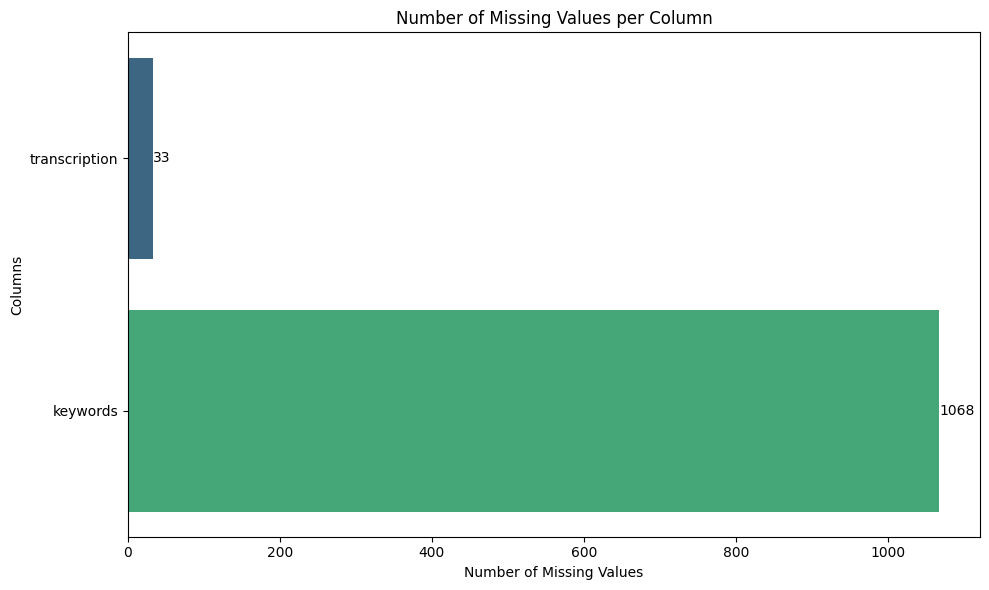

In [223]:
missing = df_medical.isnull().sum()

missing = missing[missing > 0].sort_values()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=missing.values,
    y=missing.index,
    hue=missing.index,
    palette='viridis',
    legend=False
)

# Hiển thị số lượng trên cột
for container in ax.containers:
    ax.bar_label(container)

plt.title('Number of Missing Values per Column')
plt.xlabel('Number of Missing Values')
plt.ylabel('Columns')

plt.tight_layout()
plt.show()



### <span style="color:#1565C0;">📌 Nhận xét</span>

- <span style="color:#2E7D32;">✅ Tập dữ liệu gồm **4.999** bản ghi và **6** thuộc tính.</span>

- <span style="color:#2E7D32;">✅ Các thuộc tính `Unnamed: 0`, `description`, `medical_specialty` và `sample_name` không có giá trị thiếu.</span>

- <span style="color:#FB8C00;">⚠️ Thuộc tính `transcription` có **33** giá trị thiếu (≈ **0,66%**), cần được xử lý trước khi huấn luyện mô hình.</span>

- <span style="color:#E53935;">❌ Thuộc tính `keywords` có **1.068** giá trị thiếu (≈ **21,36%**), tuy nhiên không ảnh hưởng vì không được sử dụng trong nghiên cứu.</span>

---

> <span style="color:#6A1B9A;"><b>📍 Kết luận:</b> Tập dữ liệu có chất lượng tốt. Sau khi xử lý các giá trị thiếu của <code>transcription</code>, dữ liệu đủ điều kiện để xây dựng mô hình phân loại chuyên khoa.</span>

## ☁️ Trực quan hóa tần suất từ trong văn bản y khoa

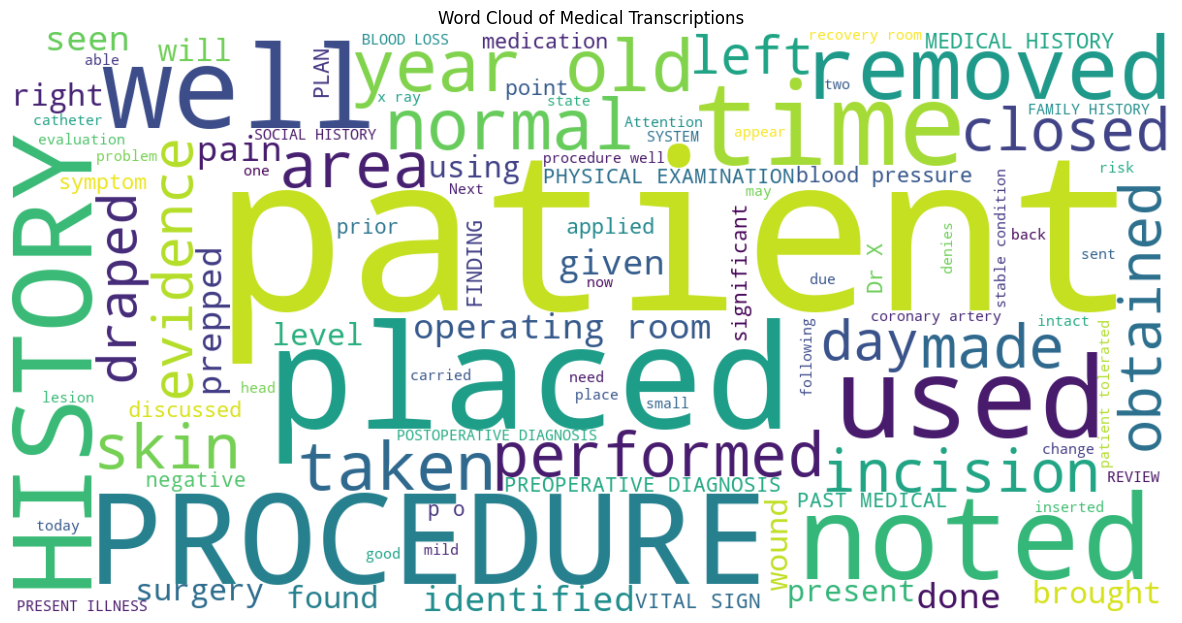

In [224]:

text = " ".join(df_medical['transcription'].dropna())

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100
).generate(text)

plt.figure(figsize=(15,8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Medical Transcriptions')
plt.show()

### 📌 Nhận xét

- Các từ **`patient`**, **`procedure`**, **`noted`**, **`history`**, **`used`** và **`performed`** xuất hiện với tần suất rất cao.
- Phần lớn đây là các từ mang tính **mô tả chung**, không có khả năng phân biệt rõ giữa các chuyên khoa.

## 🧹 Xử lý giá trị thiếu

### Thao tác thực hiện

- 🗑️ **Loại bỏ** các bản ghi có giá trị thiếu ở thuộc tính **`transcription`**, vì đây là đặc trưng đầu vào chính của mô hình.
- 🔄 **Thay thế** các giá trị thiếu trong **`keywords`** bằng chuỗi **`"unknown"`** để đảm bảo dữ liệu không còn giá trị `null`.
- ✅ **Kiểm tra lại** số lượng giá trị thiếu sau khi xử lý để xác nhận dữ liệu đã được làm sạch hoàn toàn.

> **Kết quả:** Sau bước xử lý, tập dữ liệu **không còn giá trị thiếu (`total_missing = 0`)**.

In [225]:
df_medical = df_medical.dropna(subset=["transcription"])
df_medical["keywords"] = df_medical["keywords"].fillna("unknown")
print(df_medical.isnull().sum())
print(f'total_mising:{df_medical.isnull().sum().sum()}')


Unnamed: 0           0
description          0
medical_specialty    0
sample_name          0
transcription        0
keywords             0
dtype: int64
total_mising:0


## 🧹 Lựa chọn thuộc tính và loại bỏ dữ liệu dư thừa

### Thao tác thực hiện

- 🗑️ **Loại bỏ** các thuộc tính không sử dụng: `description`, `sample_name`, `keywords` và `Unnamed: 0`.
- 🔄 **Loại bỏ** các bản ghi trùng lặp (nếu có).
- 📊 **Kiểm tra** kích thước tập dữ liệu (`shape`) và hiển thị 5 bản ghi đầu tiên (`head()`).

> **Mục đích:** Chỉ giữ lại các thuộc tính cần thiết (`medical_specialty` và `transcription`) để phục vụ quá trình xây dựng mô hình.

In [226]:
df_medical.drop(columns = ['description','sample_name','keywords','Unnamed: 0'], inplace = True)
df_medical = df_medical.drop_duplicates()
print(df_medical.shape)
print(df_medical.head())

(4964, 2)
             medical_specialty  \
0         Allergy / Immunology   
1                   Bariatrics   
2                   Bariatrics   
3   Cardiovascular / Pulmonary   
4   Cardiovascular / Pulmonary   

                                       transcription  
0  SUBJECTIVE:,  This 23-year-old white female pr...  
1  PAST MEDICAL HISTORY:, He has difficulty climb...  
2  HISTORY OF PRESENT ILLNESS: , I have seen ABC ...  
3  2-D M-MODE: , ,1.  Left atrial enlargement wit...  
4  1.  The left ventricular cavity size and wall ...  


## 📊 Trực quan hóa phân bố chuyên khoa

### Thao tác thực hiện

- 📈 Vẽ **biểu đồ cột ngang (Count Plot)** để thống kê số lượng mẫu của từng chuyên khoa.
- 🔢 Sắp xếp các chuyên khoa **(value_counts().index )** theo **số lượng mẫu giảm dần** để dễ quan sát.
- 🏷️ **(ax.bar_label(container))** Hiển thị **số lượng mẫu** trên mỗi cột.
- 📋 Thêm tiêu đề và nhãn trục để biểu đồ rõ ràng, dễ đọc.


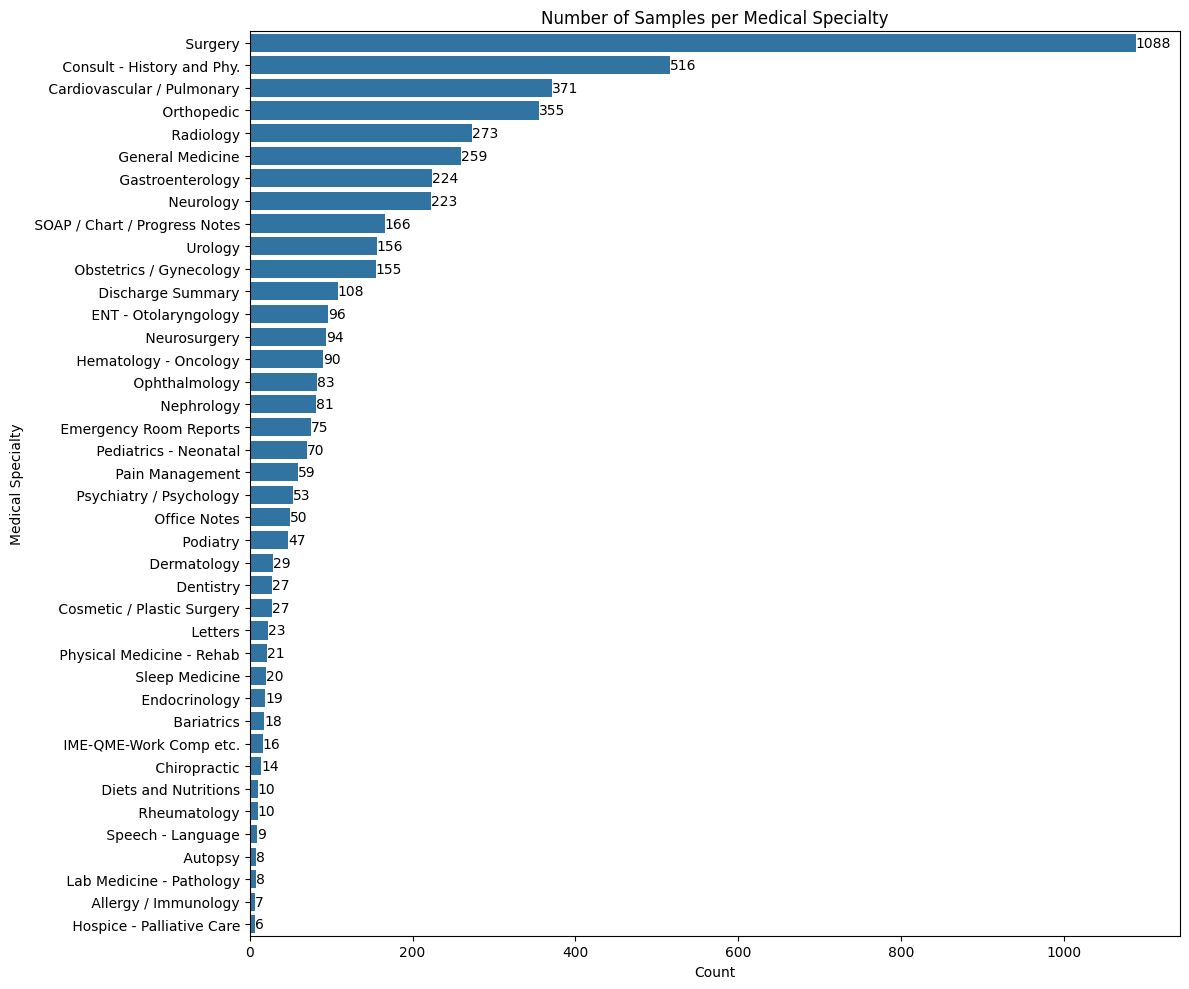

In [227]:
plt.figure(figsize=(12,10))

ax = sns.countplot(
    data=df_medical,
    y='medical_specialty',
    order=df_medical['medical_specialty'].value_counts().index
)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Number of Samples per Medical Specialty')
plt.xlabel('Count')
plt.ylabel('Medical Specialty')

plt.tight_layout()
plt.show()

### 📌 Nhận xét

- Dữ liệu **phân bố không đồng đều** giữa các chuyên khoa.
- **Surgery** có số lượng mẫu lớn nhất (**1.088**), trong khi nhiều chuyên khoa chỉ có dưới **30** mẫu.
- Tập dữ liệu có **mất cân bằng lớp (Class Imbalance)**.
> <span style="color:#D32F2F;"><b>📌 Kết luận:</b></span>  
> <span style="color:#1565C0;">
> Chỉ sử dụng <b>Top 5 chuyên khoa</b> có nhiều mẫu nhất để giảm mất cân bằng dữ liệu và nâng cao hiệu quả huấn luyện mô hình.
> </span>

# Tiền xử lý

## 📝 Thiết lập các thành phần tiền xử lý văn bản

- medical_abbreviations = {...} -> Tạo từ điển viết tắt y khoa để mở rộng các từ viết tắt thành từ đầy đủ khi tiền xử lý văn bản.
- medical_stopwords = {...} ->Tạo danh sách các từ y khoa ít giá trị để loại bỏ khỏi văn bản.
- WordNetLemmatizer() -> Khởi tạo bộ lemmatizer để đưa từ về dạng gốc trong quá trình tiền xử lý.

In [228]:

medical_abbreviations = {
    # Bệnh lý tim mạch
    "htn": "hypertension",
    "cad": "coronary artery disease",
    "chf": "congestive heart failure",
    "mi": "myocardial infarction",
    "af": "atrial fibrillation",
    "cvd": "cardiovascular disease",
    "cabg": "coronary artery bypass graft",

    # Nội tiết
    "dm": "diabetes mellitus",
    "t1dm": "type one diabetes mellitus",
    "t2dm": "type two diabetes mellitus",

    # Hô hấp
    "copd": "chronic obstructive pulmonary disease",
    "sob": "shortness of breath",
    "doe": "dyspnea on exertion",
    "uri": "upper respiratory infection",

    # Thận
    "ckd": "chronic kidney disease",
    "aki": "acute kidney injury",

    # Dấu hiệu sinh tồn
    "bp": "blood pressure",
    "hr": "heart rate",
    "rr": "respiratory rate",
    "temp": "temperature",

    # Thuật ngữ lâm sàng
    "hx": "history",
    "pmh": "past medical history",
    "fhx": "family history",
    "shx": "social history",
    "dx": "diagnosis",
    "tx": "treatment",
    "rx": "prescription",
    "sx": "symptoms",
    "fx": "fracture",
    "px": "prognosis",

    # Bệnh nhân
    "pt": "patient",
    "pts": "patients",
    "yo": "year old",

    # Ghi chú bác sĩ
    "c/o": "complains of",
    "r/o": "rule out",
    "s/p": "status post",
    "w/": "with",
    "w/o": "without",
    "b/l": "bilateral",

    # Xét nghiệm và chẩn đoán hình ảnh
    "ct": "computed tomography",
    "mri": "magnetic resonance imaging",
    "ecg": "electrocardiogram",
    "ekg": "electrocardiogram",
    "cxr": "chest x ray",
    "us": "ultrasound",

    # Xét nghiệm máu
    "cbc": "complete blood count",
    "wbc": "white blood cell",
    "rbc": "red blood cell",
    "hgb": "hemoglobin",
    "hct": "hematocrit",

    # Khác
    "iv": "intravenous",
    "po": "oral",
    "prn": "as needed",
    "bid": "twice daily",
    "tid": "three times daily",
    "qid": "four times daily",
    "stat": "immediately",
}


medical_stopwords = {
    # Thông tin bệnh nhân
    "patient", "patients", "male", "female",
    "man", "woman", "boy", "girl",
    "year", "years", "old",

    # Từ chung trong báo cáo
    "history", "exam", "examination",
    "finding", "findings", "clinical",
    "report", "evaluation", "assessment",
    "review", "consultation", "visit",
    "procedure", "well", "placed","wa","will",
    "used", "doe", "evidence","removed","using",
    "left","right","lateral", "bilateral","ha",

    # Hoạt động khám chữa bệnh
    "performed", "obtained", "completed",
    "noted", "seen", "presented",
    "treated", "admitted", "discharged",

    # Từ ít giá trị phân loại
    "normal", "abnormal",
    "positive", "negative",
    "moderate",

    # Chăm sóc y tế
    "doctor", "physician",
    "hospital", "medical",
    "care", "service",

    # Chẩn đoán điều trị
    "diagnoses",
    "treatment", "therapy",
    "operation",

    # Từ chức năng
    "include", "including",
    "show", "shows",
    "demonstrate", "demonstrates",

    # Từ thời gian
    "today", "yesterday",
    "currently", "previously",
    "recently", "prior","day","time",

    # Đơn vị và mô tả
    "cm", "mm", "mg", "ml",
    "bilateral",

    # Từ rất phổ biến trong transcription
    "status", "post", "without", "with",
    "within", "however", "therefore",
    "also", "approximately"
}

lemmatizer = WordNetLemmatizer()

## 🧹 Hàm tiền xử lý văn bản y khoa

### Các bước thực hiện

- 🔍 **`isinstance(text, str)`**: Kiểm tra dữ liệu đầu vào có phải là chuỗi hay không; nếu không thì trả về chuỗi rỗng (`""`).
- ✂️ **Chuẩn hóa văn bản:** Loại bỏ khoảng trắng thừa, chuyển toàn bộ văn bản về chữ thường.
- 🧽 **Làm sạch dữ liệu:** Xóa ký tự xuống dòng, tab, số thứ tự và các ký tự đặc biệt.
- 🔤 **Mở rộng từ viết tắt:** Thay thế các từ viết tắt y khoa bằng dạng đầy đủ thông qua từ điển `medical_abbreviations`.
- 📝 **Tách từ (Tokenization):** Chia văn bản thành các từ riêng lẻ.
- 🚫 **Loại bỏ từ không cần thiết:** Xóa các từ dừng (Medical Stopwords) ít mang ý nghĩa.
- 📚 **Lemmatization:** Đưa các từ về dạng gốc bằng `WordNetLemmatizer`.
- ✅ **Chuẩn hóa kết quả:** Ghép các từ thành văn bản sạch, sẵn sàng cho quá trình trích xuất đặc trưng và huấn luyện mô hình.

In [ ]:
def preprocess_medical_text(text):
    if not isinstance(text, str):
        return ""
    
    # strip khoảng trắng đầu cuối
    text = text.strip()

    # Chuyển về chữ thường
    text = text.lower()

    # Loại bỏ xuống dòng và tab
    text = re.sub(r'[\n\r\t]+', ' ', text)

    # Loại bỏ số thứ tự đầu dòng: 1. 2. a. b. i. ii.
    text = re.sub(r'\b\d+\.', ' ', text)
    text = re.sub(r'\b[a-zA-Z]\.', ' ', text)
    text = re.sub(r'\b(i|ii|iii|iv|v|vi|vii|viii|ix|x)\.', ' ', text)

    # Thay thế từ viết tắt y khoa
    words = text.split()
    words = [medical_abbreviations.get(word, word) for word in words]

    text = " ".join(words)

    # Loại bỏ ký tự đặc biệt
    text = re.sub(r'[#*@%&$^~`|\\/+=<>{}\[\]()"\'_:;,-]', ' ', text)

    # Giữ lại chữ và số
    text = re.sub(r'[^a-z0-9\s]', ' ', text)

    # Tách từ
    words = word_tokenize(text)

    words = [lemmatizer.lemmatize(word) for word in words]
    
    # Loại bỏ stopwords y khoa
    words = [word for word in words if word not in medical_stopwords]


    # Loại bỏ khoảng trắng thừa
    text = " ".join(words)

    return text

## ✨ Áp dụng tiền xử lý văn bản

### Thao tác thực hiện

- 🧹 **Tiền xử lý văn bản:** Áp dụng hàm `preprocess_medical_text()` cho thuộc tính `transcription` và lưu kết quả vào cột mới `clean_text`.
- ✂️ **Chuẩn hóa nhãn:** Loại bỏ khoảng trắng thừa ở đầu và cuối của thuộc tính `medical_specialty` bằng `str.strip()` để đảm bảo tính nhất quán của nhãn.

> <span style="color:#2E7D32;"><b>✅ Kết quả:</b> Dữ liệu văn bản đã được làm sạch và nhãn chuyên khoa được chuẩn hóa, sẵn sàng cho bước trích xuất đặc trưng (TF-IDF) và huấn luyện mô hình.</span>

In [ ]:
df_medical['clean_text'] = df_medical['transcription'].apply(preprocess_medical_text)
df_medical["medical_specialty"] = (df_medical["medical_specialty"].str.strip())

## 🔍 Kiểm tra kết quả tiền xử lý

### Thao tác thực hiện

- 📋 Hiển thị **10 bản ghi đầu tiên** của thuộc tính `clean_text`.
- ✅ Kiểm tra kết quả sau khi áp dụng hàm tiền xử lý văn bản.

> <span style="color:#1565C0;"><b>Mục đích:</b> Đảm bảo văn bản đã được làm sạch, chuẩn hóa và sẵn sàng cho bước trích xuất đặc trưng (TF-IDF).</span>

In [231]:
print(df_medical["clean_text"][:10])

0    subjective this 23 white present complaint of ...
1    past he difficulty climbing stair difficulty a...
2    of present illness i have abc he is a very ple...
3    2 d m mode atrial enlargement atrial diameter ...
4    the ventricular cavity size and wall thickness...
5    preoperative diagnosis morbid obesity postoper...
6    preoperative diagnosis deformity breast recons...
7    2 d echocardiogram multiple view of the heart ...
8    preoperative diagnosis lipodystrophy of the ab...
9    description cardiac chamber size ventricular s...
Name: clean_text, dtype: object


# 📊 Kiểm tra tần suất xuất hiện của từ sau tiền xử lý

### ⚙️ Mô tả các hàm
---
- dropna() -> Loại bỏ các giá trị bị thiếu trước khi tạo Word Cloud.
- .generate(text) -> Tạo Word Cloud từ văn bản.
- plt.imshow(wordcloud,...) -> Hiển thị Word Cloud.

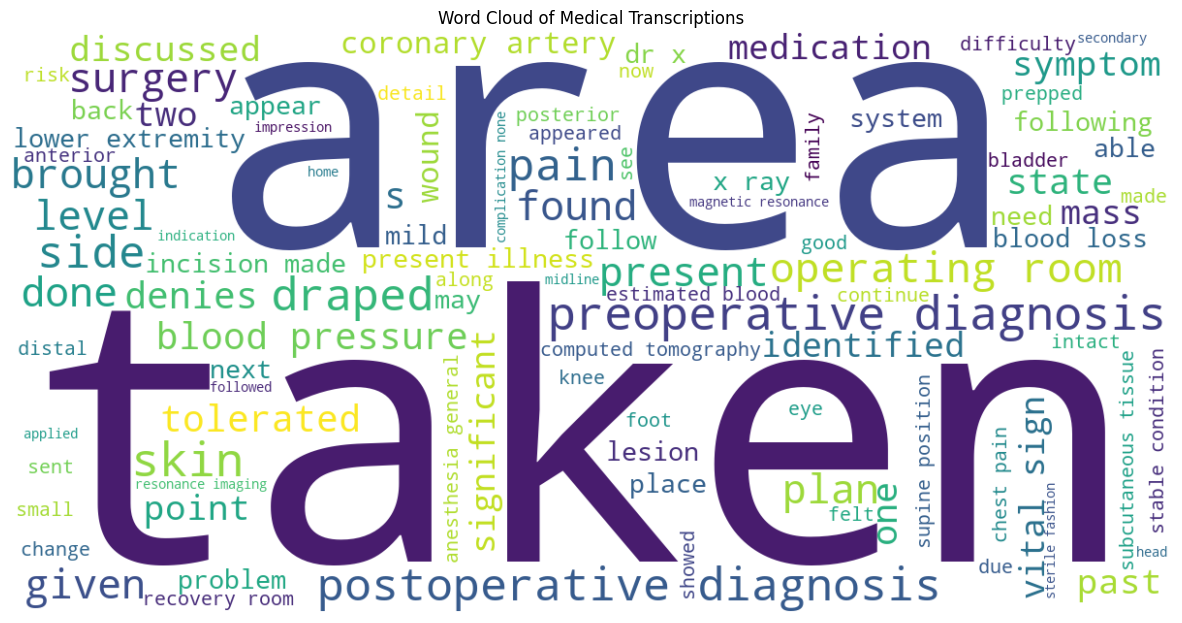

In [232]:
text = " ".join(df_medical['clean_text'].dropna())

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100
).generate(text)

plt.figure(figsize=(15,8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Medical Transcriptions')
plt.show()

> <span style="color:#2E7D32;"><b>✅ Nhận xét:</b></span>
> <span style="color:#1565C0;">
> Sau tiền xử lý, các từ phổ biến nhưng ít giá trị đã được loại bỏ, giúp Word Cloud tập trung vào các thuật ngữ y khoa đặc trưng và nâng cao chất lượng dữ liệu cho bước trích xuất đặc trưng.
> </span>

### ⚙️ Mô tả các hàm
---
- value_counts().head(6).index -> Lấy 6 chuyên khoa có nhiều mẫu nhất.
- zip(axes.flatten(), top_specialties): Duyệt từng ô biểu đồ và từng chuyên khoa tương ứng.
- df_medical.loc[...] -> Lọc văn bản theo từng chuyên khoa.
- WordCloud(...) -> Khởi tạo Word Cloud.
- .generate(text) -> Tạo Word Cloud cho từng chuyên khoa.

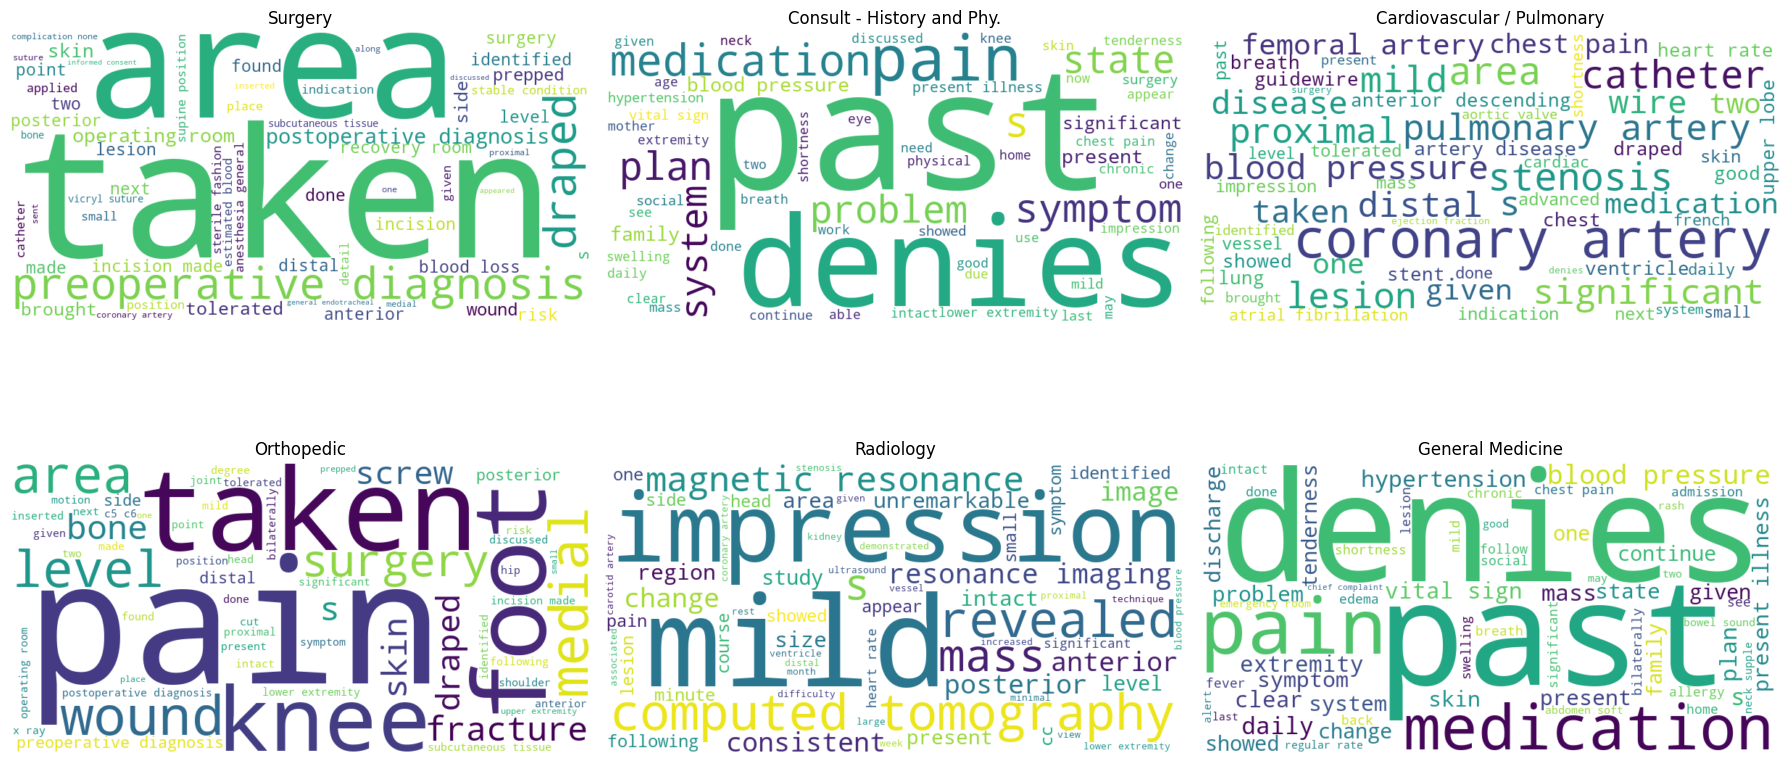

In [233]:
fig, axes = plt.subplots(2, 3, figsize=(18,10))

top_specialties = (
    df_medical['medical_specialty'].value_counts().head(6).index
)

for ax, specialty in zip(
        axes.flatten(),
        top_specialties):

    text = " ".join(
        df_medical.loc[df_medical['medical_specialty'] == specialty,'clean_text']
    )

    wc = WordCloud(
        width=800,
        height=400,
        background_color='white',
        max_words=60
    ).generate(text)

    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(specialty)

plt.tight_layout()
plt.show()

> <span style="color:#7B1FA2;"><b>✅ Nhận xét:</b></span><br>


> <span style="color:#1E3A8A;">
> • <b>Surgery</b> nổi bật với các từ <code>taken</code>, <code>incision</code>, <code>preoperative diagnosis</code>.
> </span><br>

> <span style="color:#1E3A8A;">
> • <b>Cardiovascular / Pulmonary</b> xuất hiện nhiều thuật ngữ như <code>coronary artery</code>, <code>catheter</code>, <code>stenosis</code>.
> </span><br>

> <span style="color:#1E3A8A;">
> • <b>Orthopedic</b> tập trung vào các từ <code>pain</code>, <code>fracture</code>, <code>wound</code>, <code>bone</code>.
> </span><br>

> <span style="color:#1E3A8A;">
> • <b>Radiology</b> nổi bật với <code>impression</code>, <code>computed tomography</code>, <code>magnetic resonance imaging</code>.
> </span><br>

> <span style="color:#1E3A8A;">
> • Điều này cho thấy mỗi chuyên khoa có tập từ vựng đặc trưng riêng, tạo nền tảng cho việc trích xuất đặc trưng và xây dựng mô hình phân loại.
> </span>

# 🏥 Lựa chọn 5 chuyên khoa tiêu biểu

### ⚙️ Mô tả các hàm
---
- isin(top_5_specialties) ->Lọc dữ liệu chỉ giữ các mẫu thuộc 5 chuyên khoa này.
- .copy() ->Tạo bản sao của DataFrame đã lọc.

In [234]:
# Lấy ra danh sách 5 chuyên khoa có số lượng bài viết nhiều nhất
top_5_specialties = df_medical['medical_specialty'].value_counts().head(5).index

# Lọc DataFrame chỉ giữ lại dữ liệu của 5 chuyên khoa này
df_medical_filtered = (
    df_medical[df_medical['medical_specialty'].isin(top_5_specialties)]
    .reset_index(drop=True)
)

print(df_medical_filtered.shape)
df_medical_filtered.head()

(2603, 3)


,medical_specialty,transcription,clean_text
0,Cardiovascular / Pulmonary,"2-D M-MODE: , ,1. Left atrial enlargement wit...",2 d m mode atrial enlargement atrial diameter ...
1,Cardiovascular / Pulmonary,1. The left ventricular cavity size and wall ...,the ventricular cavity size and wall thickness...
2,Cardiovascular / Pulmonary,"2-D ECHOCARDIOGRAM,Multiple views of the heart...",2 d echocardiogram multiple view of the heart ...
3,Cardiovascular / Pulmonary,"DESCRIPTION:,1. Normal cardiac chambers size....",description cardiac chamber size ventricular s...
4,Cardiovascular / Pulmonary,"2-D STUDY,1. Mild aortic stenosis, widely calc...",2 d study mild aortic stenosis widely calcifie...


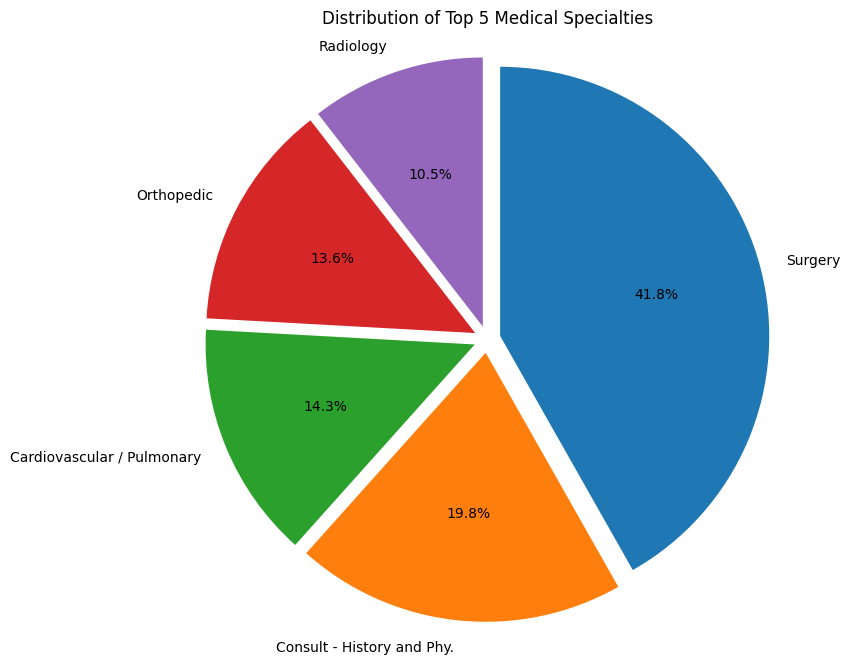

In [235]:
specialty_counts = df_medical_filtered['medical_specialty'].value_counts()

explode = [0.05] * len(specialty_counts)

plt.figure(figsize=(8, 8))
plt.pie(
    specialty_counts,
    labels=specialty_counts.index,
    autopct='%1.1f%%',
    explode=explode,
    startangle=90,
    counterclock=False
)

plt.title("Distribution of Top 5 Medical Specialties")
plt.axis('equal')
plt.show()

### 📌 Nhận xét phân bố chuyên khoa

- `Surgery` chiếm tỷ trọng cao nhất (**>40% mẫu Top 5**), vượt trội so với các chuyên khoa còn lại.
- Các lớp còn lại (`Cardiovascular / Pulmonary`, `Orthopedic`, `Radiology`, `Consult - History and Phy.`) có tỷ lệ tương đối cân bằng.

➡️ **Dữ liệu vẫn mất cân bằng sau khi lọc Top 5**, do đó cần:
- `stratify=y` khi chia dữ liệu.
- `class_weight="balanced"` để giảm thiên lệch về lớp phổ biến.

# ✂️ Chia dữ liệu huấn luyện và kiểm tra (Train/Test Split)

📌 **Thiết lập:**
- `X`: văn bản đã làm sạch (`clean_text`)
- `y`: nhãn chuyên khoa (`medical_specialty`)
- `stratify=y`: duy trì tỷ lệ phân bố các lớp.
- `random_state=42`: đảm bảo kết quả tái lập.

In [236]:
# Gán lại X và y từ dữ liệu đã lọc sạch
X = df_medical_filtered['clean_text']
y = df_medical_filtered['medical_specialty']

# Tiến hành chia dữ liệu (vẫn giữ stratify để cân bằng các lớp)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## 🔢 Label Encoding

Chuyển đổi nhãn chuyên khoa từ dạng chữ sang dạng số:

- `fit_transform(y_train)`: học và mã hóa nhãn tập train.
- `transform(y_test)`: mã hóa tập test theo quy tắc đã học.

In [237]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

## 📊 Khai phá đặc trưng từ khóa TF-IDF theo từng chuyên khoa

### ⚙️ Mô tả các hàm
---
- astype(str) -> Chuyển dữ liệu về kiểu chuỗi.
- TfidfVectorizer(...) -> Khởi tạo bộ trích xuất đặc trưng TF-IDF.
- fit_transform(texts) -> Chuyển văn bản thành ma trận TF-IDF.
- mean(axis=0) -> Tính điểm TF-IDF trung bình của mỗi từ.
- get_feature_names_out() -> Lấy danh sách các từ trong TF-IDF.
- ax.barh(...) -> Vẽ biểu đồ cột ngang của 10 từ quan trọng nhất.
- bar.get_width -> Lấy chiều dài (giá trị) của từng cột trong biểu đồ ngang.

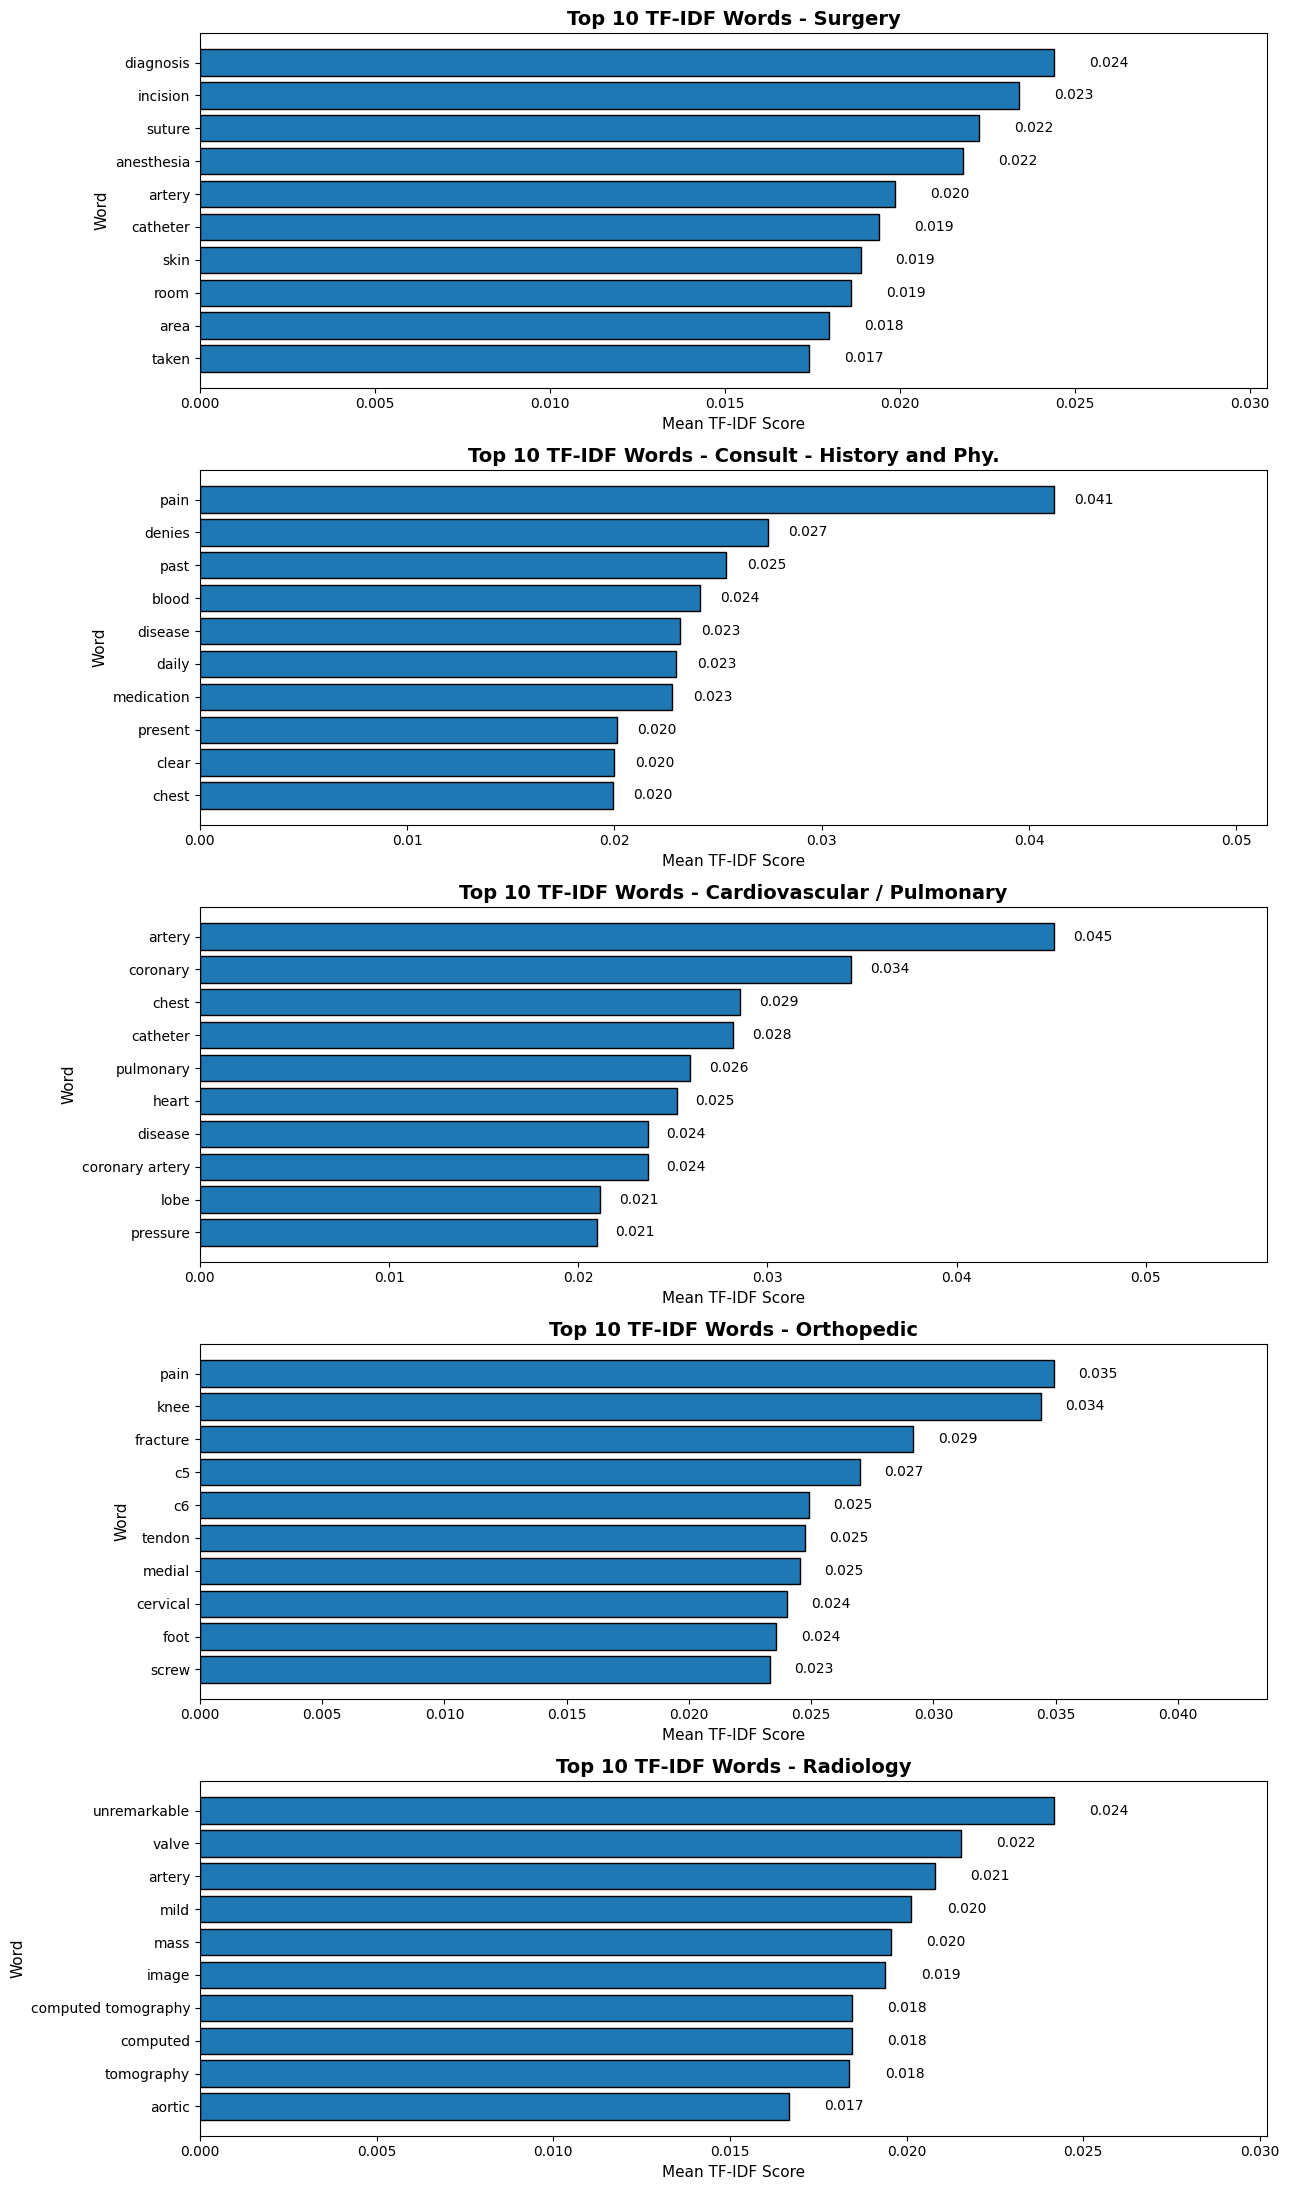

In [238]:

top5_labels = y_train.value_counts().head(5).index

fig, axes = plt.subplots(5, 1, figsize=(13, 22))

for ax, label in zip(axes, top5_labels):

    # Văn bản của chuyên khoa
    texts = X_train[y_train == label].dropna().astype(str)

    # TF-IDF
    vectorizer = TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        stop_words="english"
    )

    X_tfidf = vectorizer.fit_transform(texts)

    scores = X_tfidf.mean(axis=0).A1

    importance = pd.DataFrame({
        "Word": vectorizer.get_feature_names_out(),
        "Score": scores
    })

    # Top 10 từ quan trọng
    importance = importance.sort_values(
        by="Score",
        ascending=False
    ).head(10)

    # Vẽ biểu đồ
    bars = ax.barh(
        importance["Word"][::-1],
        importance["Score"][::-1],
        edgecolor="black"
    )

    # Hiển thị giá trị TF-IDF trên cột
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 0.001,
            bar.get_y() + bar.get_height()/2,
            f"{width:.3f}",
            va="center",
            fontsize=10
        )

    ax.set_title(f"Top 10 TF-IDF Words - {label}",
                 fontsize=14,
                 fontweight="bold")

    ax.set_xlabel("Mean TF-IDF Score", fontsize=11)
    ax.set_ylabel("Word", fontsize=11)

    # Chừa khoảng trống để số không bị cắt
    ax.set_xlim(0, importance["Score"].max()*1.25)

plt.tight_layout()
plt.show()

### 📊 Nhận xét TOP 10 TF-IDF WORDS

---
* **Đặc trưng TF-IDF chuẩn xác:** Điểm số phản ánh đúng độ quan trọng và tính phân biệt cao giữa các chuyên khoa:
  * **Surgery:** `diagnosis` (0.024), `incision` (0.023), `suture` (0.022), `anesthesia` (0.022).
  * **Consult - History & Phy.:** `pain` (0.041), `denies` (0.027), `blood` (0.024), `medication` (0.023).
  * **Cardiovascular / Pulmonary:** `artery` (0.045), `coronary` (0.034), `chest` (0.029), `pulmonary` (0.026).
  * **Orthopedic:** `pain` (0.035), `knee` (0.034), `fracture` (0.029), `c5`, `c6`, `tendon`.
  * **Radiology:** `unremarkable` (0.024), `valve`, `image`, `computed tomography`.


## 📊 Khai phá đặc trưng từ khóa BoW theo từng chuyên khoa

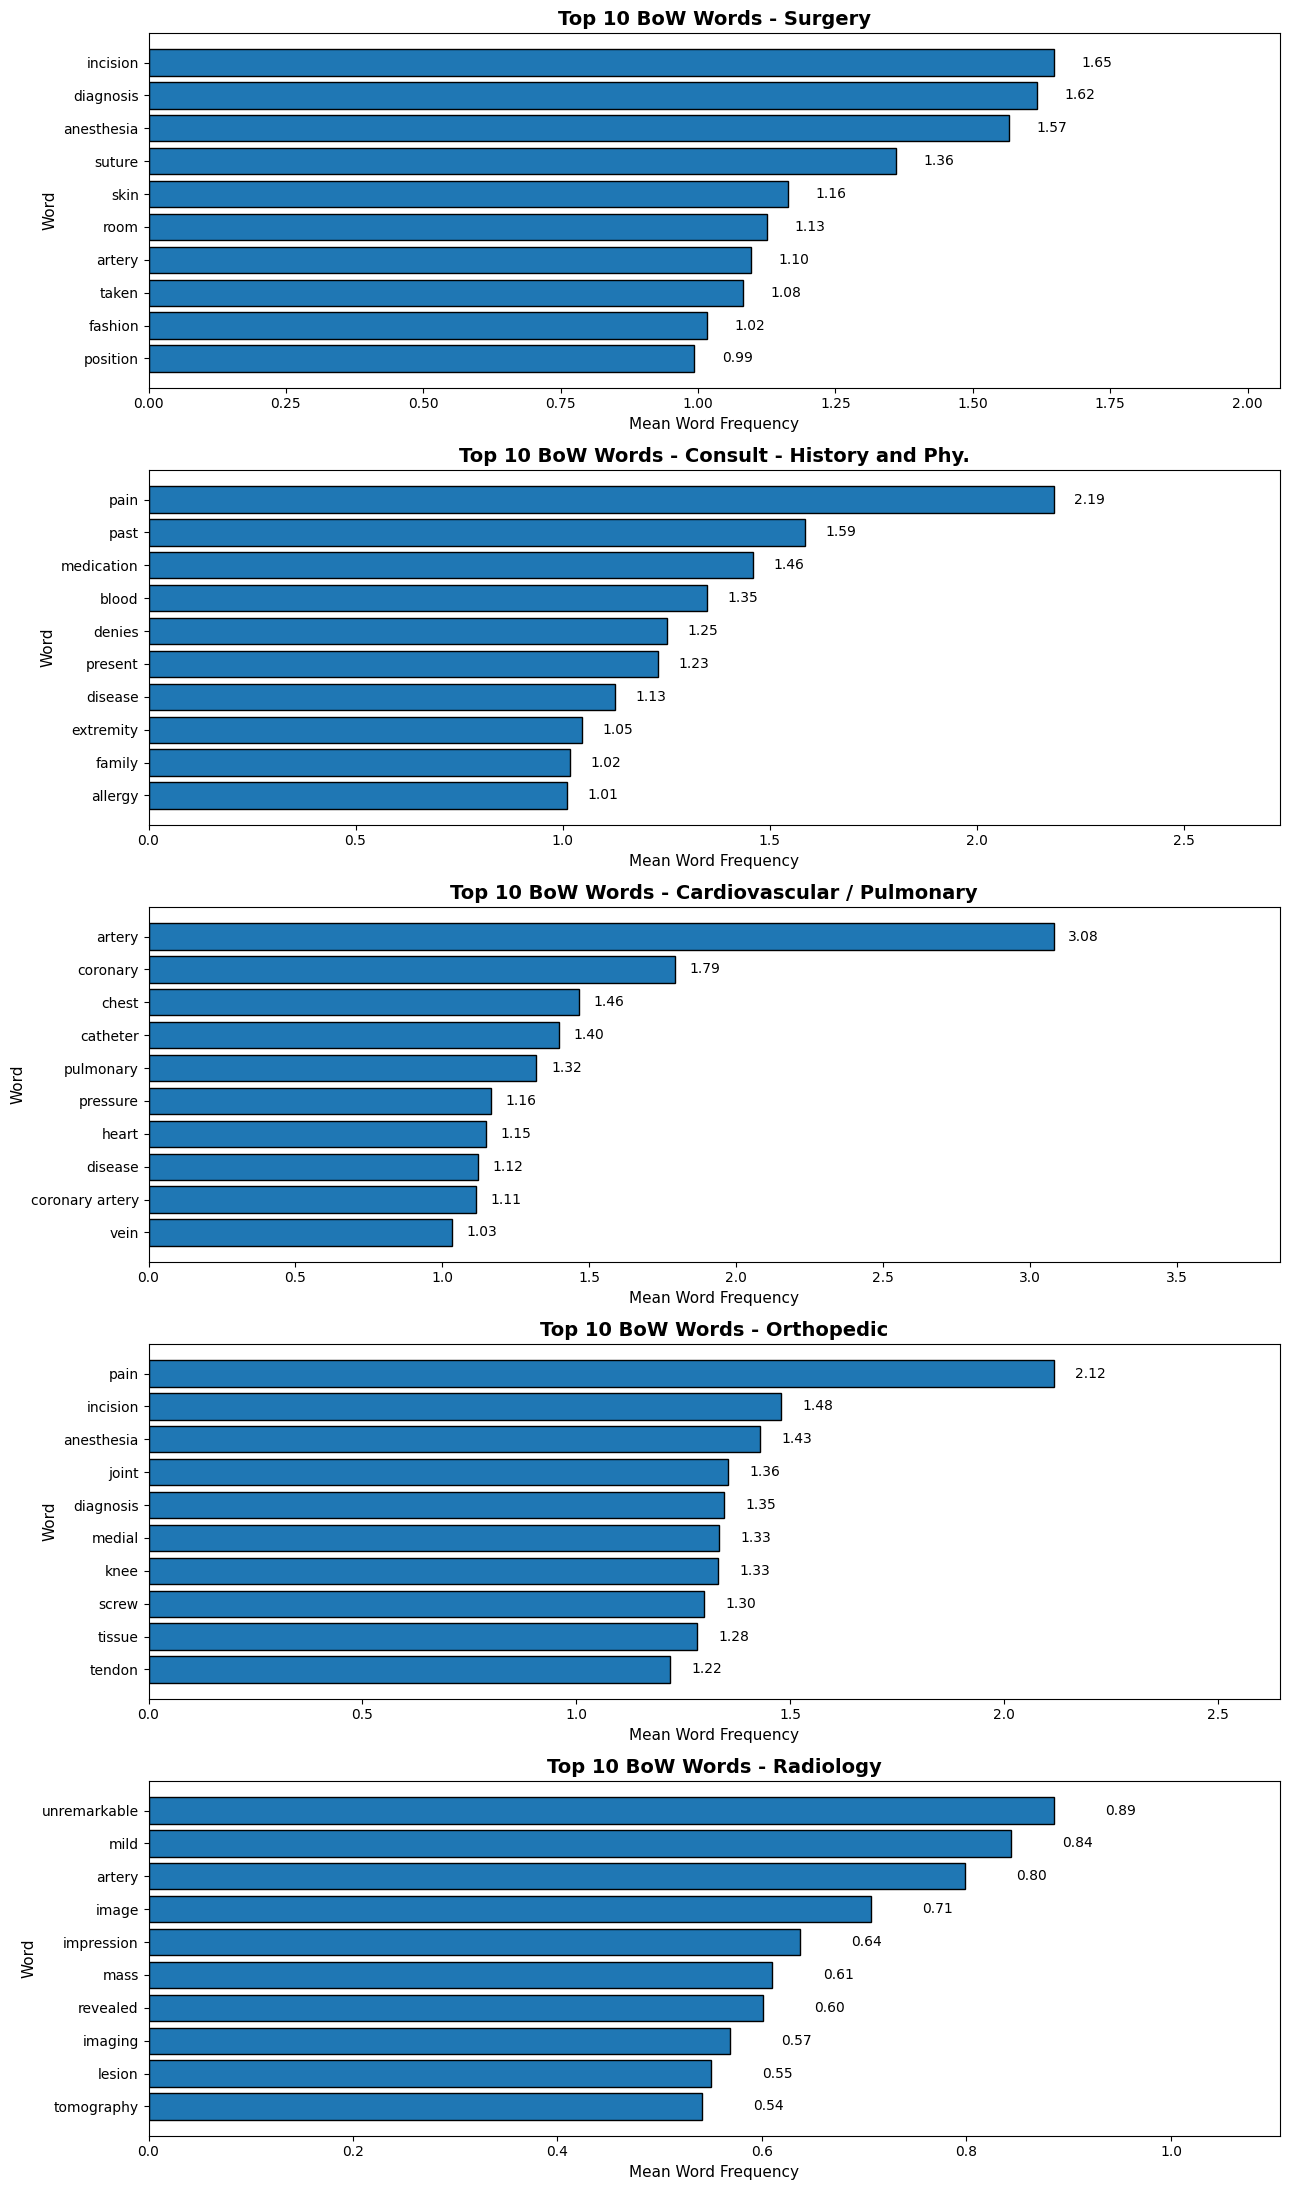

In [239]:
# Lấy 5 chuyên khoa có nhiều dữ liệu nhất
top5_labels = y_train.value_counts().head(5).index

fig, axes = plt.subplots(5, 1, figsize=(13, 22))

for ax, label in zip(axes, top5_labels):

    # Văn bản của chuyên khoa
    texts = X_train[y_train == label].dropna().astype(str)

    # Bag of Words
    vectorizer = CountVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        stop_words="english"
    )

    X_bow = vectorizer.fit_transform(texts)

    # Tính tần suất trung bình của mỗi từ
    scores = X_bow.mean(axis=0).A1

    importance = pd.DataFrame({
        "Word": vectorizer.get_feature_names_out(),
        "Frequency": scores
    })

    # Top 10 từ xuất hiện nhiều nhất
    importance = importance.sort_values(
        by="Frequency",
        ascending=False
    ).head(10)

    # Vẽ biểu đồ
    bars = ax.barh(
        importance["Word"][::-1],
        importance["Frequency"][::-1],
        edgecolor="black"
    )

    # Hiển thị giá trị trên cột
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 0.05,
            bar.get_y() + bar.get_height()/2,
            f"{width:.2f}",
            va="center",
            fontsize=10
        )

    ax.set_title(
        f"Top 10 BoW Words - {label}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Mean Word Frequency",
        fontsize=11
    )

    ax.set_ylabel(
        "Word",
        fontsize=11
    )

    ax.set_xlim(
        0,
        importance["Frequency"].max()*1.25
    )

plt.tight_layout()
plt.show()

### 📊 Nhận Xét TOP 10 BOW WORDS 

---

* **Đặc trưng chuyên khoa nổi bật:** Tần suất xuất hiện hiện tại tập trung hoàn toàn vào các thuật ngữ y khoa cốt lõi:
  * **Surgery:** `incision` (1.65), `diagnosis` (1.62), `anesthesia` (1.57), `suture` (1.36).
  * **Consult - History & Phy.:** `pain` (2.19), `medication` (1.46), `blood` (1.35), `allergy` (1.01).
  * **Cardiovascular / Pulmonary:** `artery` (3.08), `coronary` (1.79), `chest` (1.46), `coronary artery` (1.11).
  * **Orthopedic:** `pain` (2.12), `incision` (1.48), `joint` (1.36), `screw` (1.30), `knee` (1.33).
  * **Radiology:** `unremarkable` (0.89), `image` (0.71), `impression` (0.64), `tomography` (0.54).


# Huấn luyện mô hình

## Helper Functions

### ⚙️ Mô tả các hàm
---
- compute_metrics() -> Tính các chỉ số Accuracy, Precision, Recall và F1-score
- bar.get_height() -> Lấy giá trị của từng cột để hiển thị lên biểu đồ.
- plot_svd() -> Giảm chiều dữ liệu TF-IDF và trực quan hóa các lớp.
- label_binarize() -> Chuyển nhãn đa lớp thành dạng nhị phân để tính ROC.
- auc() -> Tính diện tích dưới đường cong ROC (AUC).
- StratifiedKFold() -> Chia dữ liệu Cross Validation, giữ tỷ lệ các lớp.
- TfidfVectorizer() ->	Chuyển văn bản thành đặc trưng TF-IDF.
- TruncatedSVD() -> Giảm chiều dữ liệu TF-IDF xuống 2 chiều.

In [254]:
def plot_confusion(y_true, y_pred, model_name, class_names=None):
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(14, 12))
    
    if class_names is not None:
        ticks = class_names
    else:
        ticks = np.unique(np.concatenate([y_true, y_pred]))
    
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        xticklabels=ticks,
        yticklabels=ticks
    )
    
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {model_name}")
    
    plt.tight_layout()
    plt.show()

def compute_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

def plot_roc_curve(y_test, y_score, model_name, le):
    n_classes = len(le.classes_)
    y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))
    
    fpr, tpr, roc_auc = dict(), dict(), dict()
    # Micro-average ROC
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    
    # Macro-average ROC
    all_fpr = np.unique(np.concatenate([roc_curve(y_test_bin[:, i], y_score[:, i])[0] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, roc_curve(y_test_bin[:, i], y_score[:, i])[0], roc_curve(y_test_bin[:, i], y_score[:, i])[1])
    mean_tpr /= n_classes
    fpr["macro"], tpr["macro"] = all_fpr, mean_tpr
    roc_auc["macro"] = auc(all_fpr, mean_tpr)
    
    plt.figure(figsize=(7, 5))
    plt.plot(fpr["micro"], tpr["micro"], label=f'Micro ROC (AUC = {roc_auc["micro"]:.2f})', color='deeppink', linestyle=':', linewidth=3)
    plt.plot(fpr["macro"], tpr["macro"], label=f'Macro ROC (AUC = {roc_auc["macro"]:.2f})', color='navy', linestyle=':', linewidth=3)
    plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {model_name}')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

def plot_learning_curve_graph(estimator, X, y, model_name, scoring="accuracy", cv=3, train_sizes=np.linspace(0.2, 1.0, 4), skip_stacking=True):
    if skip_stacking and "Stacking" in model_name:
        print(f"Skip Learning Curve for {model_name} (too computationally expensive).")
        return

    cv_strategy = StratifiedKFold(
        n_splits=cv,
        shuffle=True,
        random_state=42
    )

    train_sizes, train_scores, val_scores = learning_curve(
        estimator=estimator,
        X=X,
        y=y,
        cv=cv_strategy,
        scoring=scoring,
        train_sizes=train_sizes,
        n_jobs=-1
    )

    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)

    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)

    plt.figure(figsize=(8,5))

    plt.plot(
        train_sizes,
        train_mean,
        "o-",
        linewidth=2,
        label="Training Score"
    )

    plt.plot(
        train_sizes,
        val_mean,
        "o-",
        linewidth=2,
        label="Validation Score"
    )

    # Vùng độ lệch chuẩn
    plt.fill_between(
        train_sizes,
        train_mean-train_std,
        train_mean+train_std,
        alpha=0.15
    )

    plt.fill_between(
        train_sizes,
        val_mean-val_std,
        val_mean+val_std,
        alpha=0.15
    )

    plt.title(f"Learning Curve - {model_name}", fontsize=14, fontweight="bold")
    plt.xlabel("Number of Training Samples")
    plt.ylabel(scoring.replace("_", " ").title())

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


# PLOT METRICS BAR

def plot_metrics_bar(results_df):

    metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

    colors = plt.cm.Set2.colors

    for i, metric in enumerate(metrics):

        fig, ax = plt.subplots(figsize=(8, 5))

        bars = ax.bar(
            results_df.index,
            results_df[metric],
            color=colors,
            edgecolor="black",
            linewidth=1
        )

        ax.set_title(f"{metric} Comparison", fontsize=14, weight="bold")
        ax.set_xlabel("Models", fontsize=11)
        ax.set_ylabel(metric, fontsize=11)

        ax.set_ylim(0, 1)

        ax.grid(
            axis="y",
            linestyle="--",
            alpha=0.4
        )

        plt.xticks(rotation=20, ha="right")

        for bar in bars:
            height = bar.get_height()

            ax.text(
                bar.get_x() + bar.get_width()/2,
                height + 0.01,
                f"{height:.3f}",
                ha="center",
                fontsize=9,
                fontweight="bold"
            )

        plt.tight_layout()
        plt.show()


# PLOT SVD
def plot_svd(X_text, y, label_encoder=None):

    tfidf = TfidfVectorizer(
        max_features=20000,
        ngram_range=(1,2),
        min_df=2,
        max_df=0.90,
        stop_words="english",
        sublinear_tf=True
    )

    X = tfidf.fit_transform(X_text)

    svd = TruncatedSVD(
        n_components=2,
        random_state=42
    )

    X_2d = svd.fit_transform(X)

    plt.figure(figsize=(9,7))

    classes = sorted(set(y))

    for c in classes:

        idx = y == c

        label = (
            label_encoder.inverse_transform([c])[0]
            if label_encoder is not None
            else str(c)
        )

        plt.scatter(
            X_2d[idx,0],
            X_2d[idx,1],
            s=30,
            alpha=0.7,
            label=label
        )

    plt.title("TF-IDF + Truncated SVD")
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.legend()
    plt.grid(alpha=.3)
    plt.show()
    

## ⚙️ CÀI ĐẶT MÔ HÌNH HỌC MÁY

## 🤖 Xây dựng Pipeline 

---

Hàm `evaluate_all_models()` được xây dựng nhằm tự động hóa toàn bộ quy trình:

- Khởi tạo các mô hình học máy.
- Xây dựng Pipeline gồm:
  - TF-IDF Vectorization, BoW.
  - Feature Selection (nếu có).
  - Model Training.
- Huấn luyện và đánh giá mô hình.
- Tính toán các chỉ số đánh giá.
- Trực quan hóa kết quả bằng:
  - Learning Curve.
  - Confusion Matrix.
  - ROC-AUC Curve.

---

## ⚙️ Các mô hình được triển khai

| Mô hình | Thuật toán | Vai trò |
|:---:|:---|:---|
| 📈 Logistic Regression | Linear Model | Mô hình tuyến tính cơ sở |
| 🔵 Linear SVM | Support Vector Machine | Tối ưu biên phân tách |
| 🌲 Random Forest | Bagging Ensemble | Giảm overfitting, tăng độ ổn định |
| 🚀 XGBoost | Gradient Boosting | Cải thiện khả năng dự đoán |
| 💡 LightGBM | Gradient Boosting | Huấn luyện nhanh, hiệu quả với dữ liệu lớn |
| 🏗️ Stacking | Ensemble Learning | Kết hợp nhiều mô hình cơ sở |

---

## 🧩 Pipeline huấn luyện

Quy trình xử lý của mỗi mô hình:
```mermaid
flowchart LR

A[📂 Raw Text] --> B[🔤 TF-IDF Vectorization]

B --> C[🎯 Feature Selection Optional]

C --> D[🤖 Machine Learning Model]

D --> E[📊 Prediction and Evaluation]


### ⚙️ Mô tả các hàm
---
- clone() -> Tạo bản sao của mô hình hoặc bộ tiền xử lý.
- Pipeline() ->	Kết hợp các bước tiền xử lý và mô hình thành một quy trình.
- fit() ->	Huấn luyện Pipeline trên tập train.
- predict() -> Dự đoán nhãn của tập test.
- predict_proba() -> Dự đoán xác suất của từng lớp.
- round(4) -> Làm tròn kết quả đến 4 chữ số thập phân.
- items() ->Lấy từng cặp (tên mô hình, mô hình) trong base_models để duyệt và huấn luyện.

In [ ]:
def evaluate_all_models(X_train, y_train, X_test, y_test, selector=None, vectorizer=None, le=None, use_stacking=True):

    results = []
    fitted_pipelines = {} 

    # ================= TF-IDF ===================
    if vectorizer is None:
        vectorizer = TfidfVectorizer(
            max_features=20000,
            ngram_range=(1,2),
            min_df=2,
            max_df=0.90,
            stop_words="english",
            sublinear_tf=True
        )

    # ================= Models ===================
    lr = LogisticRegression(C=5, max_iter=2000, class_weight="balanced", random_state=42, n_jobs=-1)
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
    xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric="mlogloss", random_state=42, n_jobs=-1)
    lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, class_weight="balanced", random_state=42, verbose=-1)
    svm = CalibratedClassifierCV(LinearSVC(C=2, class_weight="balanced", random_state=42))

    base_models = {
        "Logistic Regression": lr,
        "Linear SVM": svm,
        "Random Forest": rf,
        "XGBoost": xgb,
        "LightGBM": lgbm
    }

    # ================= Stacking ===================
    if use_stacking:
        stacking = StackingClassifier(
            estimators=[
                ("lr", clone(lr)),
                ("svm", clone(svm)),
                ("rf", clone(rf)),
                ("xgb", clone(xgb)),
                ("lgbm", clone(lgbm))
            ],
            final_estimator=LogisticRegression(C=5, class_weight="balanced", max_iter=3000, random_state=42),
            passthrough=True,
            cv=5,
            n_jobs=-1
        )
        base_models["Stacking"] = stacking

    # ================= Training ===================
    for name, model in base_models.items():
        print(f"\n================ {name} ================")

        steps = [("vectorizer", clone(vectorizer))]
        if selector is not None:
            steps.append(("selector", clone(selector)))
        steps.append(("model", clone(model)))

        pipeline = Pipeline(steps)
        pipeline.fit(X_train, y_train)

        # 2. Lưu lại Pipeline đã huấn luyện hoàn chỉnh vào dictionary
        fitted_pipelines[name] = pipeline

        plot_learning_curve_graph(
            estimator=pipeline,
            X=X_train,
            y=y_train,
            model_name=name,
            scoring="f1_macro",
            skip_stacking=True
        )

        y_pred = pipeline.predict(X_test)
        y_score = pipeline.predict_proba(X_test)

        if le is not None:
            print("\nClassification Report:")
            print(classification_report(le.inverse_transform(y_test), le.inverse_transform(y_pred), digits=4))
        else:
            print("\nClassification Report:")
            print(classification_report(y_test, y_pred, digits=4))

        results.append({
            "Model": name,
            **compute_metrics(y_test, y_pred)
        })

        # Visualization
        if le is not None:
            plot_confusion(le.inverse_transform(y_test), le.inverse_transform(y_pred), name)
            plot_roc_curve(y_test, y_score, name, le)
        else:
            plot_confusion(y_test, y_pred, name)
            dummy = type("Dummy", (object,), {"classes_": np.unique(y_test)})
            plot_roc_curve(y_test, y_score, name, dummy)

    results_df = (
        pd.DataFrame(results)
        .set_index("Model")
        .sort_values("Accuracy", ascending=False)
        .round(4)
    )

    # 3. Tự động lấy tên mô hình có Accuracy cao nhất
    best_model_name = results_df.index[0]
    best_pipeline = fitted_pipelines[best_model_name]

    print("\n================ FINAL RESULT ================\n")
    print(results_df)
    print(f"\n Mô hình tốt nhất: {best_model_name}")

    #  4. Trả về cả bảng kết quả, pipeline tốt nhất, và dict tất cả pipeline
    return results_df, best_pipeline, fitted_pipelines

# CountVectorizer + Evaluation

### ⚙️ Mô tả các hàm
---
- CountVectorizer(...) -> Khởi tạo bộ trích xuất đặc trưng BoW.
- evaluate_all_models(...) -> Huấn luyện và đánh giá các mô hình bằng đặc trưng BoW.
- vectorizer=bow -> Sử dụng CountVectorizer thay cho TF-IDF.
- le=label_encoder -> Dùng LabelEncoder để chuyển nhãn số về tên lớp khi hiển thị kết quả.


================ Logistic Regression ================


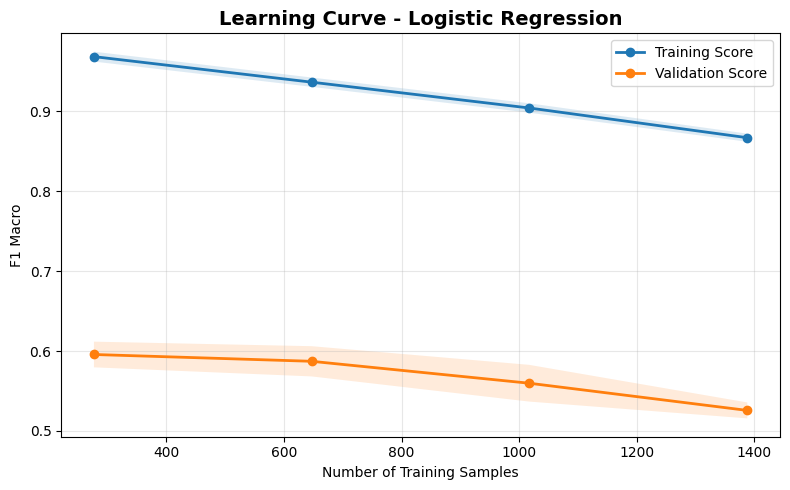


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1791    0.1622    0.1702        74
Consult - History and Phy.     0.8100    0.7864    0.7980       103
                Orthopedic     0.1867    0.1972    0.1918        71
                 Radiology     0.4426    0.4909    0.4655        55
                   Surgery     0.6560    0.6560    0.6560       218

                  accuracy                         0.5317       521
                 macro avg     0.4549    0.4585    0.4563       521
              weighted avg     0.5322    0.5317    0.5317       521



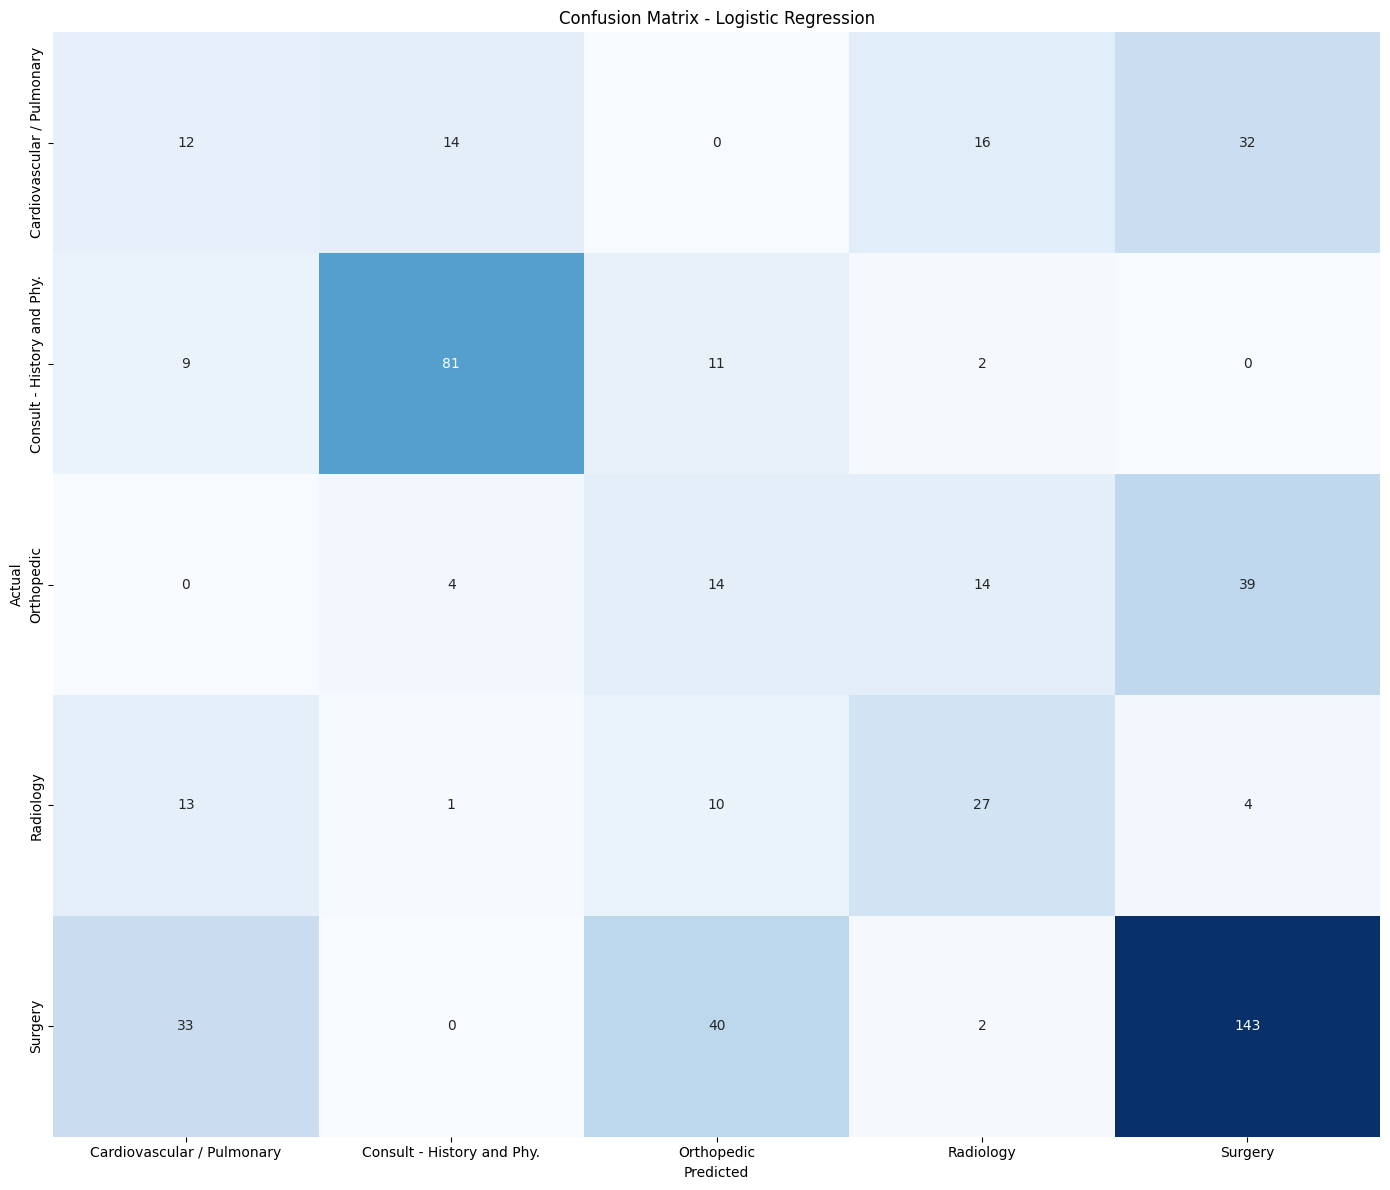

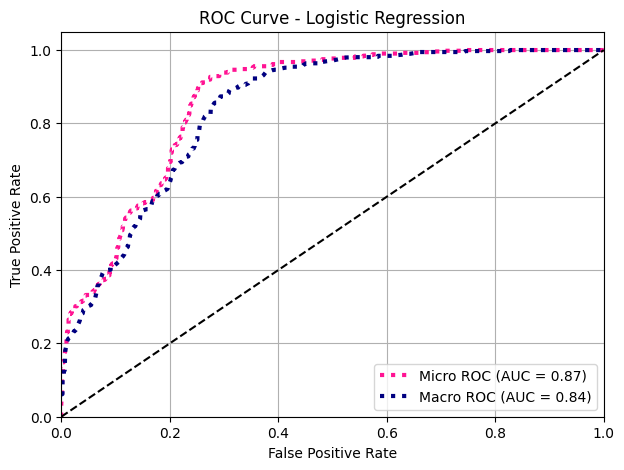


================ Linear SVM ================


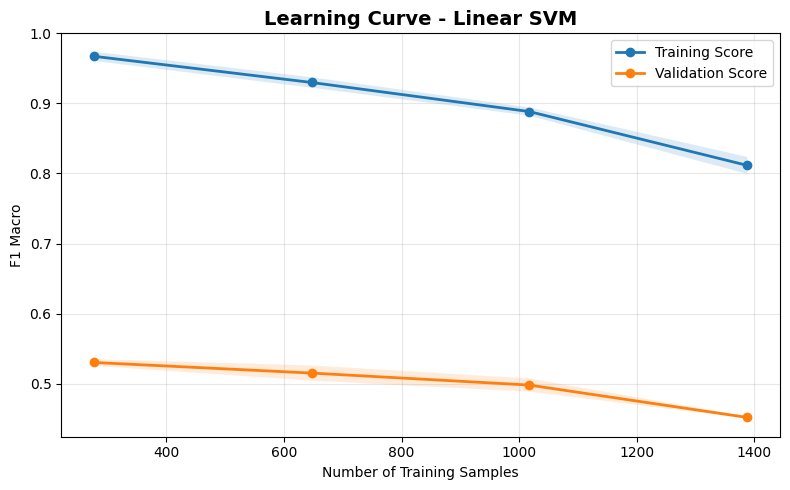


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1489    0.0946    0.1157        74
Consult - History and Phy.     0.7757    0.8058    0.7905       103
                Orthopedic     0.1702    0.1127    0.1356        71
                 Radiology     0.3929    0.4000    0.3964        55
                   Surgery     0.6591    0.7982    0.7220       218

                  accuracy                         0.5643       521
                 macro avg     0.4294    0.4423    0.4320       521
              weighted avg     0.5150    0.5643    0.5351       521



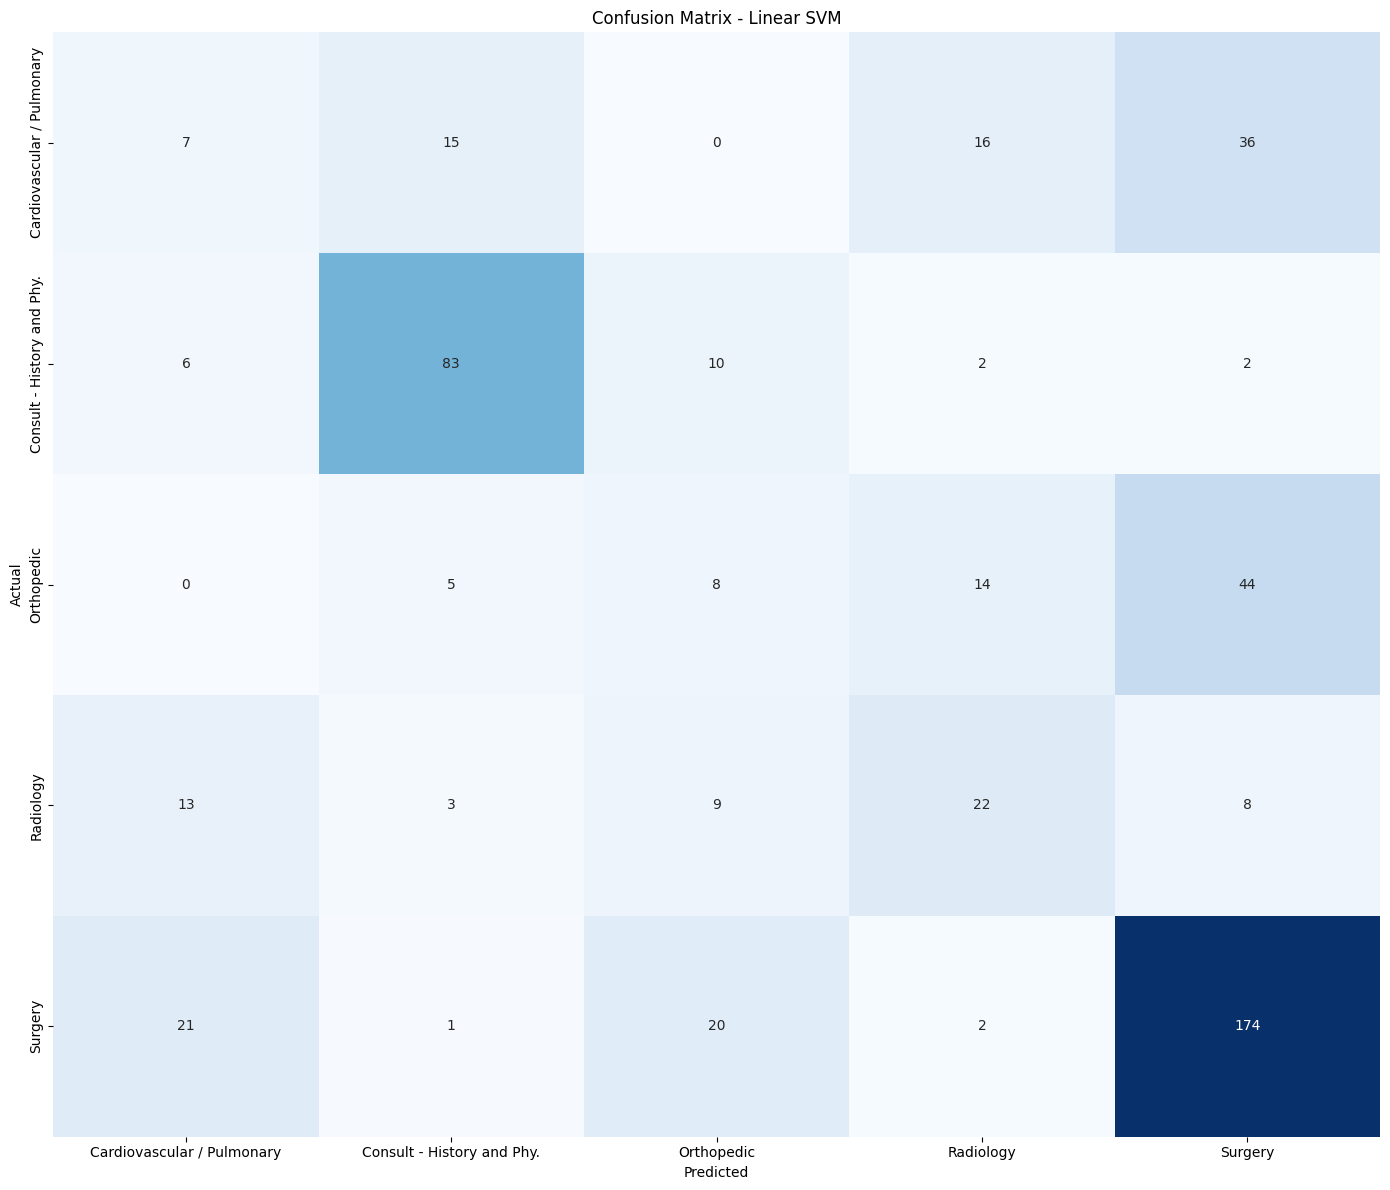

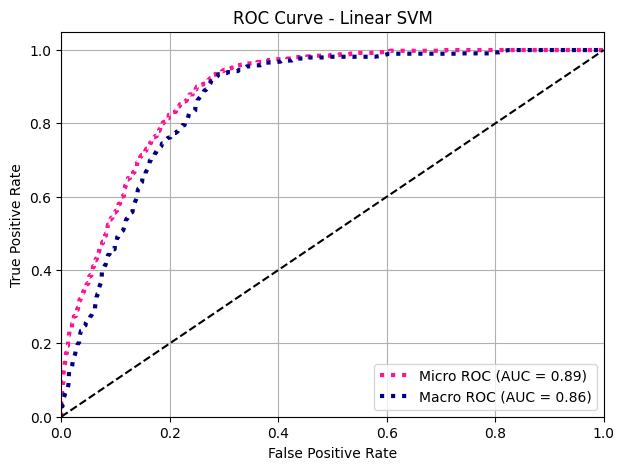


================ Random Forest ================


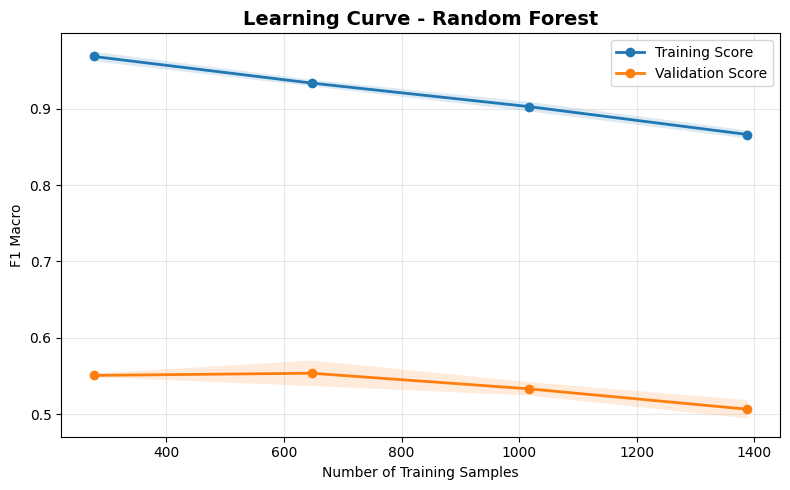


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.0909    0.0676    0.0775        74
Consult - History and Phy.     0.7391    0.8252    0.7798       103
                Orthopedic     0.1159    0.1127    0.1143        71
                 Radiology     0.4366    0.5636    0.4921        55
                   Surgery     0.6588    0.6376    0.6480       218

                  accuracy                         0.5144       521
                 macro avg     0.4083    0.4413    0.4223       521
              weighted avg     0.4966    0.5144    0.5038       521



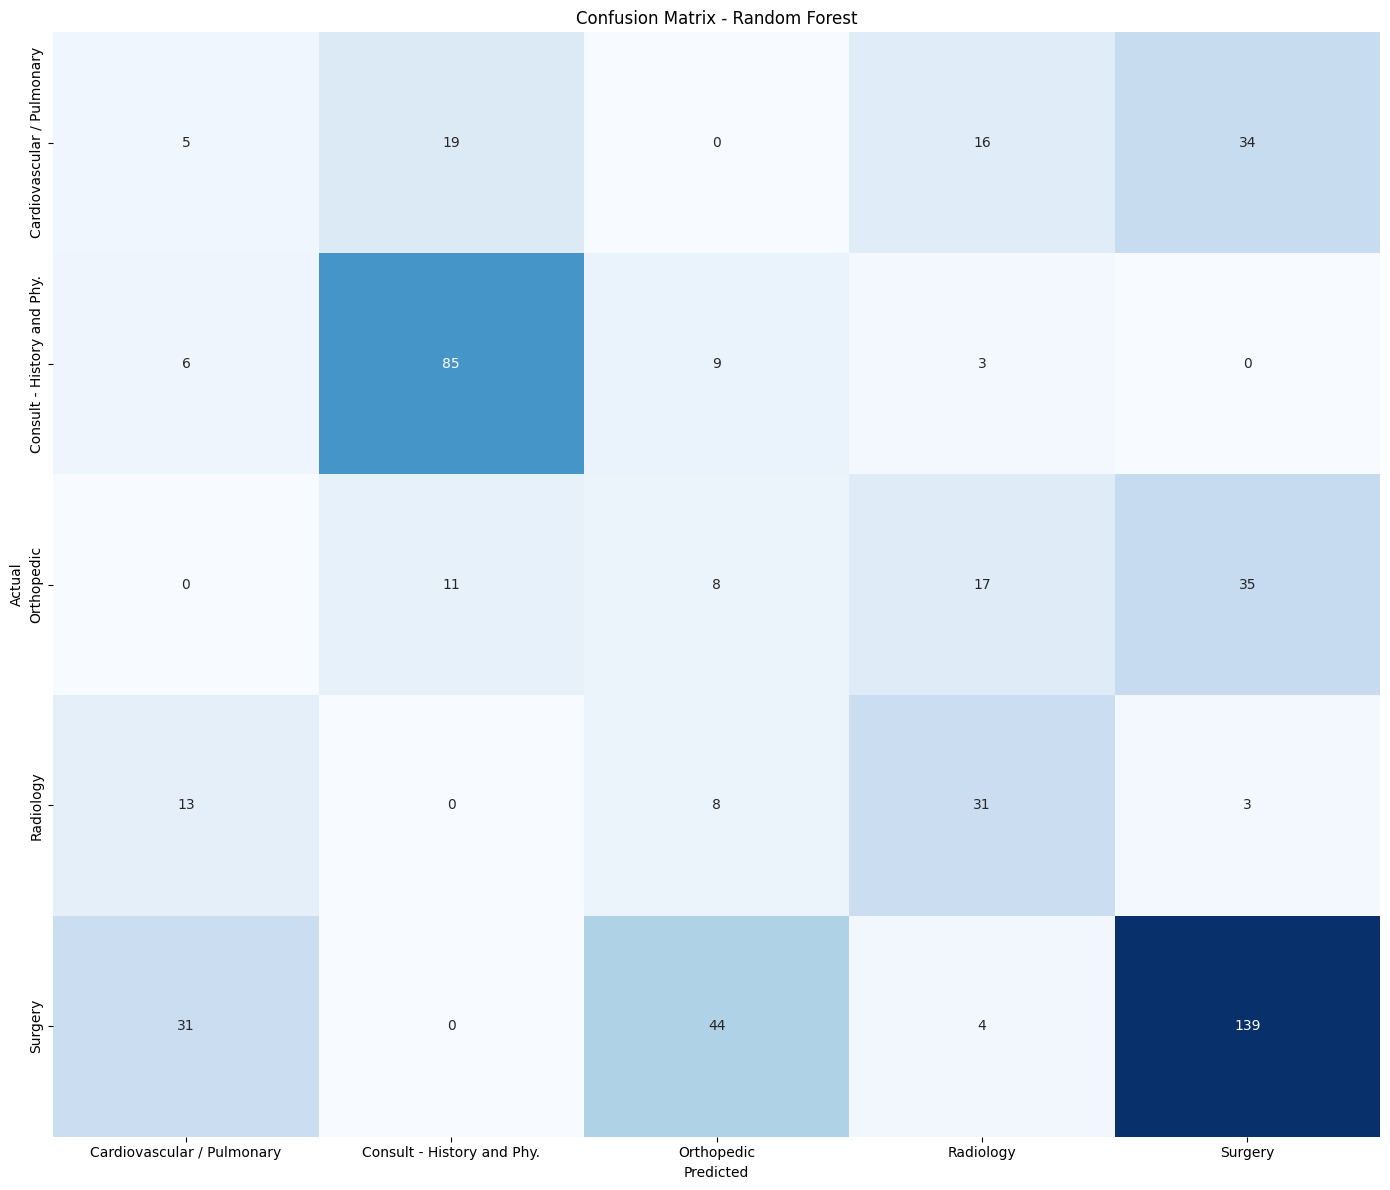

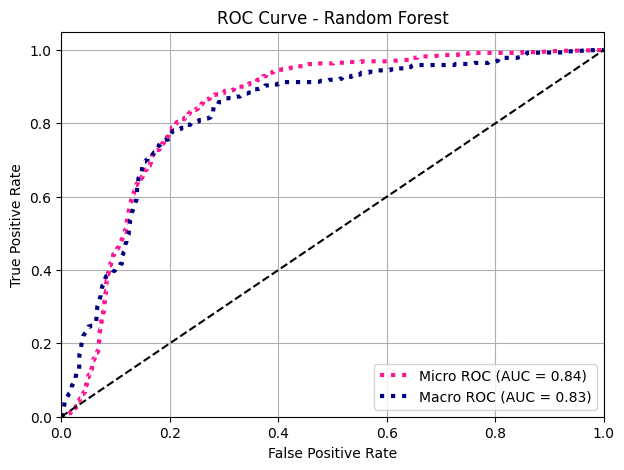


================ XGBoost ================


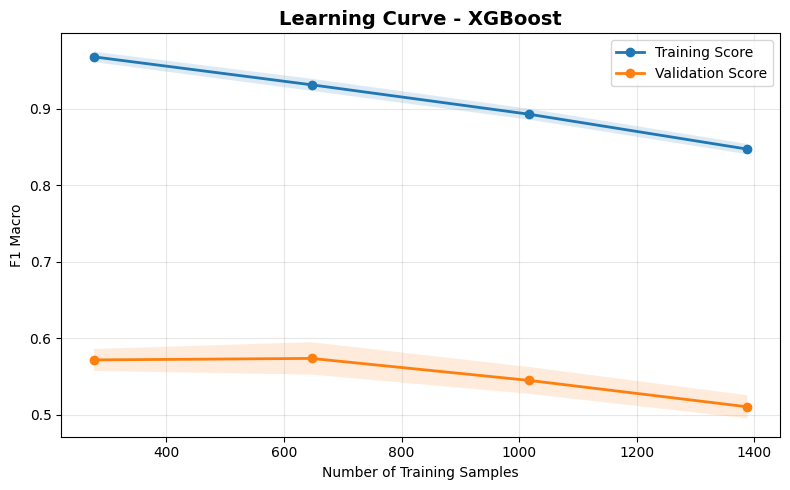


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1905    0.1622    0.1752        74
Consult - History and Phy.     0.7455    0.7961    0.7700       103
                Orthopedic     0.1159    0.1127    0.1143        71
                 Radiology     0.4237    0.4545    0.4386        55
                   Surgery     0.6636    0.6697    0.6667       218

                  accuracy                         0.5240       521
                 macro avg     0.4278    0.4390    0.4329       521
              weighted avg     0.5126    0.5240    0.5179       521



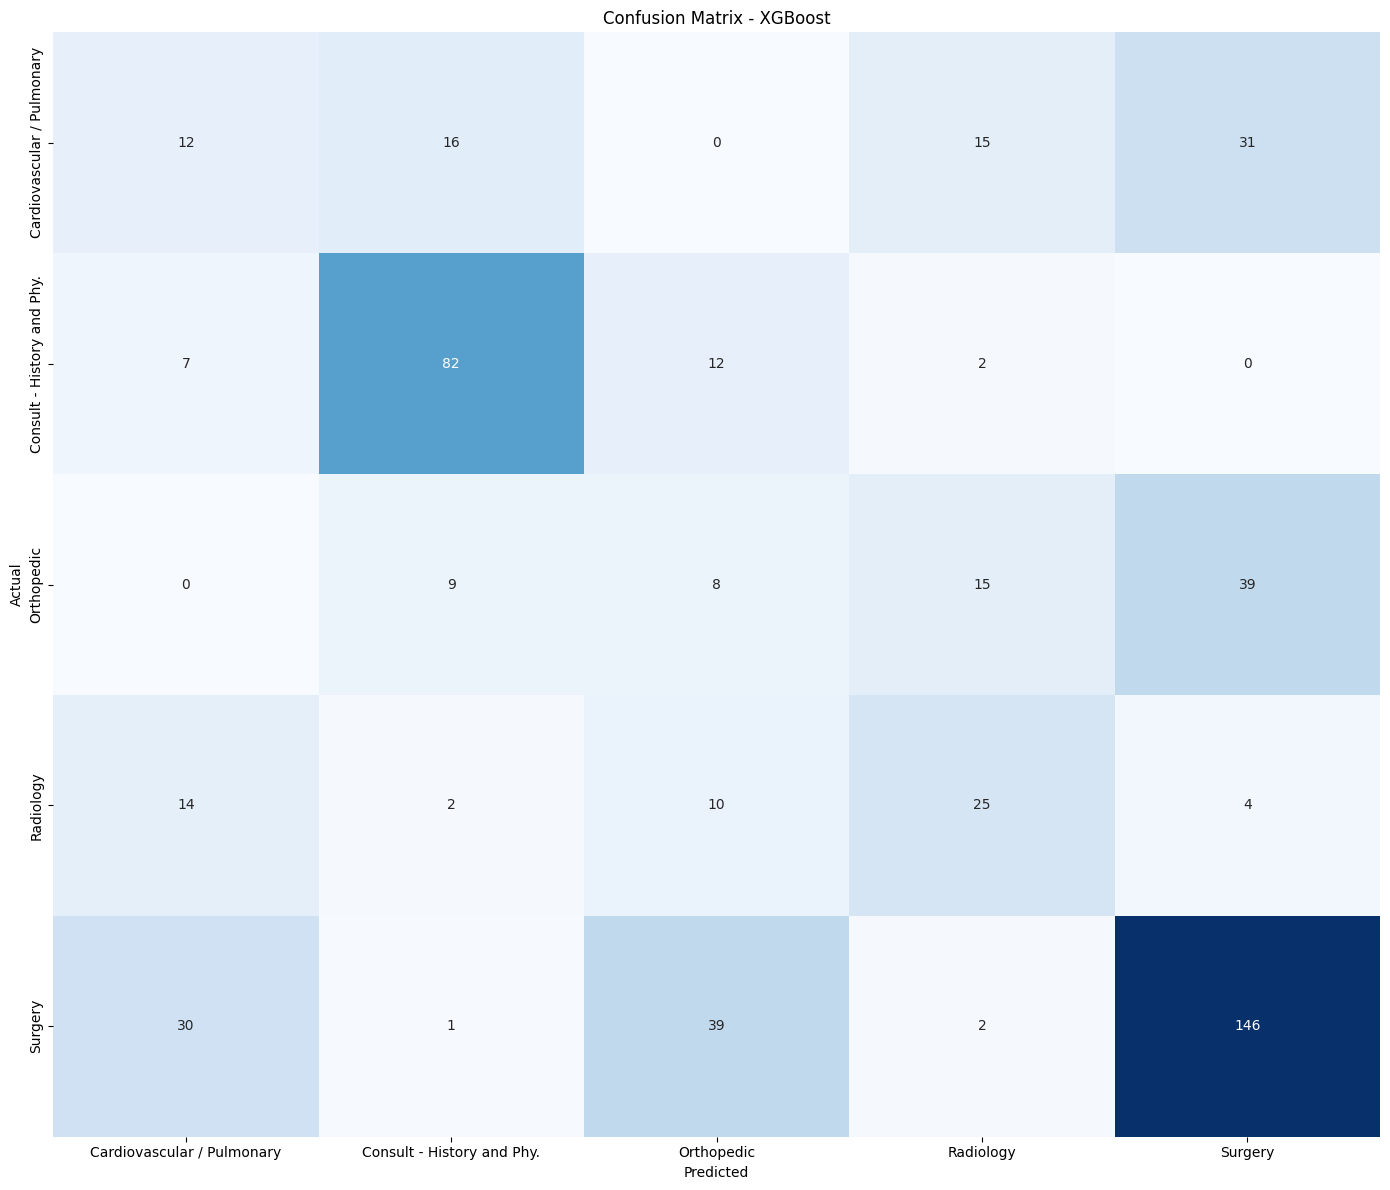

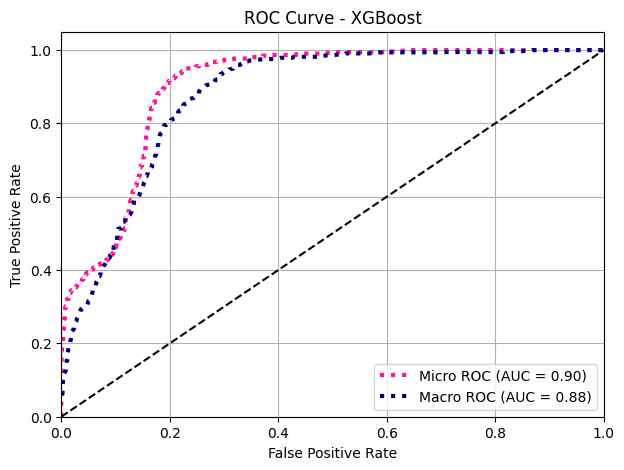


================ LightGBM ================


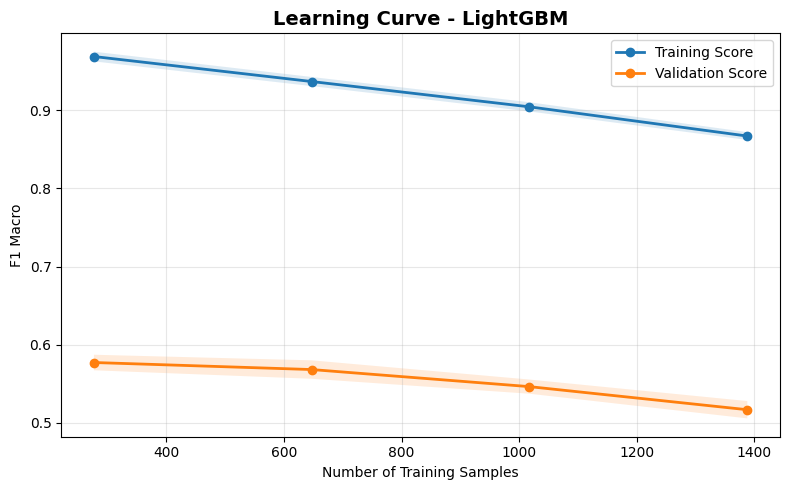


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1500    0.1216    0.1343        74
Consult - History and Phy.     0.7885    0.7961    0.7923       103
                Orthopedic     0.1143    0.1127    0.1135        71
                 Radiology     0.4571    0.5818    0.5120        55
                   Surgery     0.6498    0.6468    0.6483       218

                  accuracy                         0.5221       521
                 macro avg     0.4319    0.4518    0.4401       521
              weighted avg     0.5129    0.5221    0.5165       521



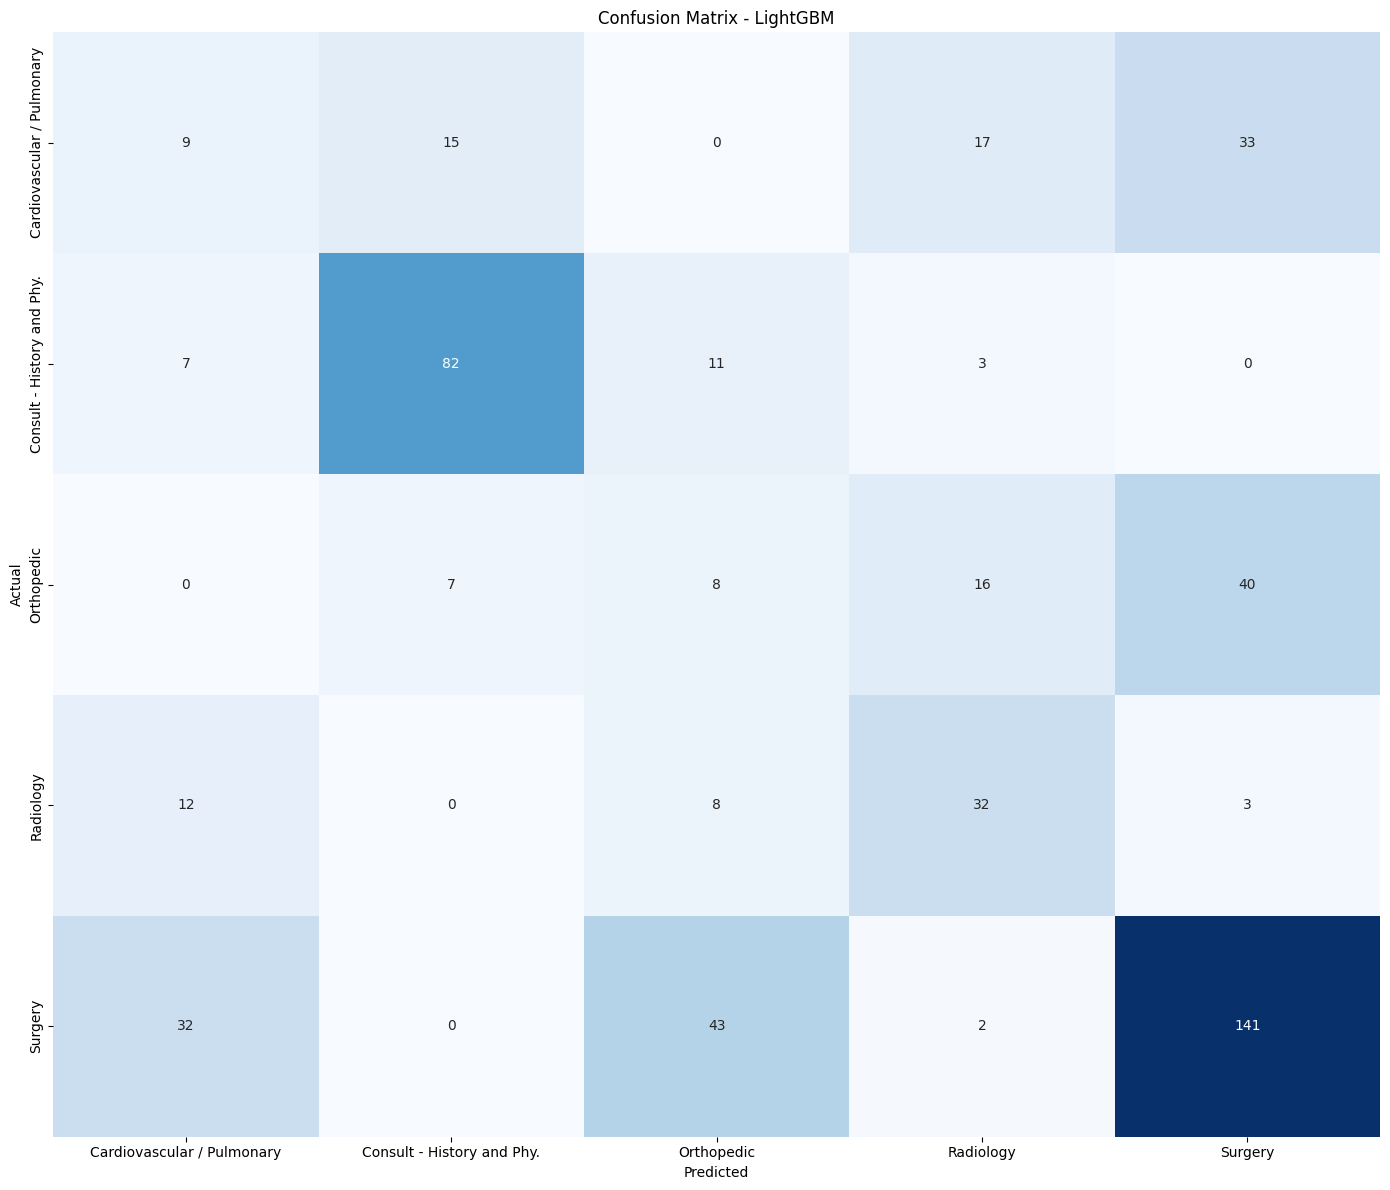

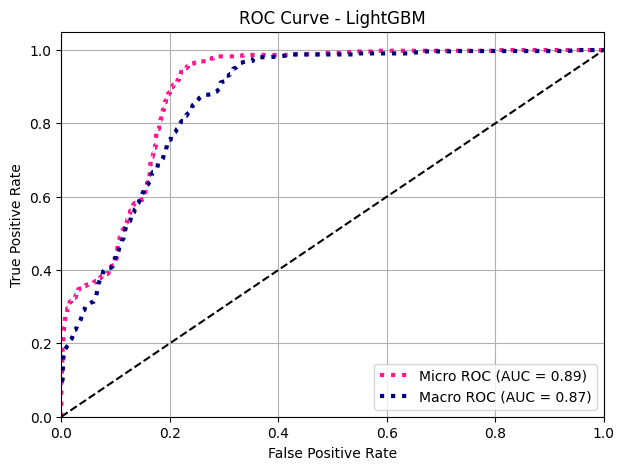


================ Stacking ================
Skip Learning Curve for Stacking (too computationally expensive).

Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.5075    0.4595    0.4823        74
Consult - History and Phy.     0.8384    0.8058    0.8218       103
                Orthopedic     0.3594    0.3239    0.3407        71
                 Radiology     0.5645    0.6364    0.5983        55
                   Surgery     0.7686    0.8073    0.7875       218

                  accuracy                         0.6737       521
                 macro avg     0.6077    0.6066    0.6061       521
              weighted avg     0.6680    0.6737    0.6701       521



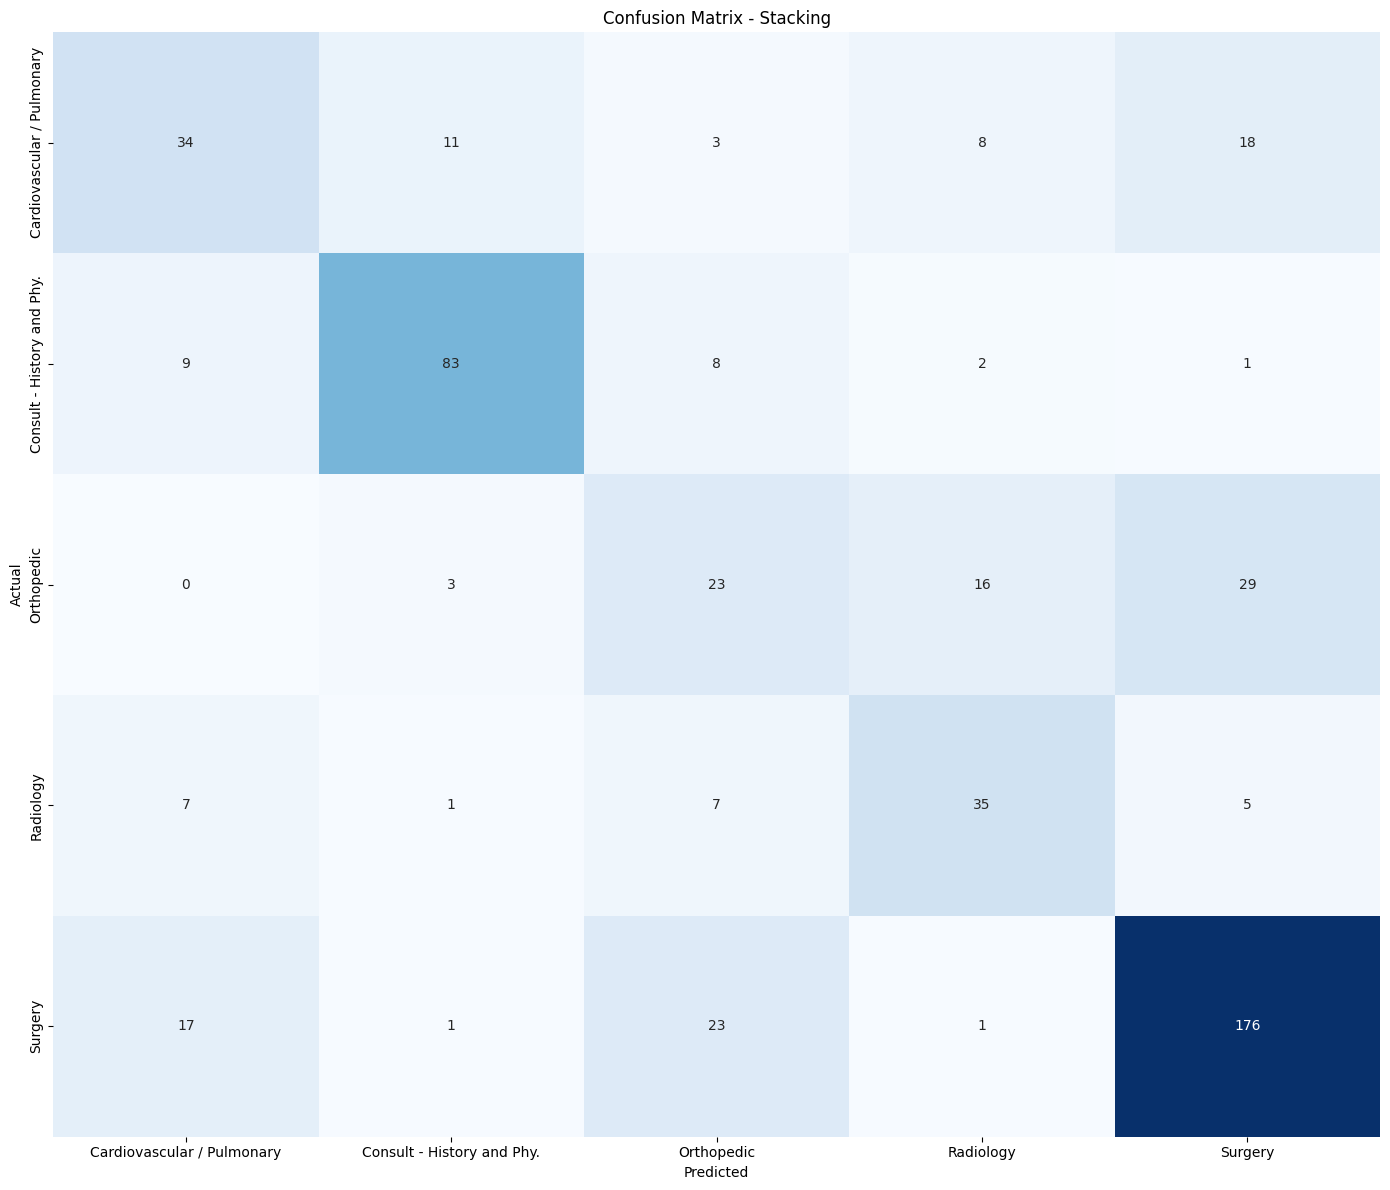

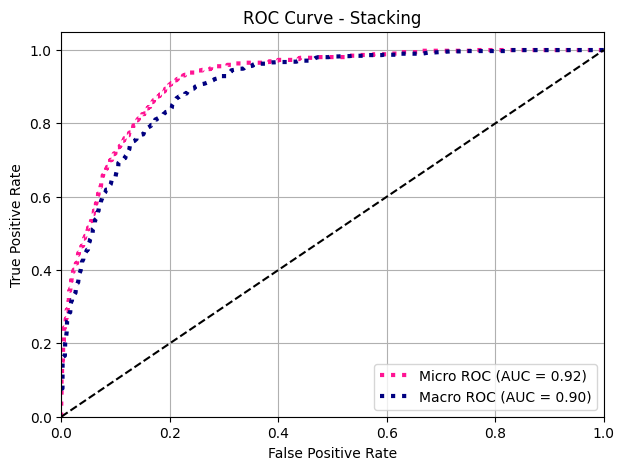


================ FINAL RESULT ================

                     Accuracy  Precision  Recall  F1-score
Model                                                     
Stacking               0.6737     0.6077  0.6066    0.6061
Linear SVM             0.5643     0.4294  0.4423    0.4320
Logistic Regression    0.5317     0.4549  0.4585    0.4563
XGBoost                0.5240     0.4278  0.4390    0.4329
LightGBM               0.5221     0.4319  0.4518    0.4401
Random Forest          0.5144     0.4083  0.4413    0.4223

 Mô hình tốt nhất: Stacking


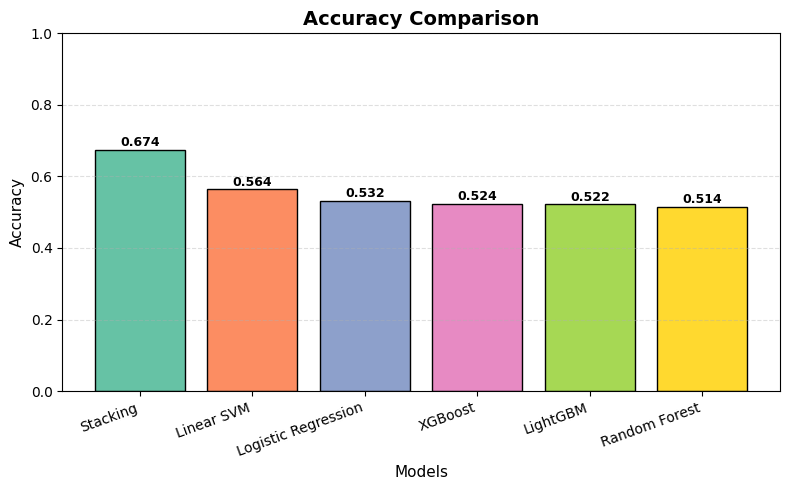

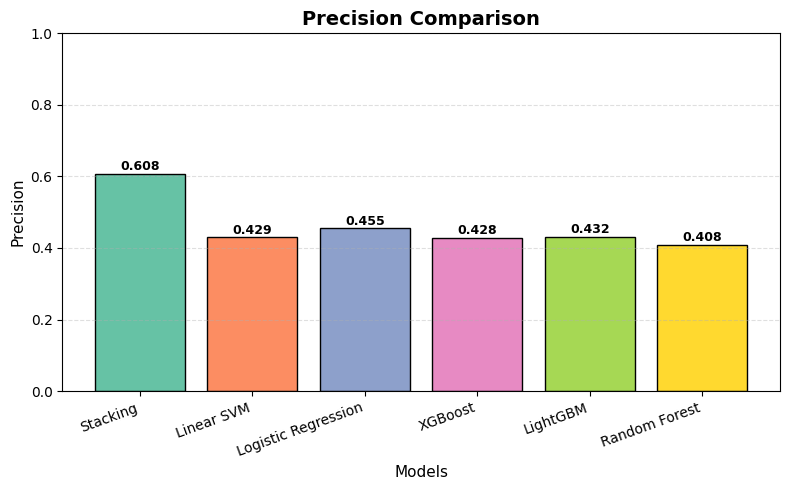

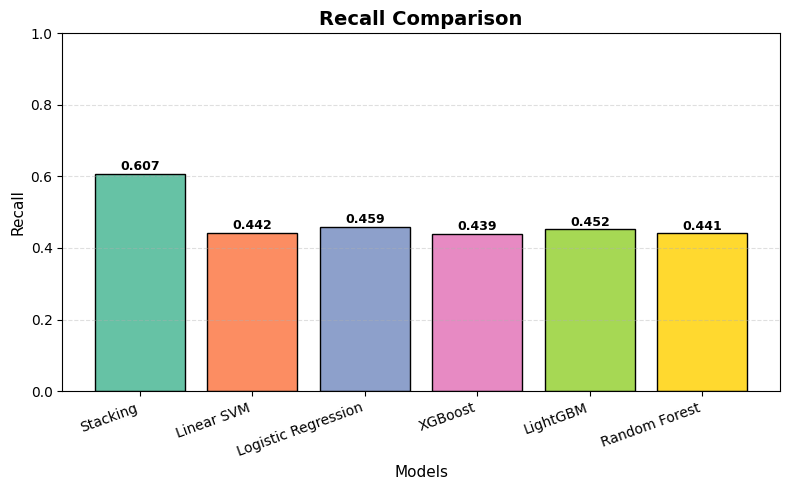

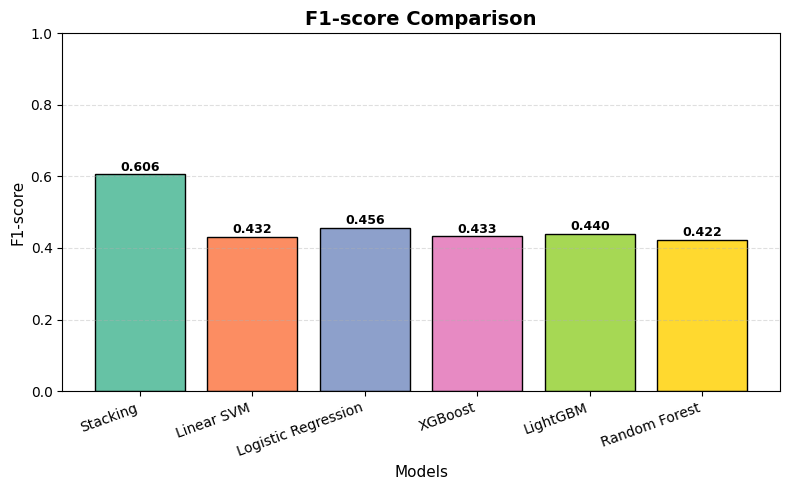

In [242]:
from sklearn.feature_extraction.text import CountVectorizer

bow = CountVectorizer(
    max_features=20000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.90,
    stop_words="english",
    dtype=np.float32
)

results_dfb, best_modelb, allb_pipelines = evaluate_all_models(
    X_train,
    y_train_encoded,
    X_test,
    y_test_encoded,
    vectorizer=bow,
    le=label_encoder
)
plot_metrics_bar(results_dfb)

### 📊 ĐÁNH GIÁ KẾT QUẢ MÔ HÌNH (FINAL RESULT)

---

🏆 1. Kết quả nổi bật
* **Stacking vượt trội tuyệt đối:** Mô hình **Stacking Classifier** đạt kết quả cao nhất trên mọi chỉ số đánh giá, bỏ xa các mô hình đơn lẻ:
  * **Accuracy:** **67.18%** (cao hơn mô hình xếp thứ hai là Linear SVM tới **~10.8%**).
  * **Precision:** **60.56%** | **Recall:** **60.49%** | **F1-score:** **60.42%**.
* **Nhóm mô hình đơn (Base Models):**
  * **Linear SVM** là mô hình đơn lẻ tốt nhất về tổng thể (Accuracy: **56.43%**).
  * **Logistic Regression** có sự cân bằng F1-score tốt nhất trong nhóm đơn lẻ (F1-score: **45.63%**).
  * Các mô hình dựa trên Cây quyết định (**XGBoost, LightGBM, Random Forest**) cho kết quả thấp hơn (Accuracy dao động từ **51.44% - 52.40%**).


🎯 3. Kết luận
> **Stacking Classifier** là mô hình **tối ưu nhất** cho bài toán phân loại bệnh án y tế hiện tại.

### 📈 PHÂN TÍCH ROC CURVE (STACKING VS RANDOM FOREST)

---

📊 1. Bảng so sánh chỉ số AUC (Area Under Curve)

| Chỉ số AUC | 🥞 Stacking Classifier | 🌲 Random Forest | Mức chênh lệch |
| :--- | :---: | :---: | :---: |
| **Micro ROC AUC** | **0.92** | 0.84 | ➕ **0.08** (~9.5%) |
| **Macro ROC AUC** | **0.90** | 0.83 | ➕ **0.07** (~8.4%) |

---

 🔍 2. Nhận xét

🥞 **Stacking Classifier:**
* **Độ cong lý tưởng:** Đường cong tiệm cận nhanh về góc trên bên trái $(FPR \rightarrow 0, TPR \rightarrow 1)$, cho thấy khả năng phân biệt lớp cực kỳ chính xác ở các ngưỡng xác suất khác nhau.
* **Chỉ số xuất sắc:** Cả **Micro AUC (0.92)** và **Macro AUC (0.90)** đều đạt ngưỡng cao ( $\ge 0.90$ ), chứng minh mô hình phân loại tốt trên **toàn bộ dữ liệu** lẫn **từng lớp riêng biệt**.

🌲 **Random Forest:**
* **Độ dốc thấp hơn:** Đường cong đi lên chậm hơn, có nhiều đoạn gấp khúc (võng xuống), cho thấy tỷ lệ báo động giả (*False Positive Rate*) cao hơn so với Stacking ở cùng một mức độ nhạy (*True Positive Rate*).
* **Hiệu năng trung bình:** Đạt **Micro AUC (0.84)** và **Macro AUC (0.83)**.

---

🎯 3. Kết luận

> **Mô hình Stacking tốt hơn hoàn toàn Random Forest về khả năng phân loại đa lớp** (diện tích dưới đường cong AUC lớn hơn đáng kể). 

### ⚠️ **ĐÁNH GIÁ LEARNING CURVE OVERFITTING NẶNG Ở CÁC MÔ HÌNH ĐƠN LẺ (BASE MODELS)**
> * **Hiện trạng:** Khoảng cách giữa Train (~90%) và Validation (~50%) rất lớn.
> * **Nguyên nhân gốc rễ:** Lệch số chiều/mẫu (*20,000 TF-IDF features* 🆚 *1,400 training samples*).

# TF-IDF + Evaluation

- evaluate_all_models(...) ->Huấn luyện và đánh giá tất cả các mô hình phân loại.
- selector=None -> Không sử dụng bước chọn đặc trưng (feature selection).
- le=label_encoder -> Dùng LabelEncoder để hiển thị tên chuyên khoa thay vì nhãn số.


================ Logistic Regression ================


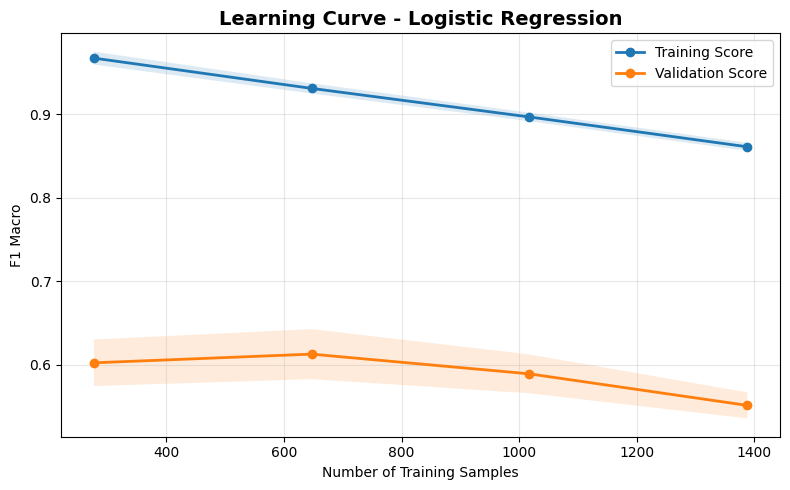


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.2429    0.2297    0.2361        74
Consult - History and Phy.     0.8058    0.8058    0.8058       103
                Orthopedic     0.2143    0.2535    0.2323        71
                 Radiology     0.4333    0.4727    0.4522        55
                   Surgery     0.6716    0.6284    0.6493       218

                  accuracy                         0.5393       521
                 macro avg     0.4736    0.4780    0.4751       521
              weighted avg     0.5498    0.5393    0.5439       521



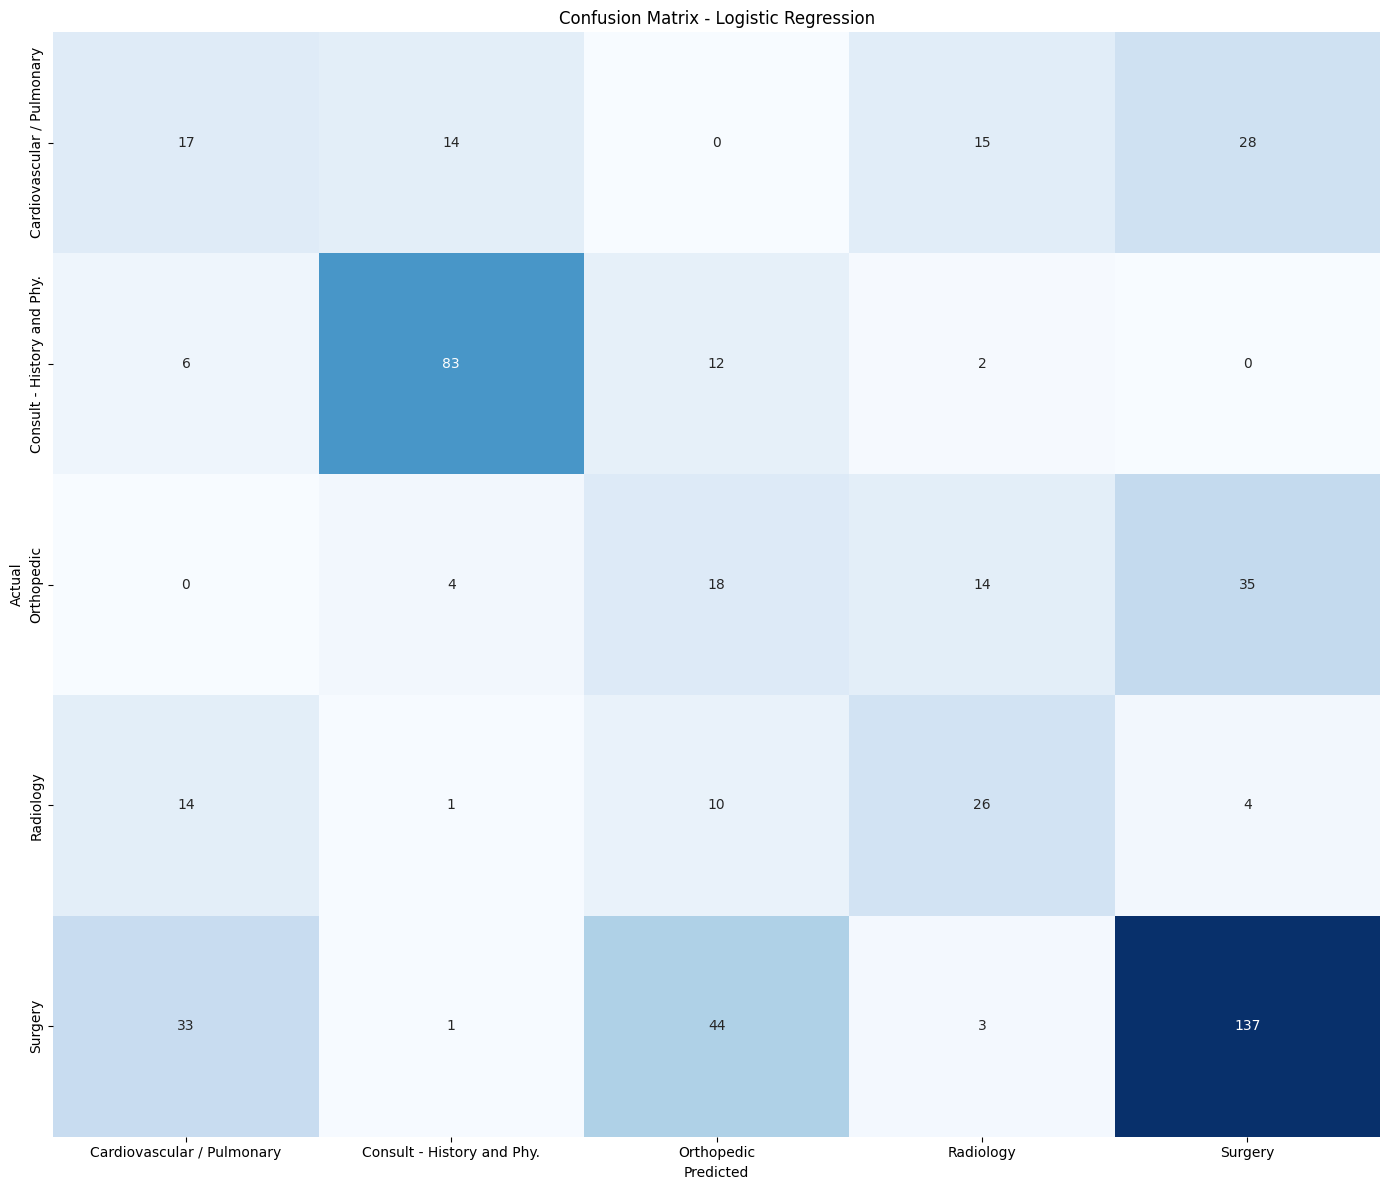

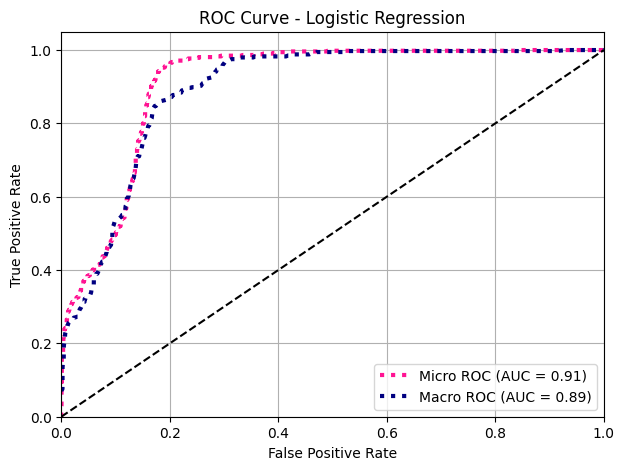


================ Linear SVM ================


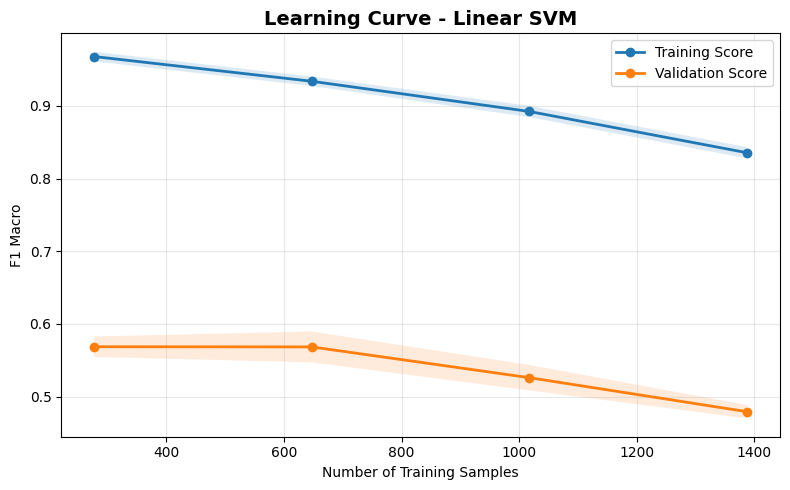


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1154    0.0811    0.0952        74
Consult - History and Phy.     0.7478    0.8350    0.7890       103
                Orthopedic     0.0755    0.0563    0.0645        71
                 Radiology     0.4333    0.4727    0.4522        55
                   Surgery     0.6473    0.7156    0.6797       218

                  accuracy                         0.5336       521
                 macro avg     0.4039    0.4321    0.4161       521
              weighted avg     0.4911    0.5336    0.5105       521



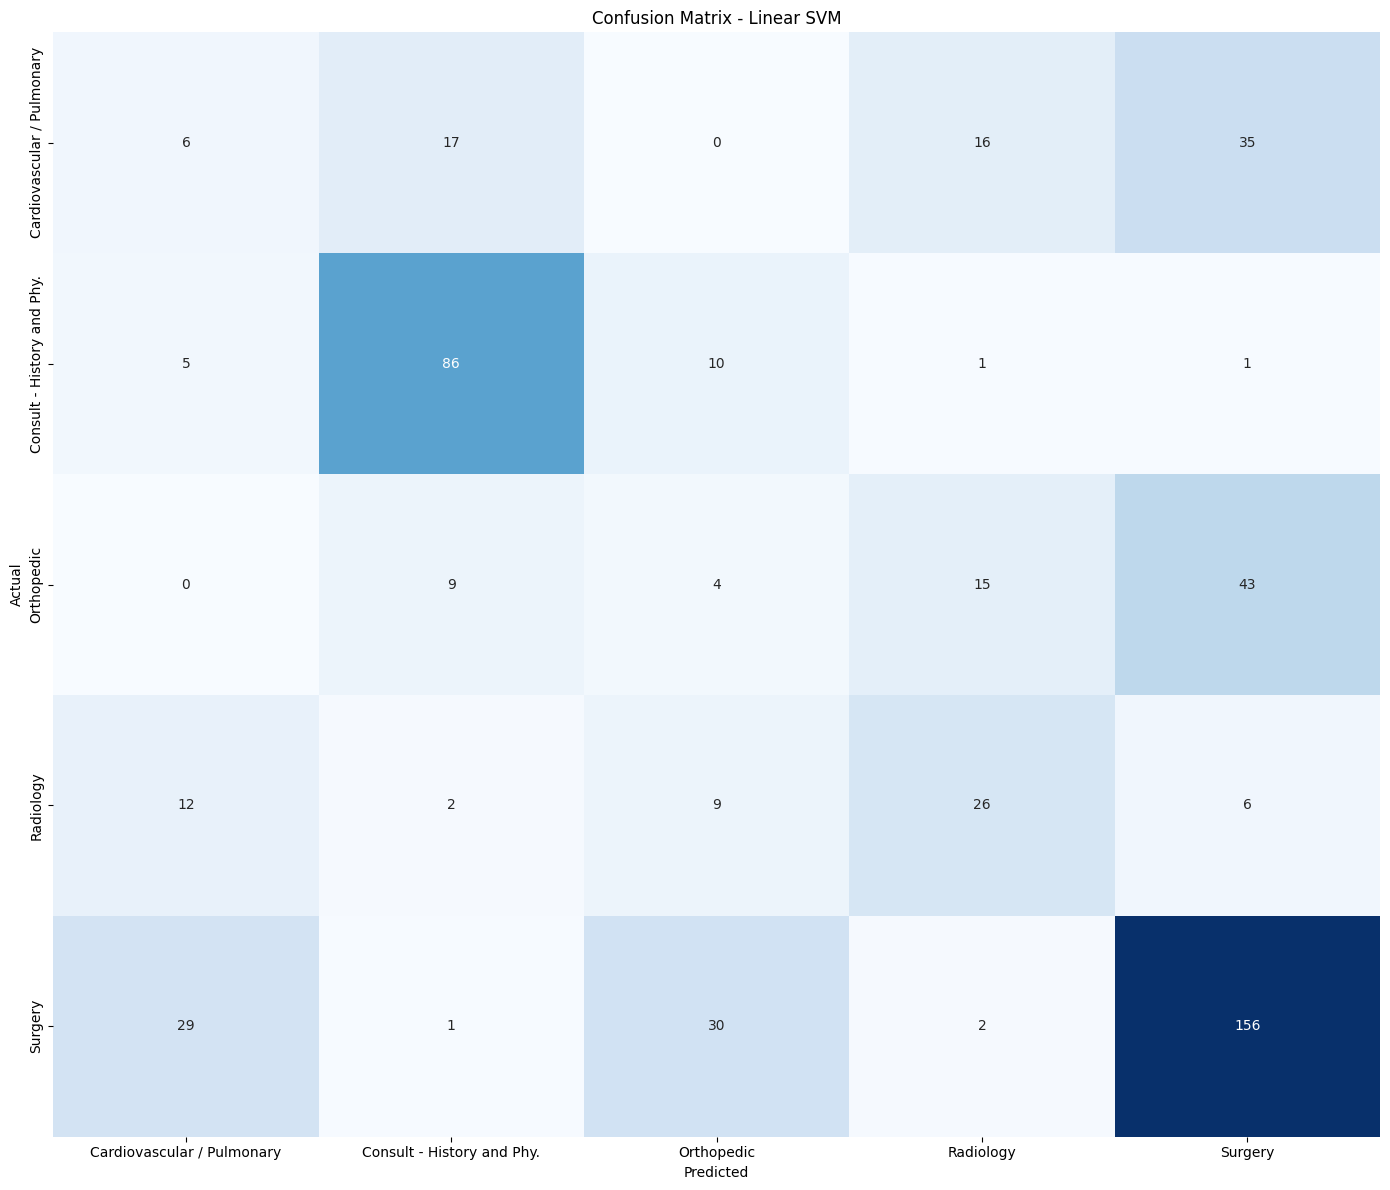

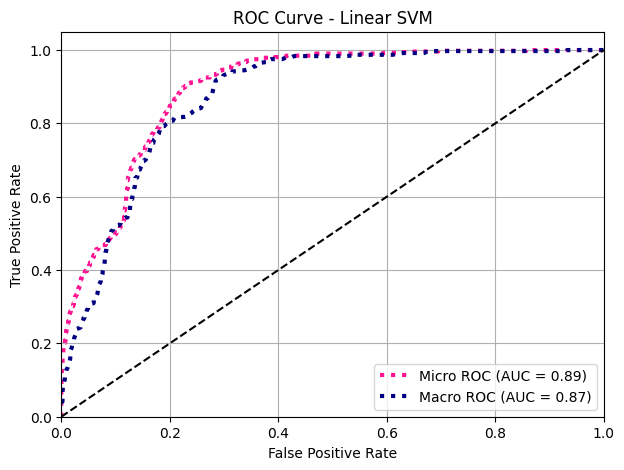


================ Random Forest ================


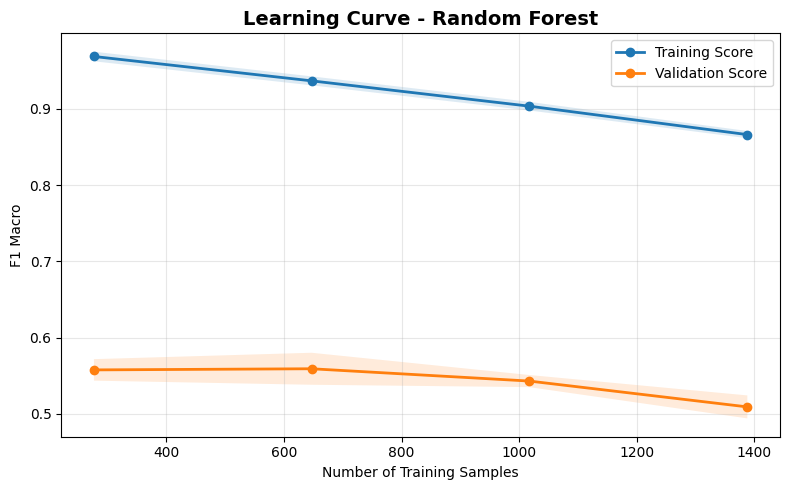


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1356    0.1081    0.1203        74
Consult - History and Phy.     0.7522    0.8252    0.7870       103
                Orthopedic     0.1061    0.0986    0.1022        71
                 Radiology     0.4306    0.5636    0.4882        55
                   Surgery     0.6588    0.6376    0.6480       218

                  accuracy                         0.5182       521
                 macro avg     0.4166    0.4466    0.4291       521
              weighted avg     0.5035    0.5182    0.5093       521



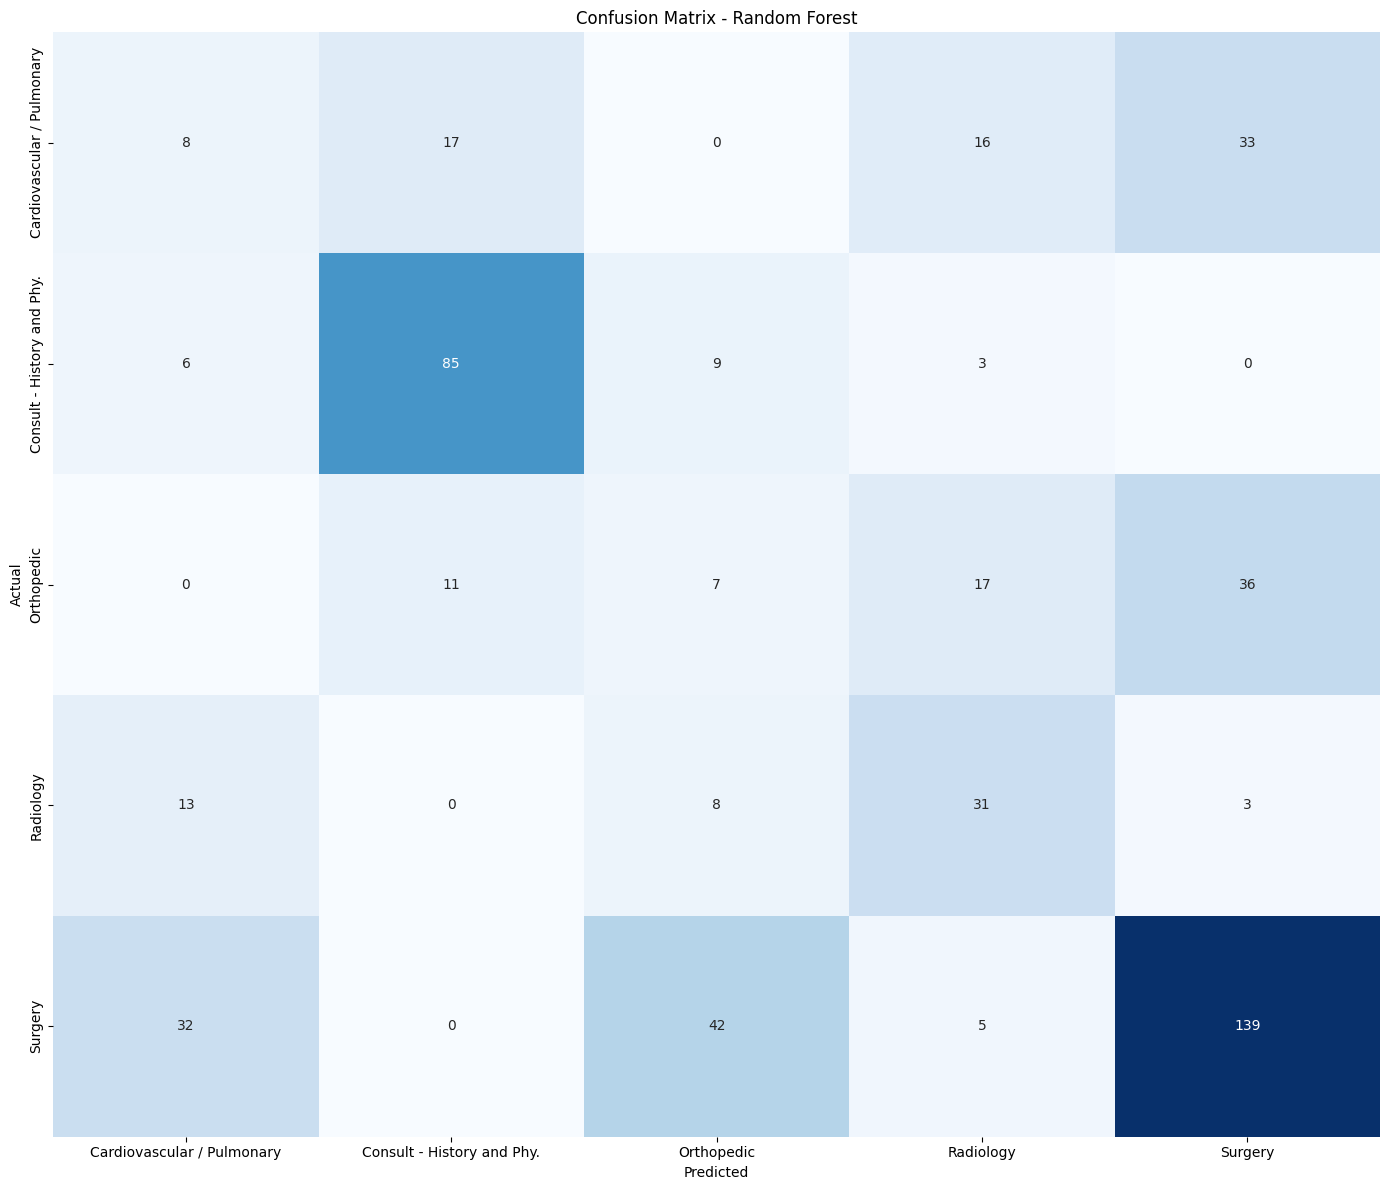

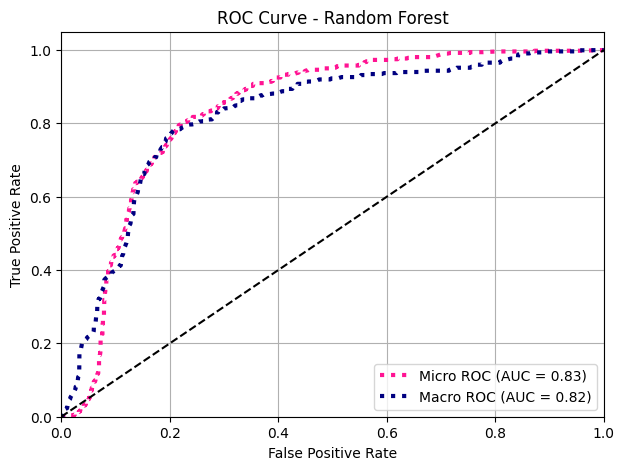


================ XGBoost ================


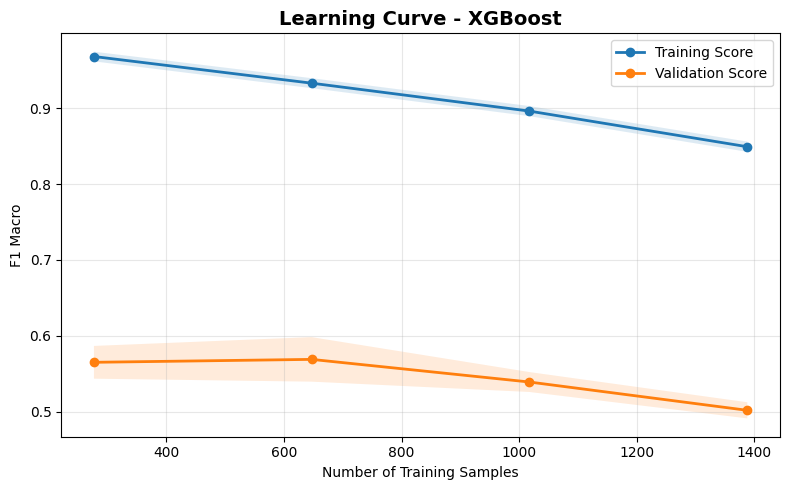


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1803    0.1486    0.1630        74
Consult - History and Phy.     0.7757    0.8058    0.7905       103
                Orthopedic     0.1449    0.1408    0.1429        71
                 Radiology     0.4444    0.5091    0.4746        55
                   Surgery     0.6652    0.6743    0.6697       218

                  accuracy                         0.5355       521
                 macro avg     0.4421    0.4557    0.4481       521
              weighted avg     0.5240    0.5355    0.5292       521



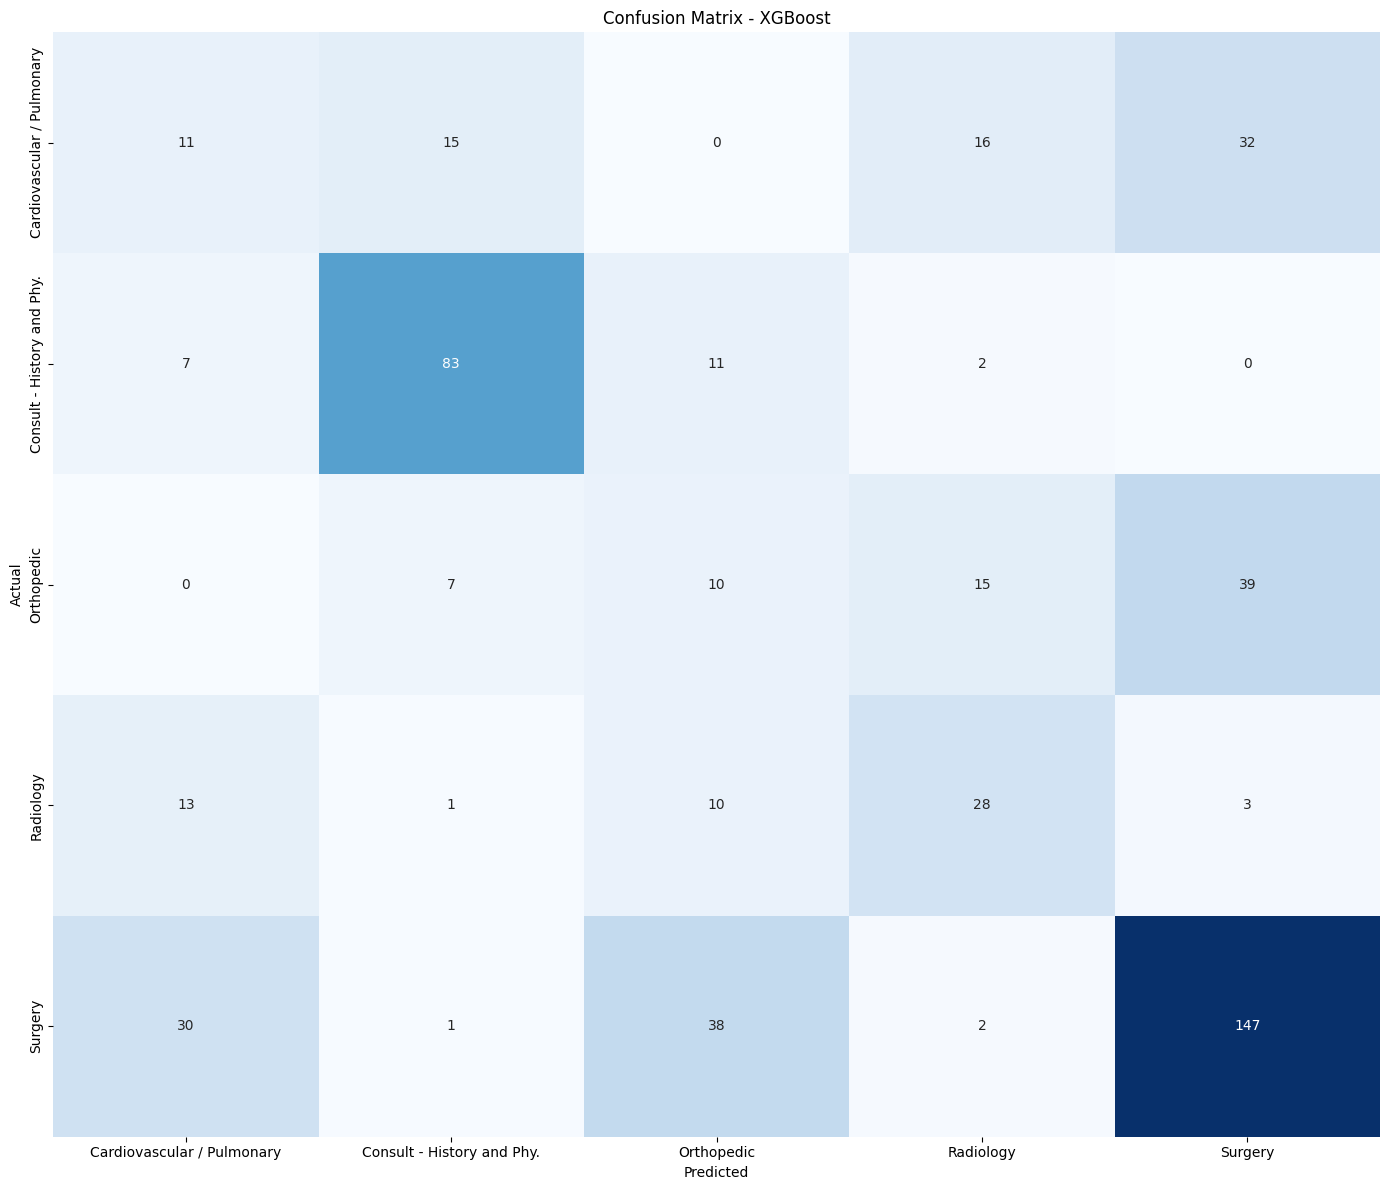

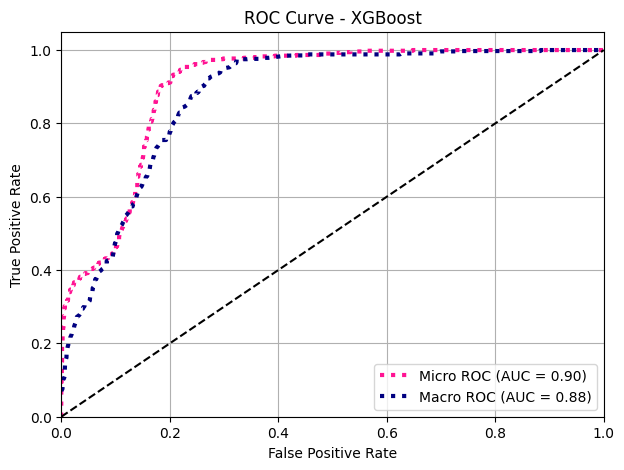


================ LightGBM ================


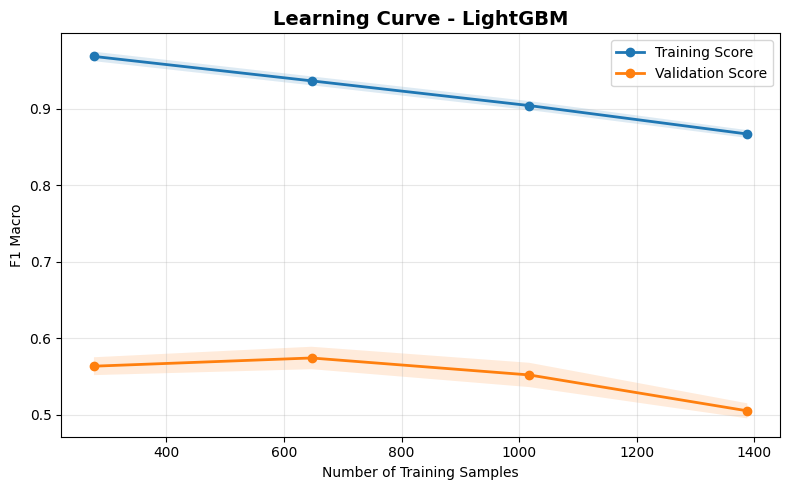


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1525    0.1216    0.1353        74
Consult - History and Phy.     0.8000    0.8155    0.8077       103
                Orthopedic     0.1343    0.1268    0.1304        71
                 Radiology     0.4559    0.5636    0.5041        55
                   Surgery     0.6577    0.6697    0.6636       218

                  accuracy                         0.5355       521
                 macro avg     0.4401    0.4595    0.4482       521
              weighted avg     0.5214    0.5355    0.5276       521



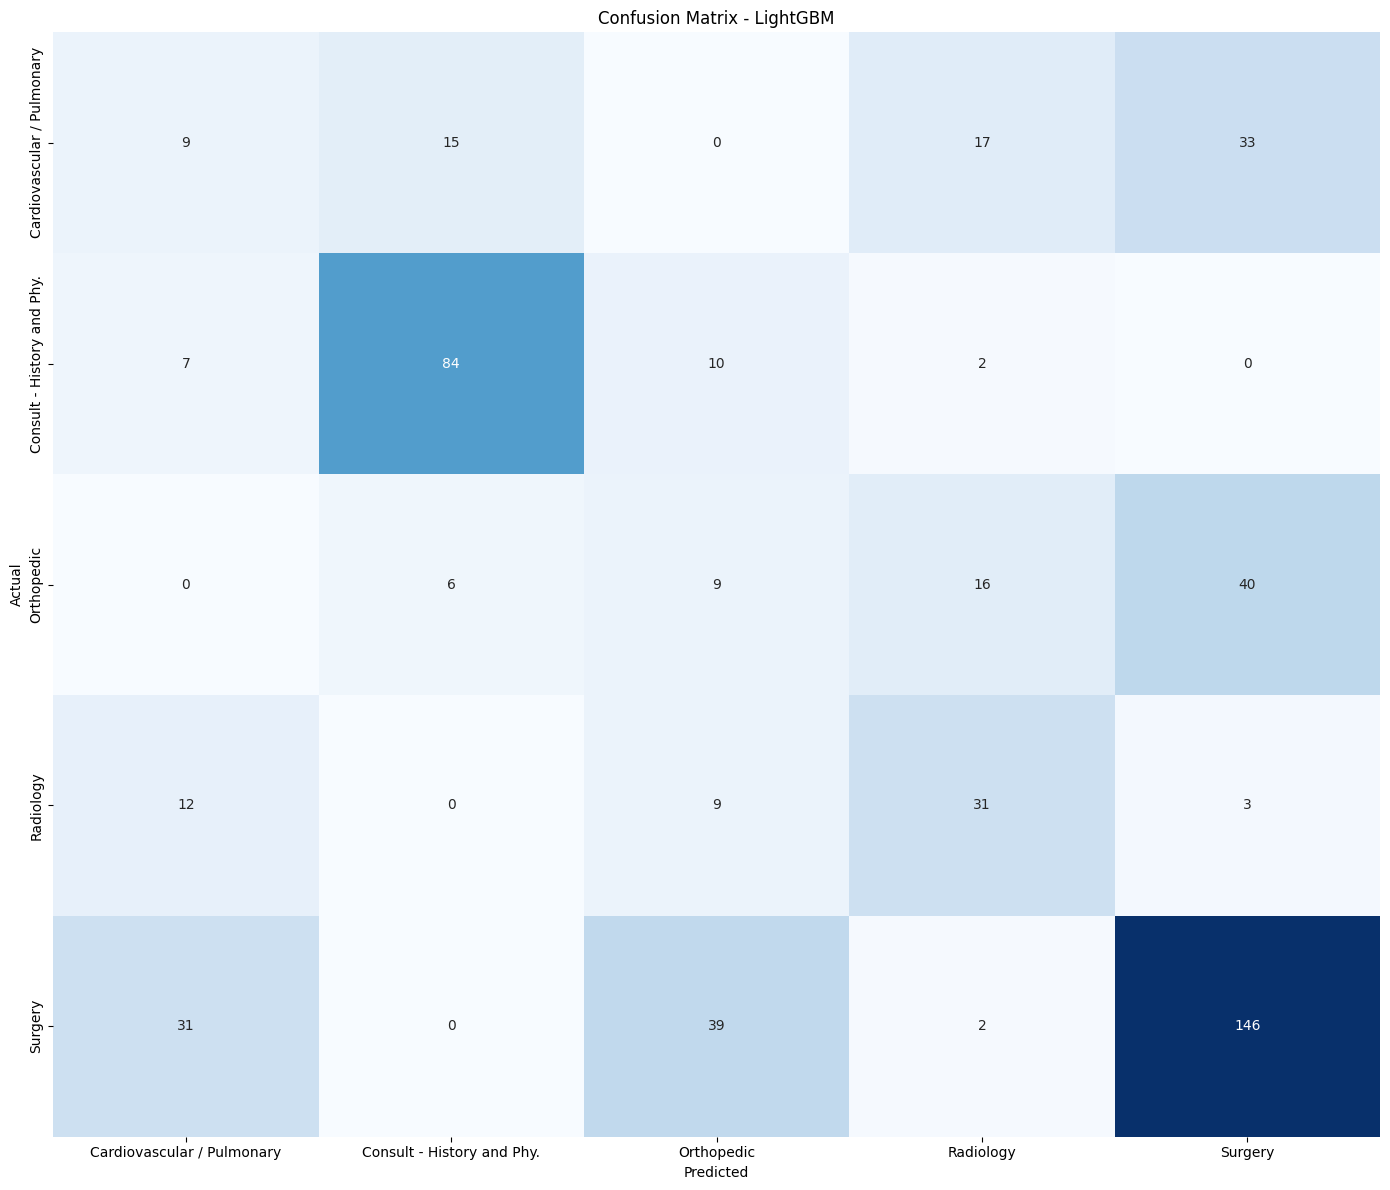

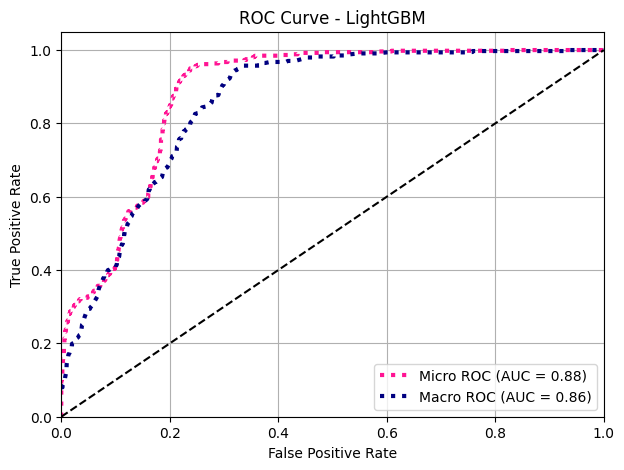


================ Stacking ================
Skip Learning Curve for Stacking (too computationally expensive).

Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.7969    0.6892    0.7391        74
Consult - History and Phy.     0.8559    0.9223    0.8879       103
                Orthopedic     0.6964    0.5493    0.6142        71
                 Radiology     0.6719    0.7818    0.7227        55
                   Surgery     0.8805    0.9128    0.8964       218

                  accuracy                         0.8196       521
                 macro avg     0.7803    0.7711    0.7720       521
              weighted avg     0.8167    0.8196    0.8156       521



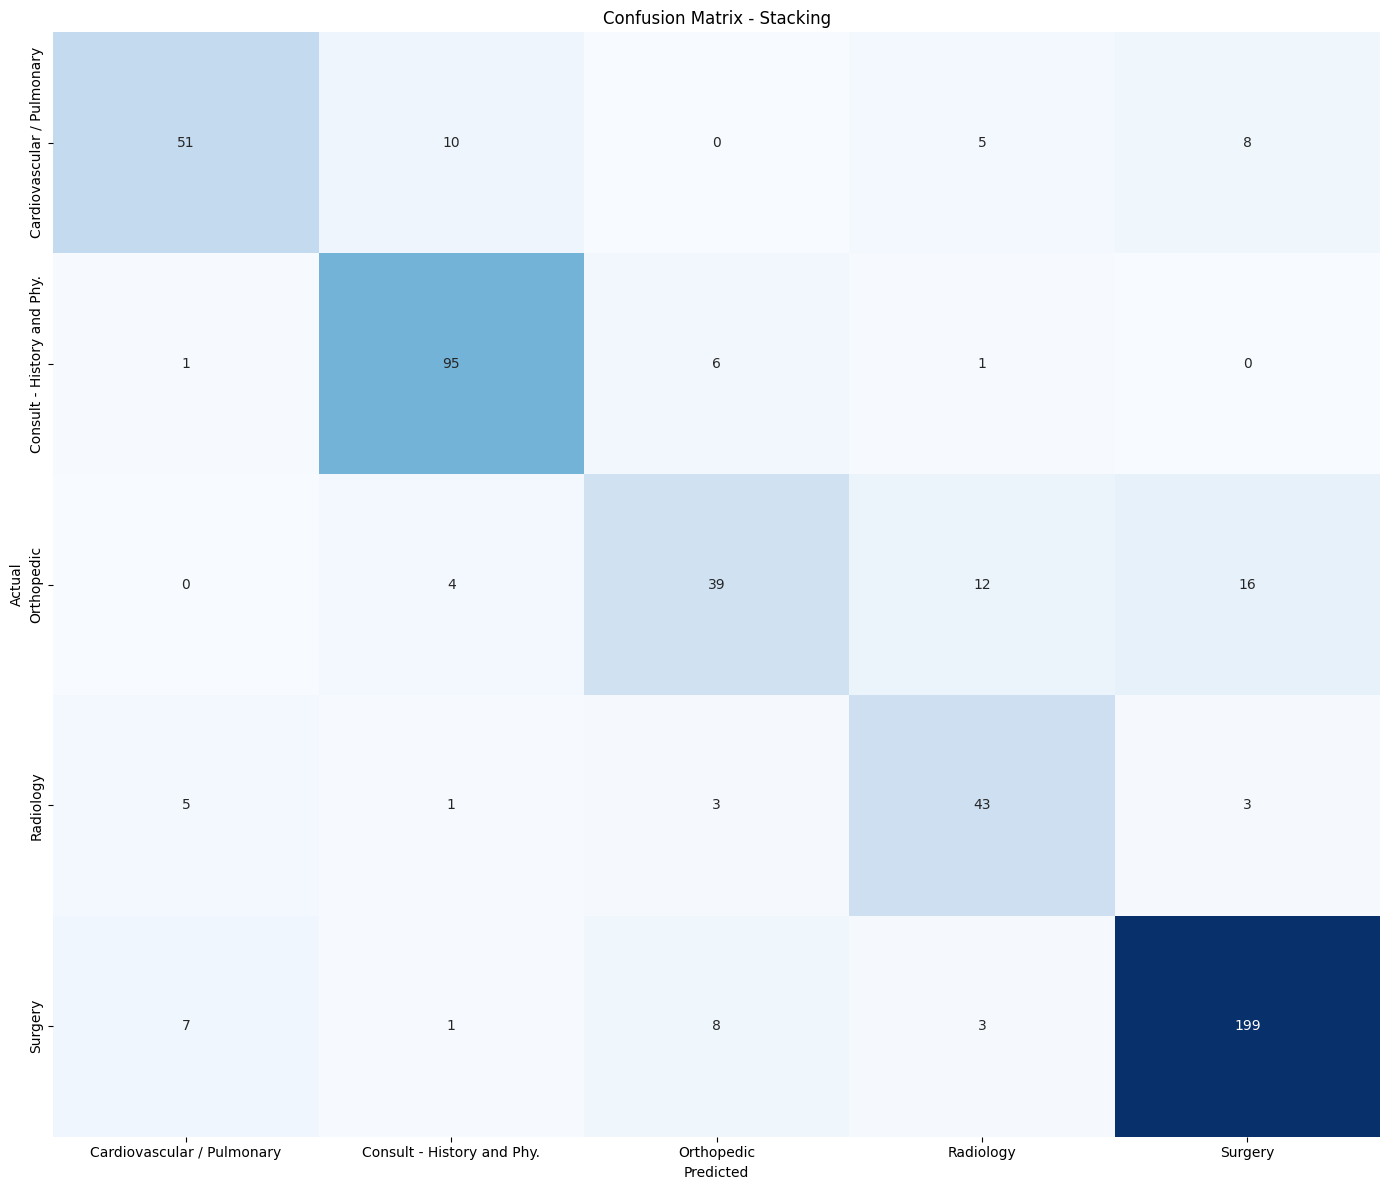

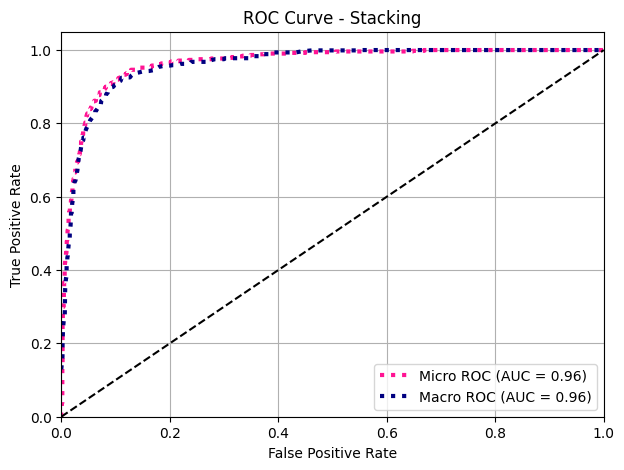


================ FINAL RESULT ================

                     Accuracy  Precision  Recall  F1-score
Model                                                     
Stacking               0.8196     0.7803  0.7711    0.7720
Logistic Regression    0.5393     0.4736  0.4780    0.4751
LightGBM               0.5355     0.4401  0.4595    0.4482
XGBoost                0.5355     0.4421  0.4557    0.4481
Linear SVM             0.5336     0.4039  0.4321    0.4161
Random Forest          0.5182     0.4166  0.4466    0.4291

 Mô hình tốt nhất: Stacking


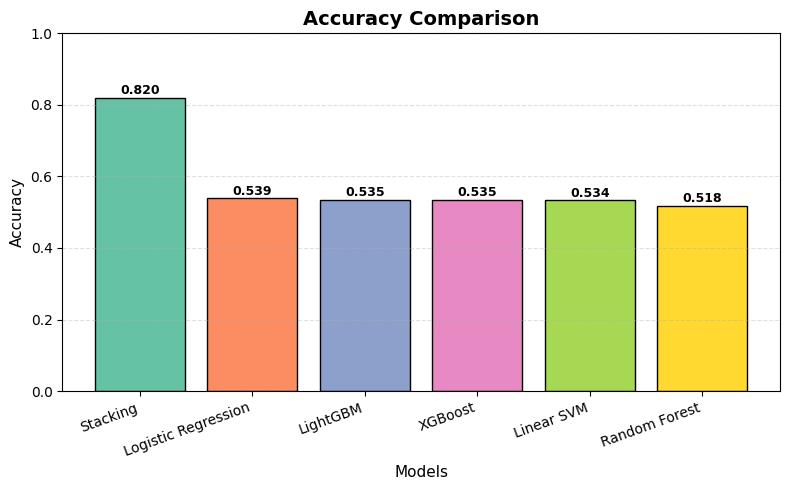

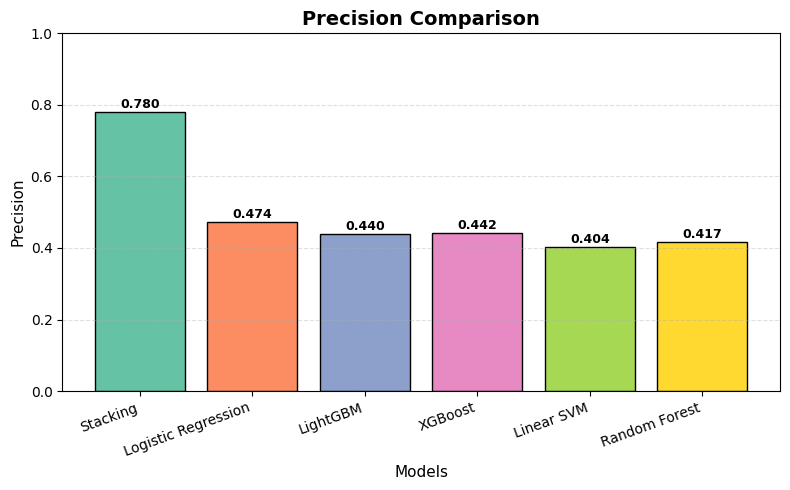

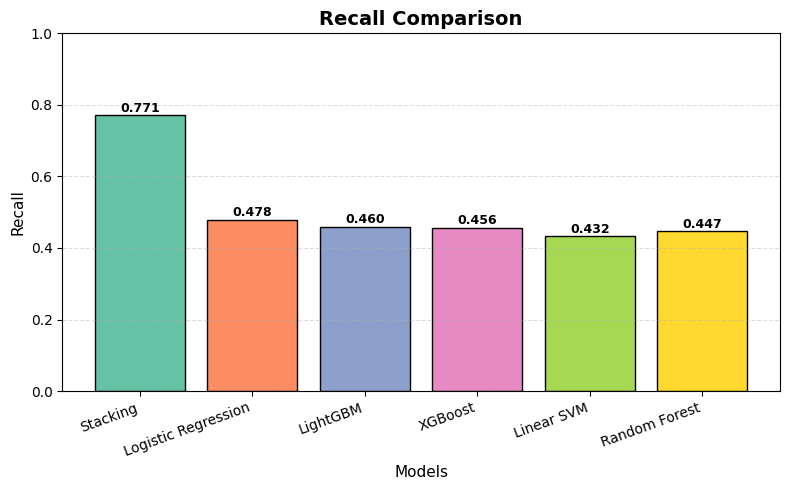

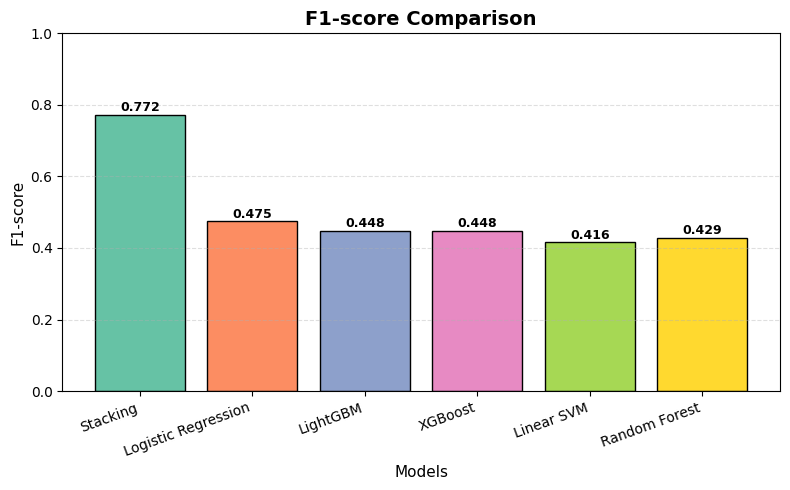

In [243]:
results_dft, best_modelt, allt_pipelines = evaluate_all_models(
    X_train,
    y_train_encoded,
    X_test,
    y_test_encoded,
    selector=None,
    le=label_encoder
)
plot_metrics_bar(results_dft)

### 📊 ĐÁNH GIÁ KẾT QUẢ MÔ HÌNH (FINAL RESULT)

---

* **🥞 Stacking (Áp đảo):** 
  * **Accuracy: 81.96%** — Cao hơn nhóm mô hình đơn lẻ tới **~28%**.
  * **F1-score: 77.20%** — Precision & Recall cực kỳ cân bằng (~77-78%).
* **🤖 Base Models (Đồng đều ở mức thấp):** 
  * Tất cả đều ở ngưỡng **51% – 53%** (cao nhất là *Logistic Regression* 53.93%, thấp nhất là *Random Forest* 51.82%).

---


### 📈 PHÂN TÍCH ROC CURVE (STACKING VS RANDOM FOREST)

---

📊 1. So sánh nhanh chỉ số AUC

* **🥞 Stacking Classifier:**
  * **Micro AUC:** **0.96** | **Macro AUC:** **0.96** *(Gần như hoàn hảo)*
* **🌲 Random Forest:**
  * **Micro AUC:** **0.83** | **Macro AUC:** **0.82** *(Mức trung bình)*

---

💡 2. Nhận xét

1. **Stacking (+0.13 - 0.14 AUC):** Đường cong tiệm cận góc trên bên trái, thể hiện khả năng phân biệt lớp chính xác gần như tối đa với tỷ lệ báo động giả (FPR) cực thấp.
2. **Độ ổn định cao:** Micro và Macro AUC của Stacking bằng nhau (**0.96**), **đồng đều trên tất cả các chuyên khoa**, không bị lệch nhãn.


### ⚠️ **ĐÁNH GIÁ LEARNING CURVE OVERFITTING NẶNG Ở CÁC MÔ HÌNH ĐƠN LẺ (BASE MODELS)**
> * **Hiện trạng:** Khoảng cách giữa Train (~90%) và Validation (~50%) rất lớn.
> * **Nguyên nhân gốc rễ:** Lệch số chiều/mẫu (*20,000 TF-IDF features* 🆚 *1,400 training samples*).

# TF-IDF + chi2 + Evaluation

- SelectKBest(score_func=chi2, k=5000) -> Chọn 5.000 đặc trưng quan trọng nhất bằng kiểm định Chi-Square.


================ Logistic Regression ================


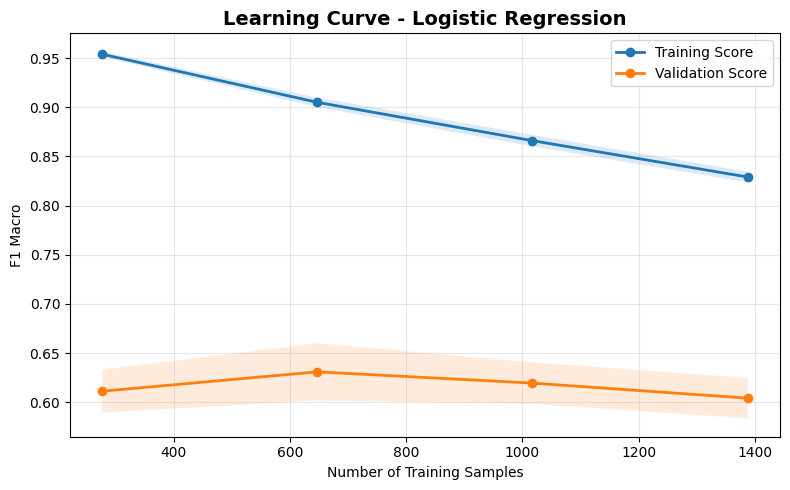


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.3605    0.4189    0.3875        74
Consult - History and Phy.     0.8137    0.8058    0.8098       103
                Orthopedic     0.3125    0.4225    0.3593        71
                 Radiology     0.4426    0.4909    0.4655        55
                   Surgery     0.7784    0.6284    0.6954       218

                  accuracy                         0.5912       521
                 macro avg     0.5415    0.5533    0.5435       521
              weighted avg     0.6271    0.5912    0.6042       521



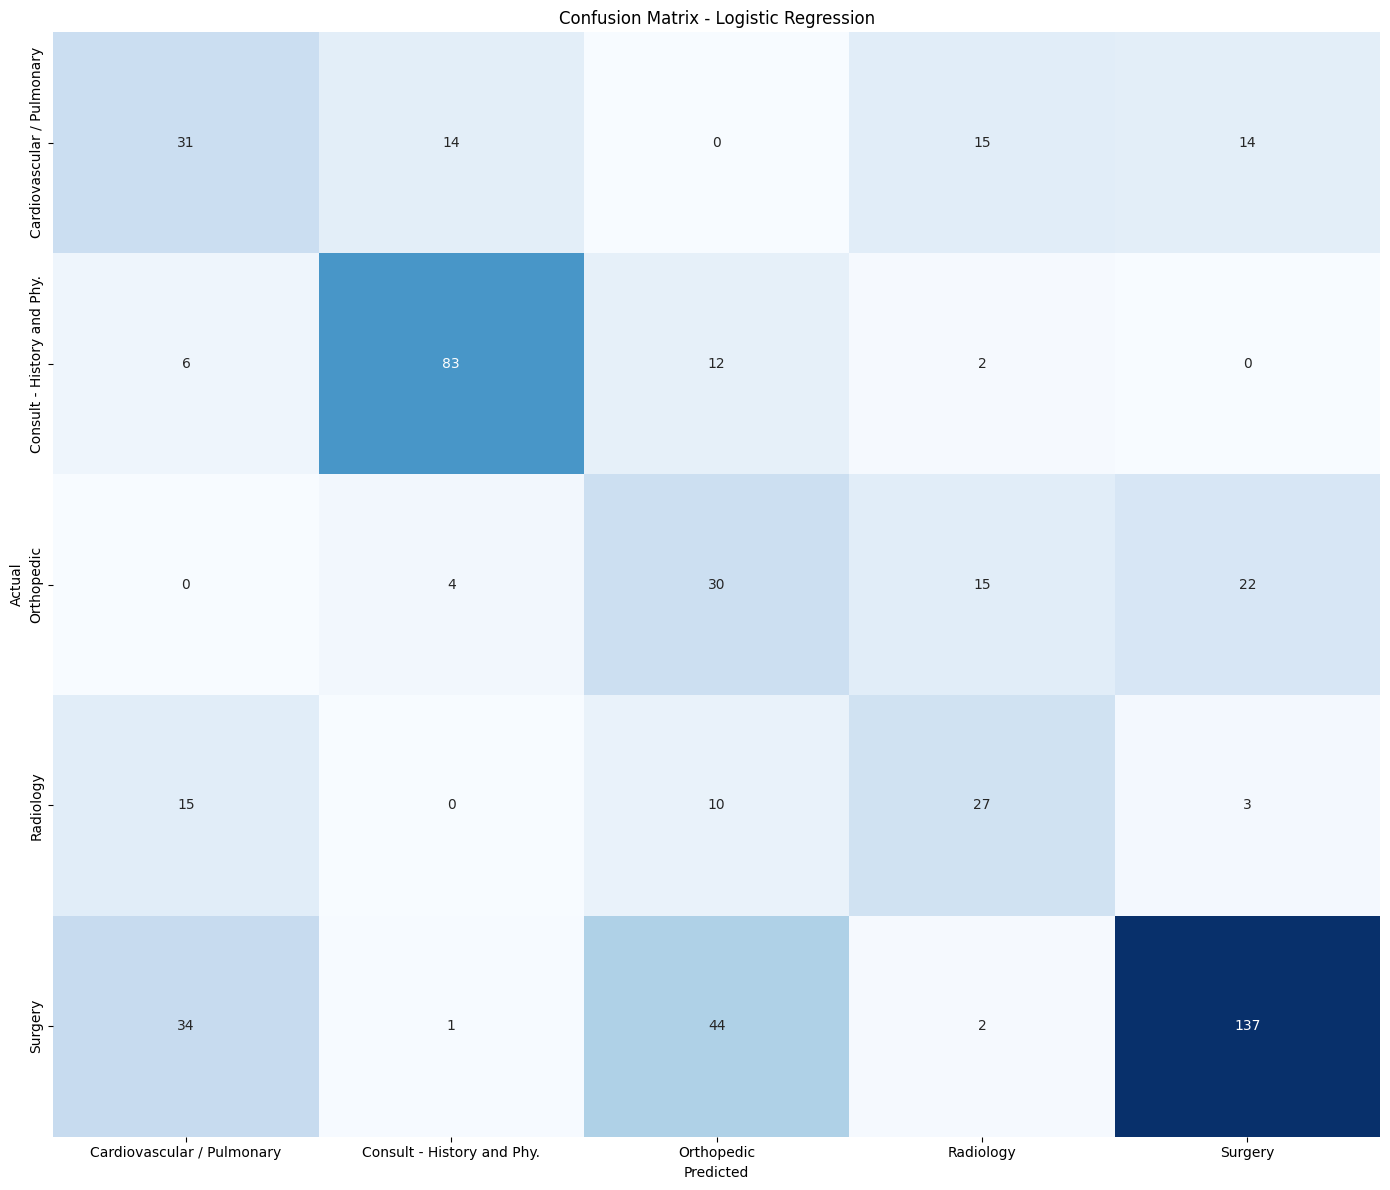

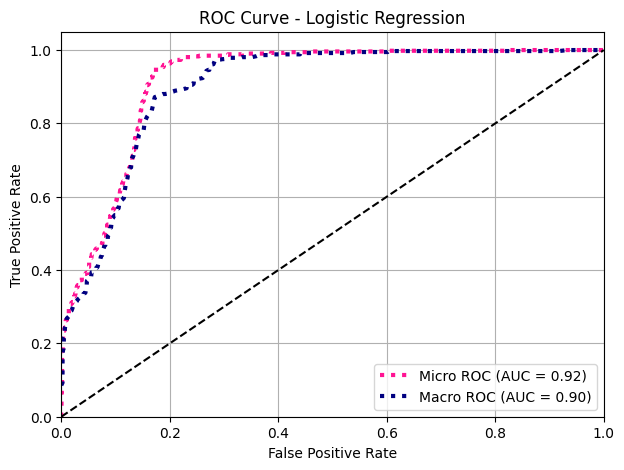


================ Linear SVM ================


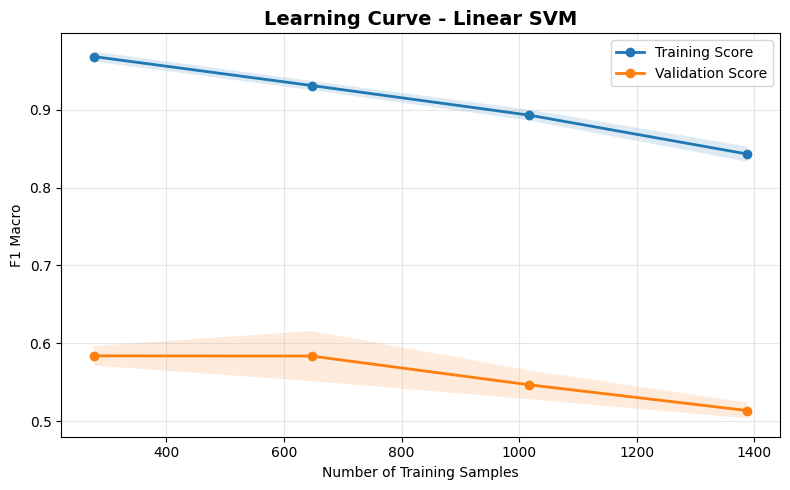


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1429    0.1081    0.1231        74
Consult - History and Phy.     0.7544    0.8350    0.7926       103
                Orthopedic     0.1356    0.1127    0.1231        71
                 Radiology     0.4211    0.4364    0.4286        55
                   Surgery     0.6596    0.7110    0.6843       218

                  accuracy                         0.5393       521
                 macro avg     0.4227    0.4406    0.4303       521
              weighted avg     0.5083    0.5393    0.5225       521



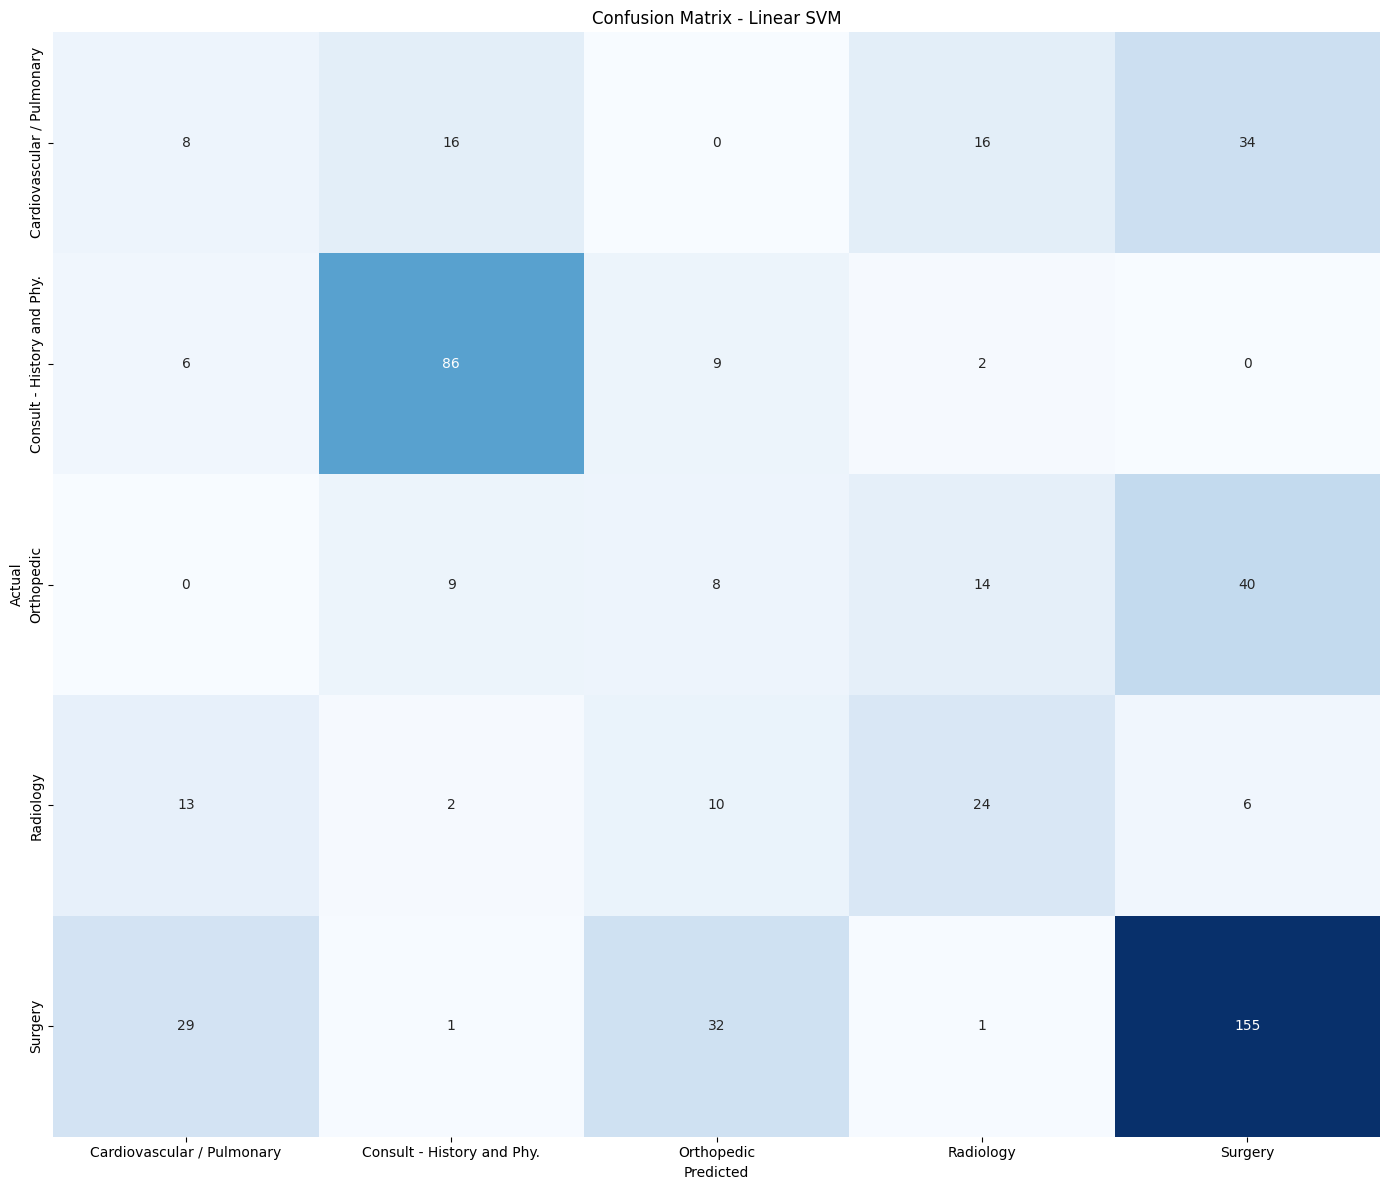

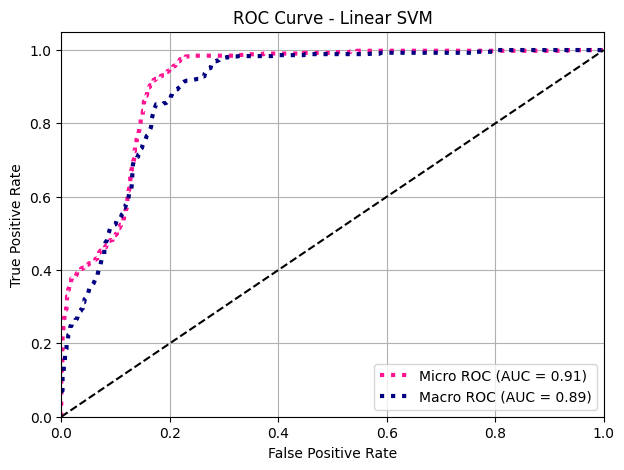


================ Random Forest ================


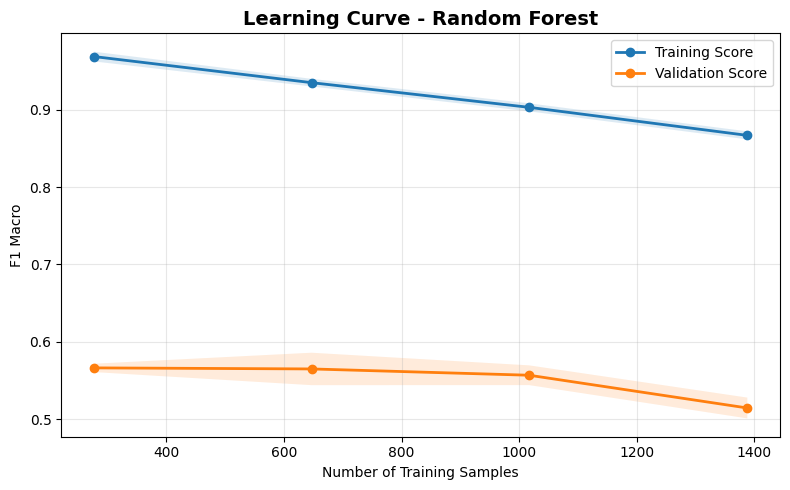


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1228    0.0946    0.1069        74
Consult - History and Phy.     0.7522    0.8252    0.7870       103
                Orthopedic     0.1029    0.0986    0.1007        71
                 Radiology     0.4324    0.5818    0.4961        55
                   Surgery     0.6555    0.6284    0.6417       218

                  accuracy                         0.5144       521
                 macro avg     0.4132    0.4457    0.4265       521
              weighted avg     0.5001    0.5144    0.5054       521



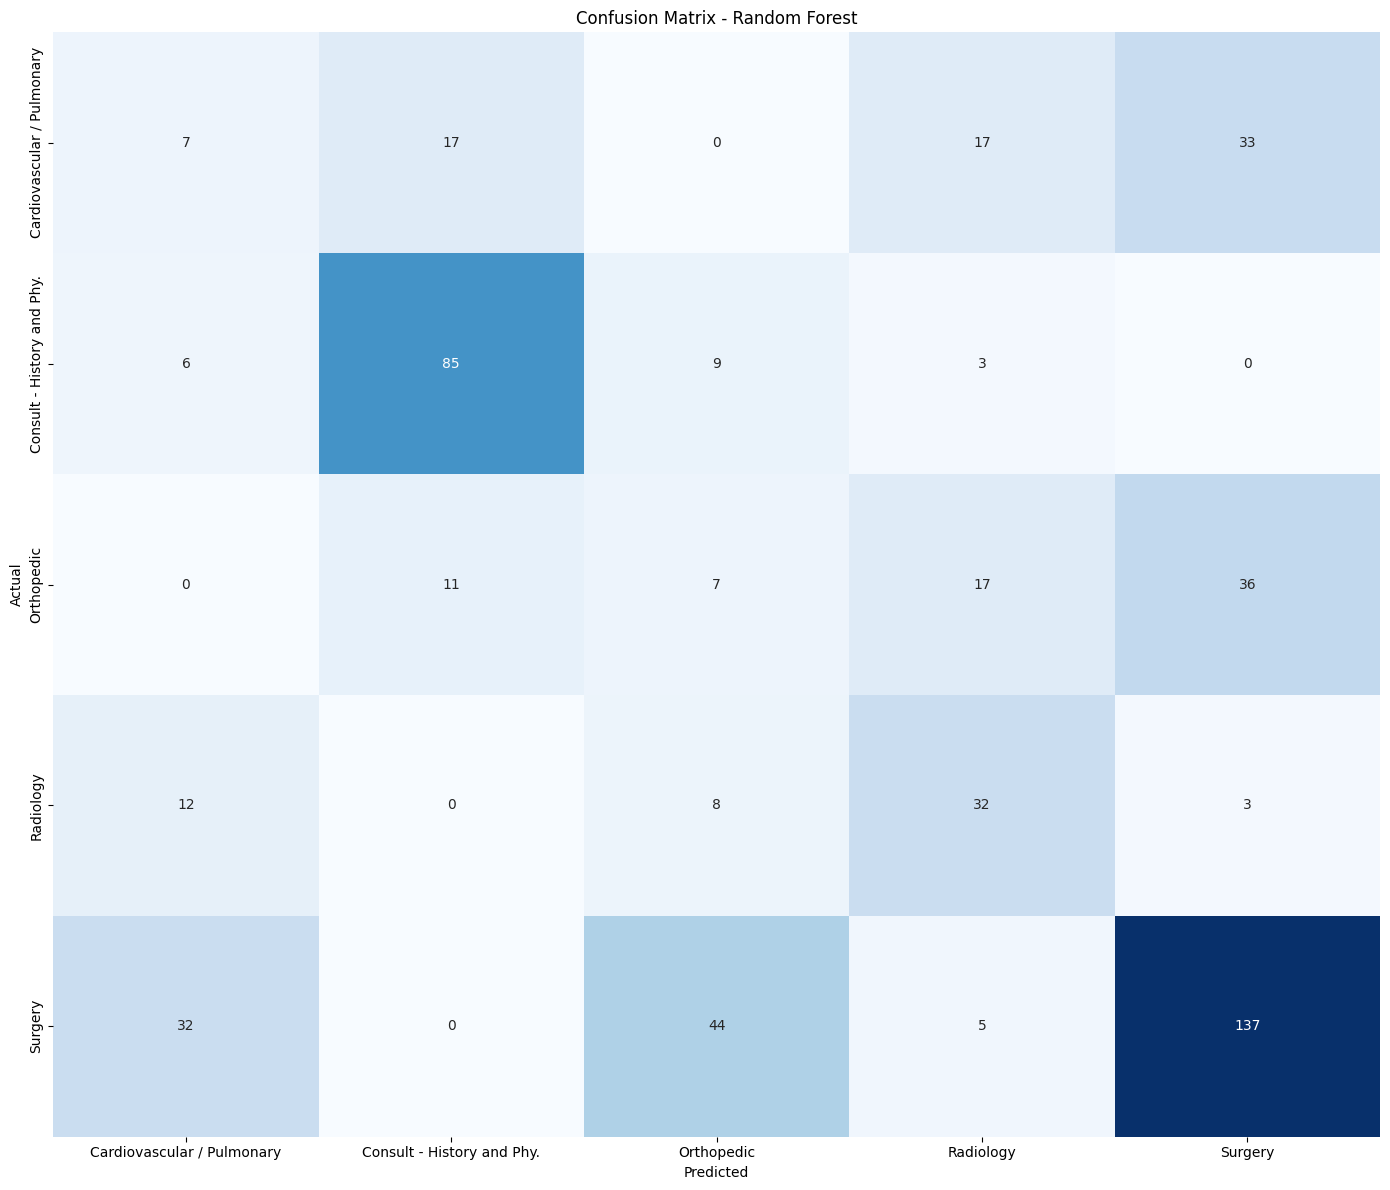

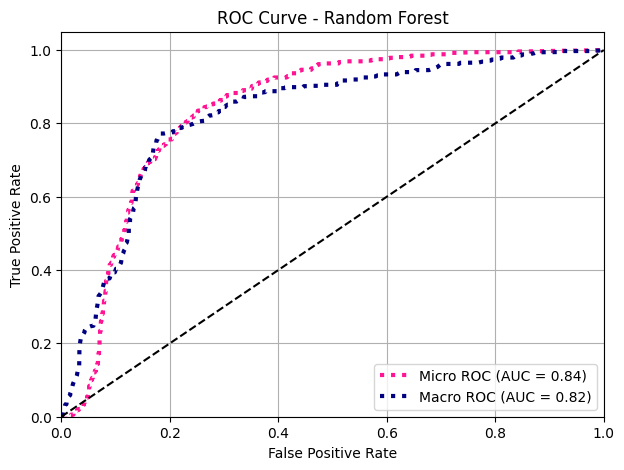


================ XGBoost ================


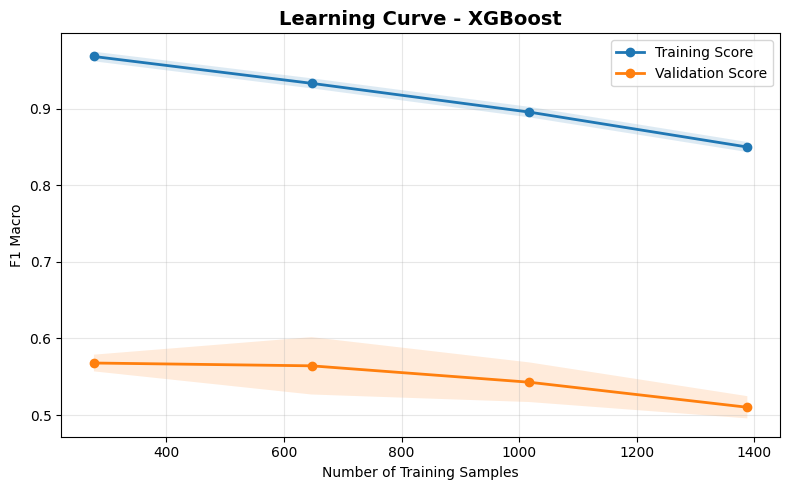


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1774    0.1486    0.1618        74
Consult - History and Phy.     0.7685    0.8058    0.7867       103
                Orthopedic     0.1343    0.1268    0.1304        71
                 Radiology     0.4531    0.5273    0.4874        55
                   Surgery     0.6636    0.6697    0.6667       218

                  accuracy                         0.5336       521
                 macro avg     0.4394    0.4556    0.4466       521
              weighted avg     0.5210    0.5336    0.5267       521



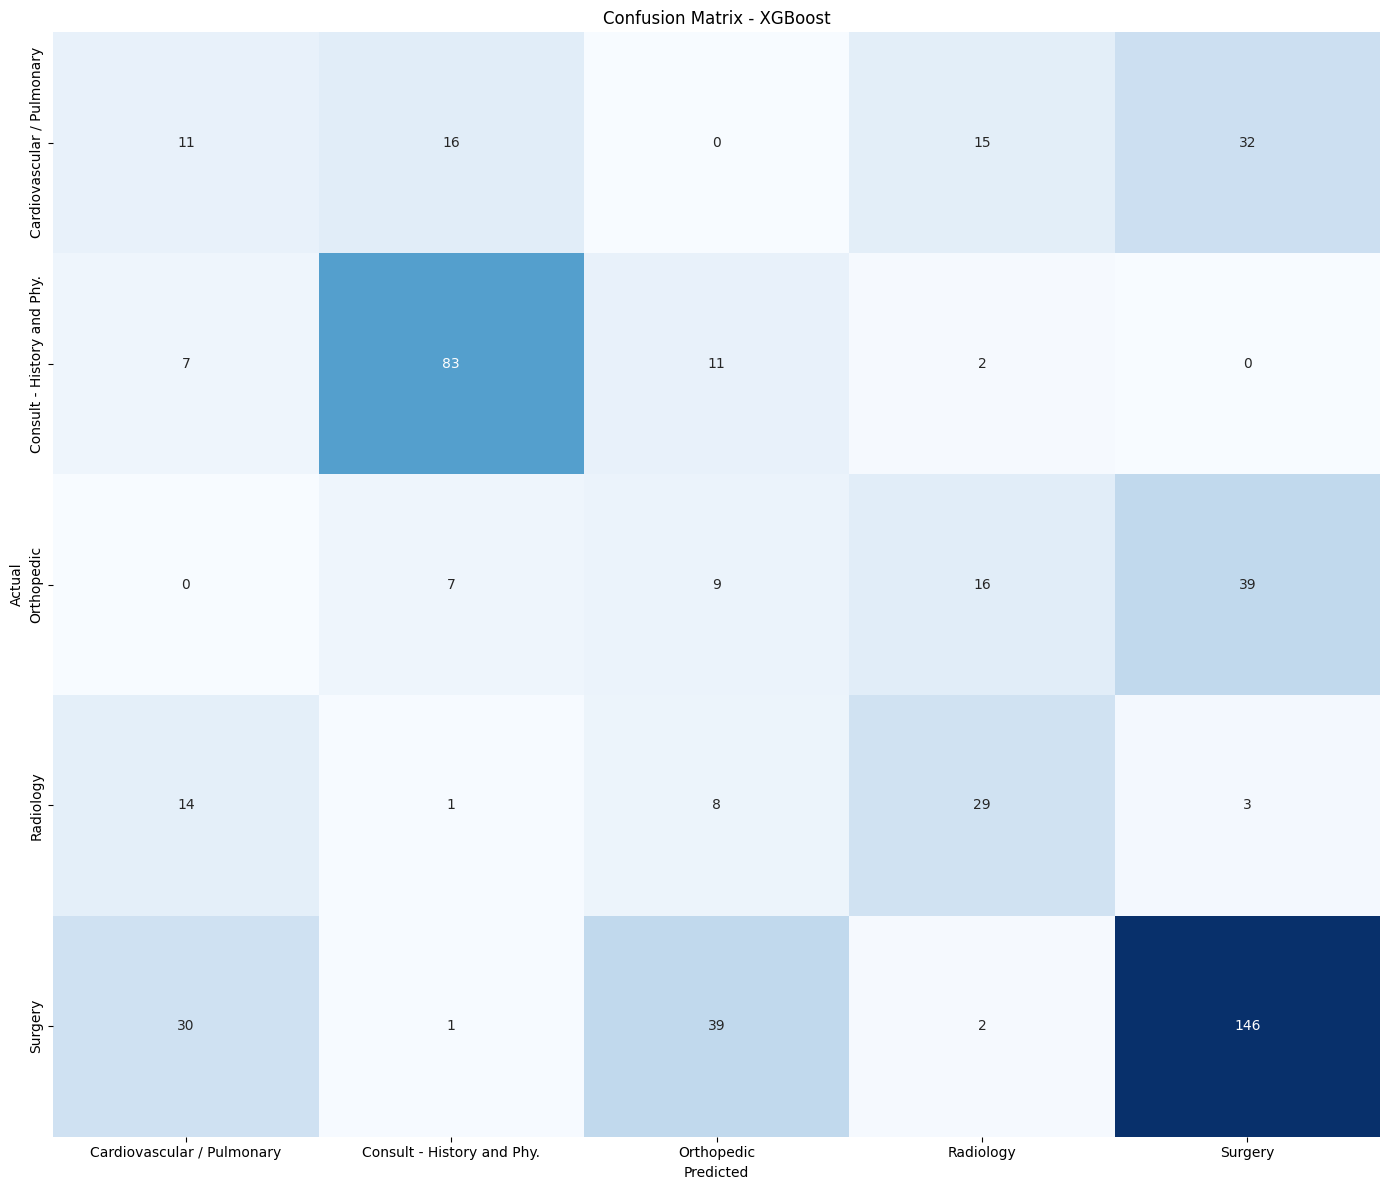

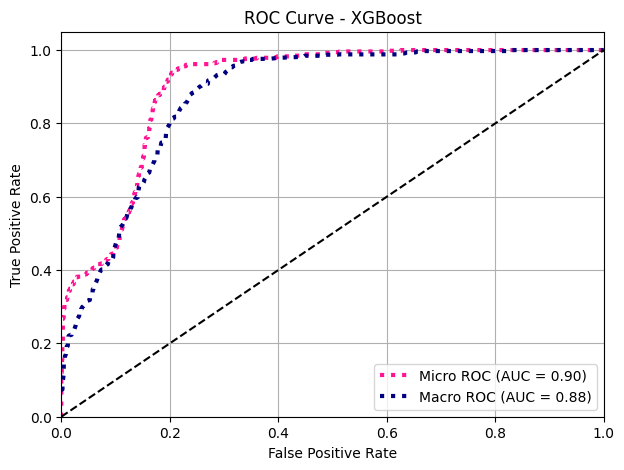


================ LightGBM ================


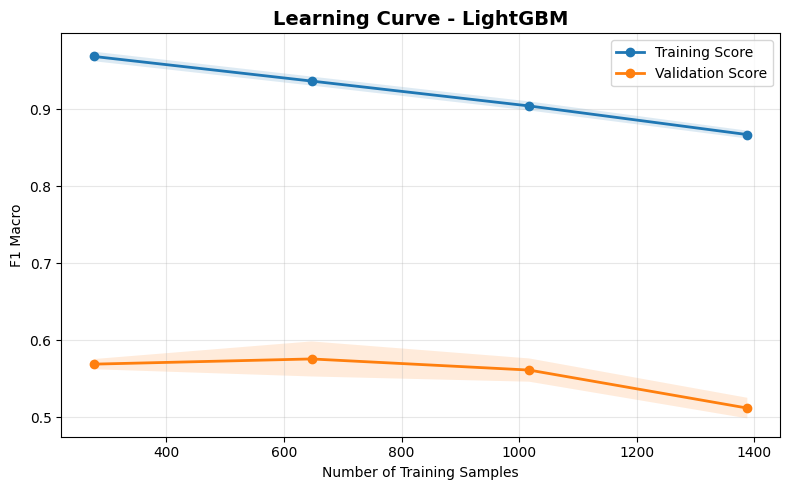


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1639    0.1351    0.1481        74
Consult - History and Phy.     0.8039    0.7961    0.8000       103
                Orthopedic     0.1528    0.1549    0.1538        71
                 Radiology     0.4545    0.5455    0.4959        55
                   Surgery     0.6591    0.6651    0.6621       218

                  accuracy                         0.5336       521
                 macro avg     0.4469    0.4594    0.4520       521
              weighted avg     0.5268    0.5336    0.5296       521



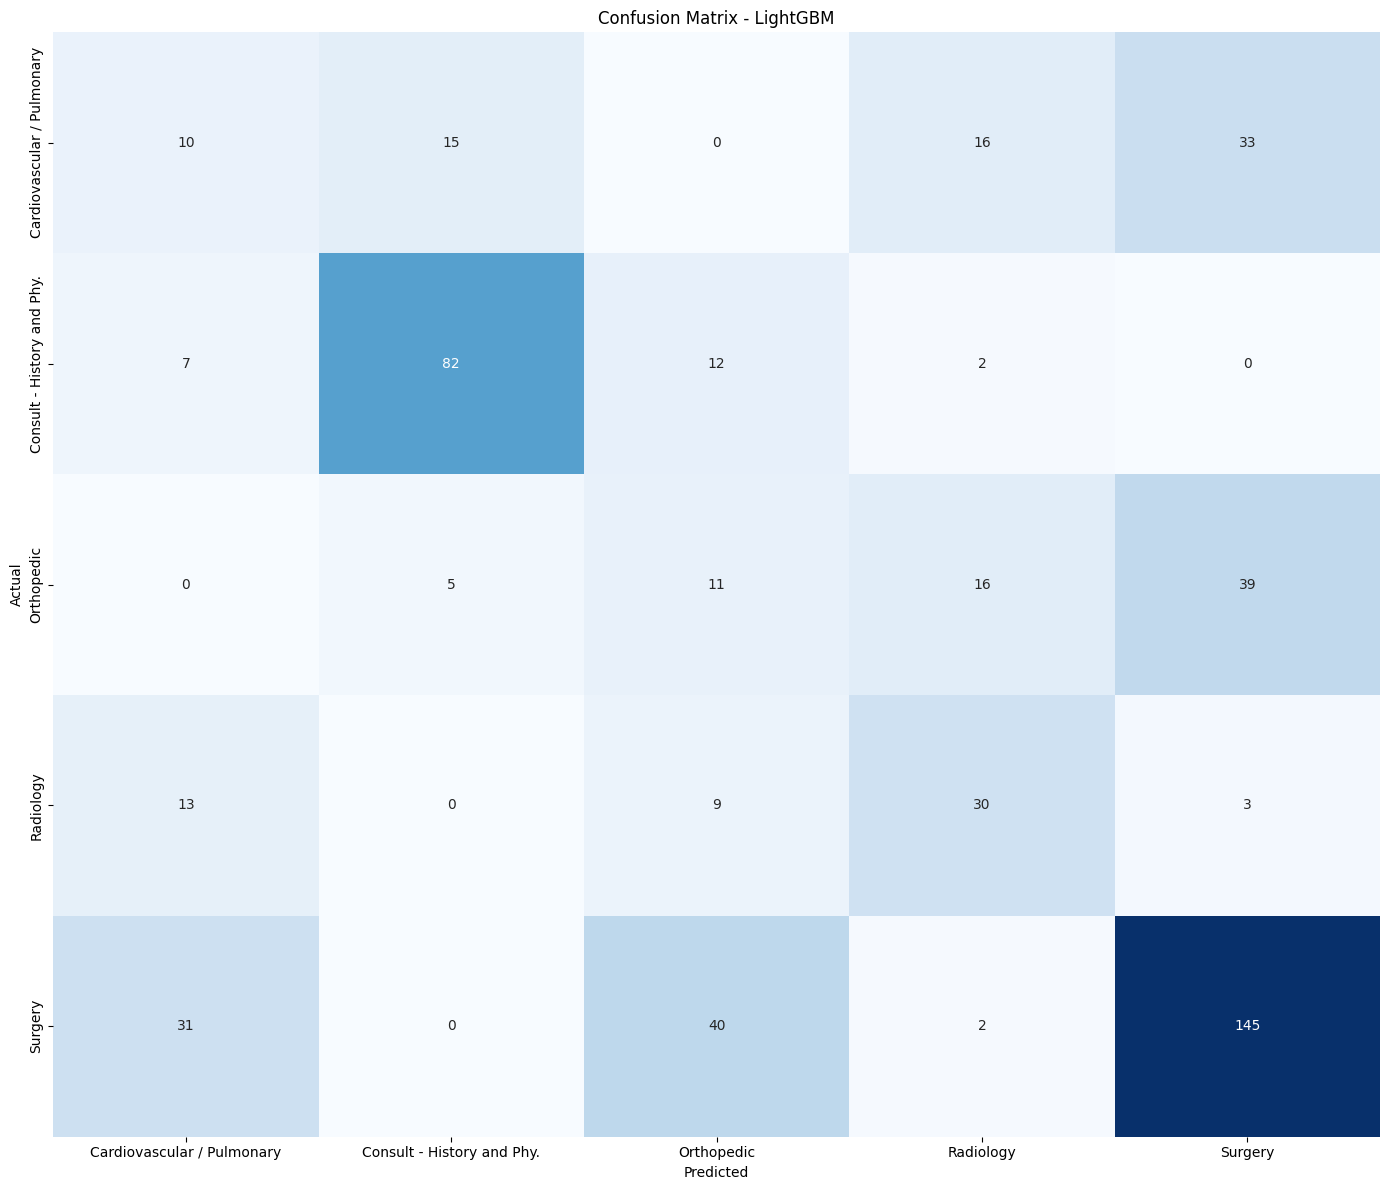

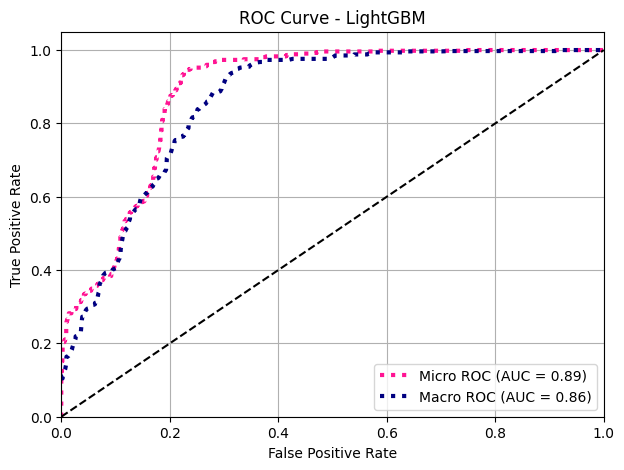


================ Stacking ================
Skip Learning Curve for Stacking (too computationally expensive).

Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.8030    0.7162    0.7571        74
Consult - History and Phy.     0.8704    0.9126    0.8910       103
                Orthopedic     0.6912    0.6620    0.6763        71
                 Radiology     0.6719    0.7818    0.7227        55
                   Surgery     0.9209    0.9083    0.9145       218

                  accuracy                         0.8349       521
                 macro avg     0.7915    0.7962    0.7923       521
              weighted avg     0.8366    0.8349    0.8348       521



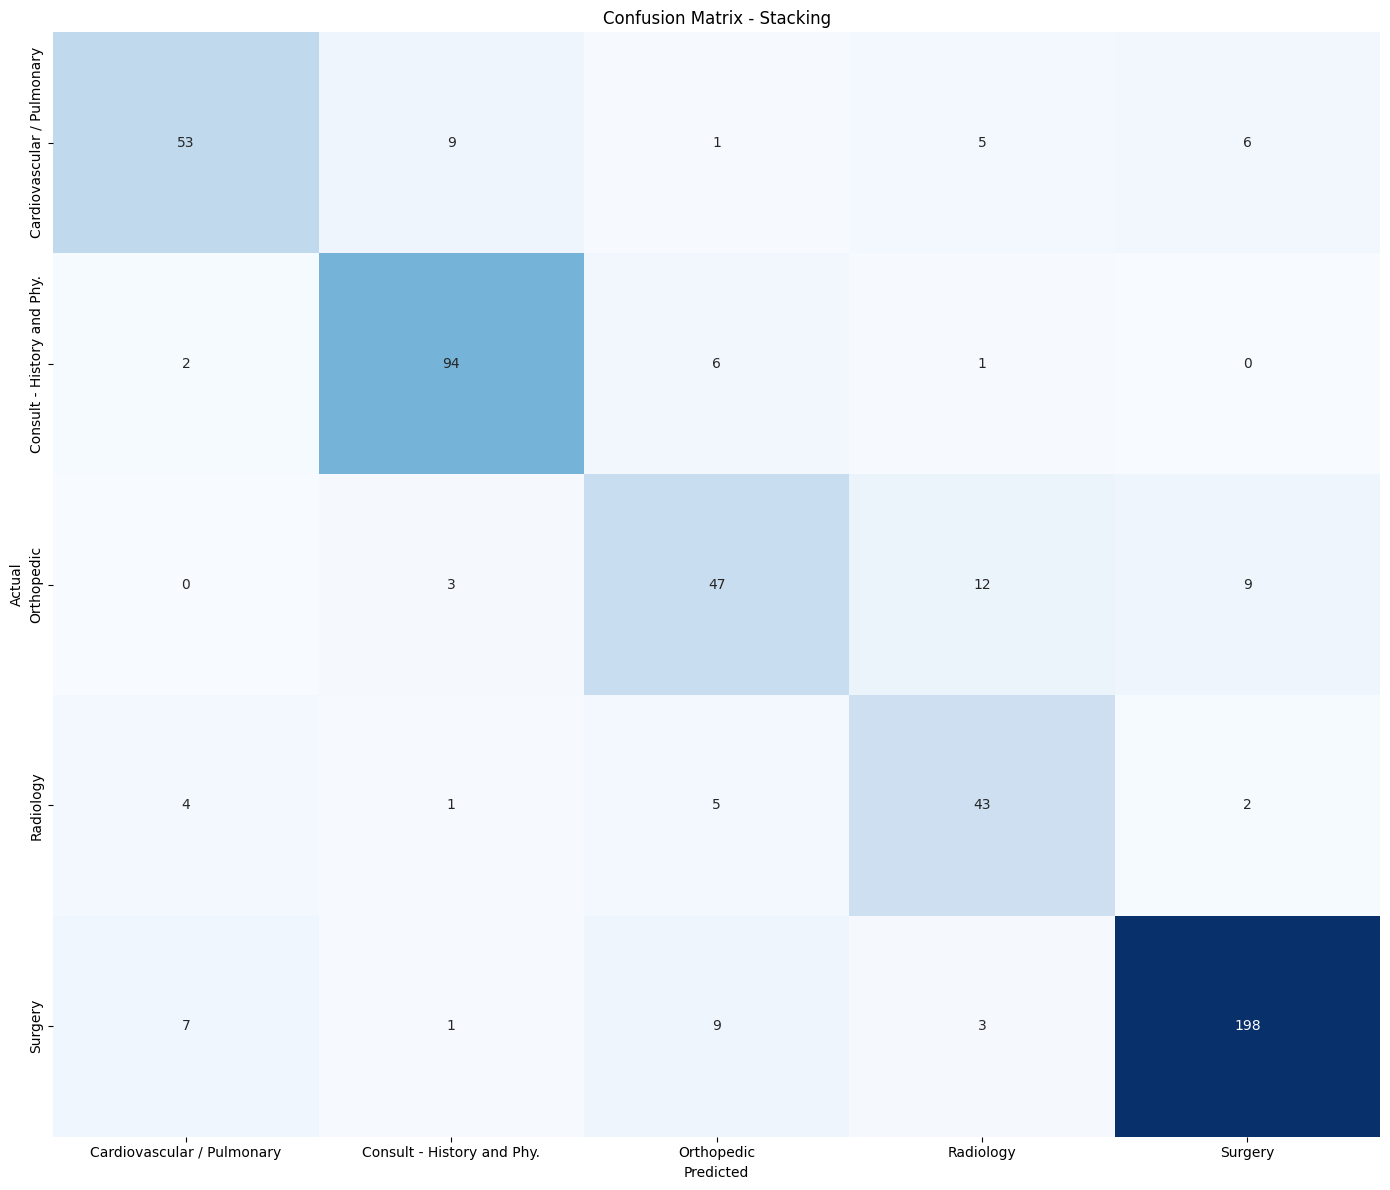

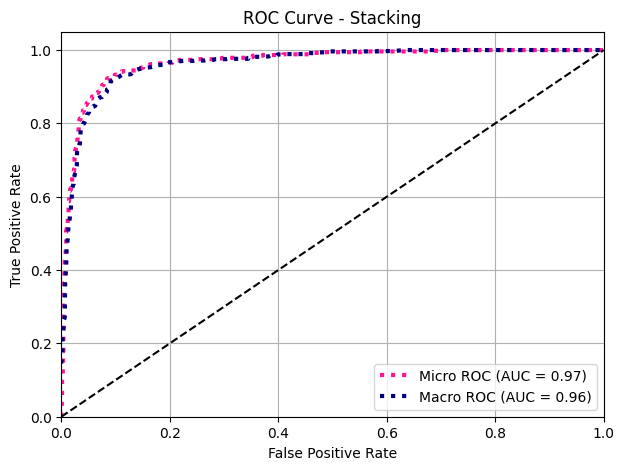


================ FINAL RESULT ================

                     Accuracy  Precision  Recall  F1-score
Model                                                     
Stacking               0.8349     0.7915  0.7962    0.7923
Logistic Regression    0.5912     0.5415  0.5533    0.5435
Linear SVM             0.5393     0.4227  0.4406    0.4303
XGBoost                0.5336     0.4394  0.4556    0.4466
LightGBM               0.5336     0.4469  0.4594    0.4520
Random Forest          0.5144     0.4132  0.4457    0.4265

 Mô hình tốt nhất: Stacking


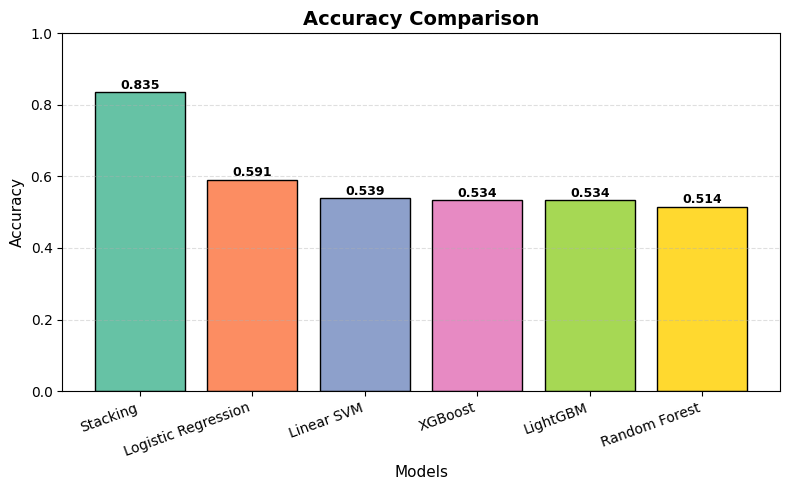

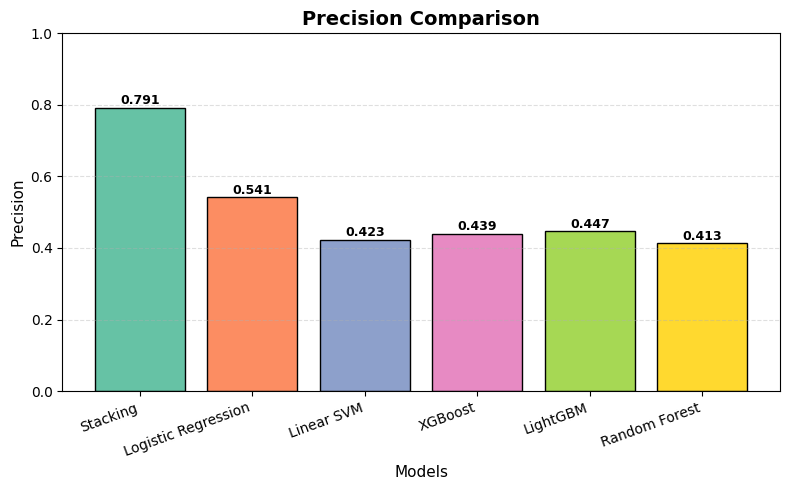

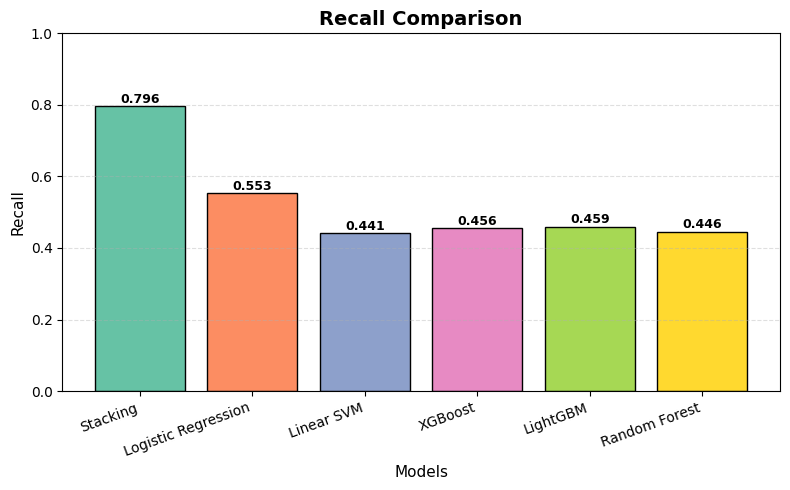

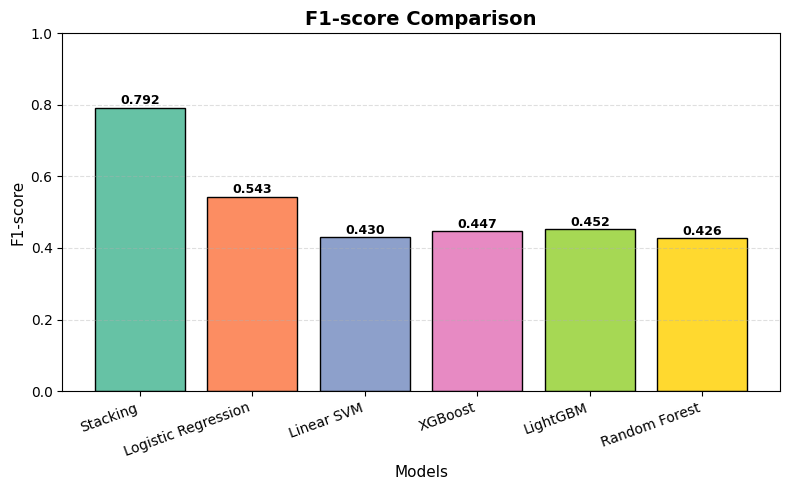

In [244]:
selector = SelectKBest(
    score_func=chi2,
    k=5000
)

results_dftc, best_modeltc, alltc_pipelines = evaluate_all_models(
    X_train,
    y_train_encoded,
    X_test,
    y_test_encoded,
    selector=selector,
    le=label_encoder
)
plot_metrics_bar(results_dftc)

### 📊 ĐÁNH GIÁ KẾT QUẢ MÔ HÌNH (FINAL RESULT)

---

* **🥞 Stacking (Kỷ lục mới):** 
  * **Accuracy: 83.69%**.
  * **F1-score: 79.53%**.
* **🤖 Base Models:** 
  * **Logistic Regression** : (**59.12%**).
  * Các mô hình còn lại chỉ ở ngưỡng **51.4% – 53.9%** (SVM: 53.93%, XGB/LGBM: 53.36%, RF: 51.44%).


- plot_svd(...) -> Trực quan hóa dữ liệu văn bản sau khi giảm chiều bằng Truncated SVD.
- label_encoder -> Chuyển nhãn số thành tên chuyên khoa khi hiển thị chú thích (legend).



### 📈 3. So sánh khả năng phân loại qua ROC Curve

| Tiêu chí | 🥞 Stacking Classifier | 🌲 Random Forest | Nhận xét |
| :--- | :---: | :---: | :--- |
| **Micro ROC (AUC)** | **0.97** | 0.84 | ➕ **+0.13** |
| **Macro ROC (AUC)** | **0.96** | 0.82 | ➕ **+0.14** |
| **Độ ổn định nhãn** | Cực kỳ đồng đều | Có sự chênh lệch | Stacking phân loại tốt trên mọi nhãn |

---

>  Áp dụng **Stacking Ensemble** là bước đi mang tính quyết định, giúp giảm variance, bù trừ sai số giữa nhóm Tuyến tính và nhóm Cây, độ chính xác lên **83.69%** với **AUC = 0.96 – 0.97**.

# TF-IDF + TruncatedSVD + Evaluation

## TruncatedSVD Plot

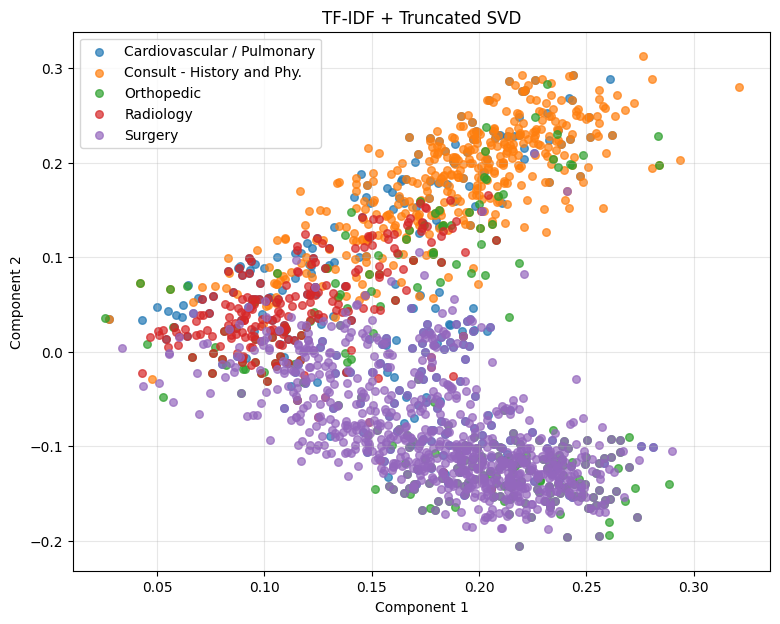

In [245]:
plot_svd(
    X_train,
    y_train_encoded,
    label_encoder
)

**Nhận xét:** Các điểm màu ứng với 5 chuyên khoa tách thành từng cụm khá rõ nhưng vẫn có vùng chồng lấn ở giữa biểu đồ (đặc biệt giữa các chuyên khoa có nội dung gần nhau) lý giải vì sao các mô hình đơn lẻ vẫn còn nhầm lẫn dù đã dùng TF-IDF.

### ⚙️ Mô tả các hàm
---

- n_components=300 -> Giảm số lượng đặc trưng xuống còn 300 thành phần.
- random_state=42 -> Đảm bảo kết quả giảm chiều có thể lặp lại.
- evaluate_all_models(...) -> Huấn luyện và đánh giá tất cả các mô hình.
- selector=selector	-> Áp dụng Truncated SVD để giảm chiều dữ liệu trước khi huấn luyện.
- le=label_encoder -> Dùng LabelEncoder để hiển thị tên chuyên khoa thay vì nhãn số.


================ Logistic Regression ================


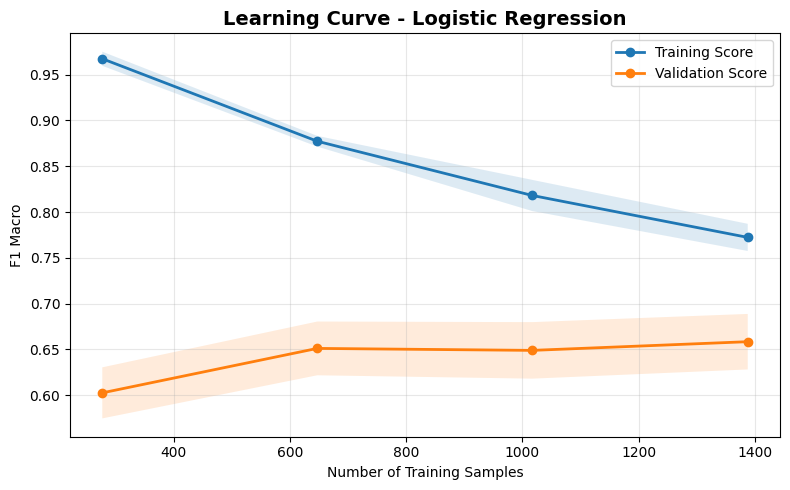


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.4598    0.5405    0.4969        74
Consult - History and Phy.     0.8241    0.8641    0.8436       103
                Orthopedic     0.3871    0.5070    0.4390        71
                 Radiology     0.5312    0.6182    0.5714        55
                   Surgery     0.8343    0.6468    0.7287       218

                  accuracy                         0.6526       521
                 macro avg     0.6073    0.6353    0.6159       521
              weighted avg     0.6862    0.6526    0.6624       521



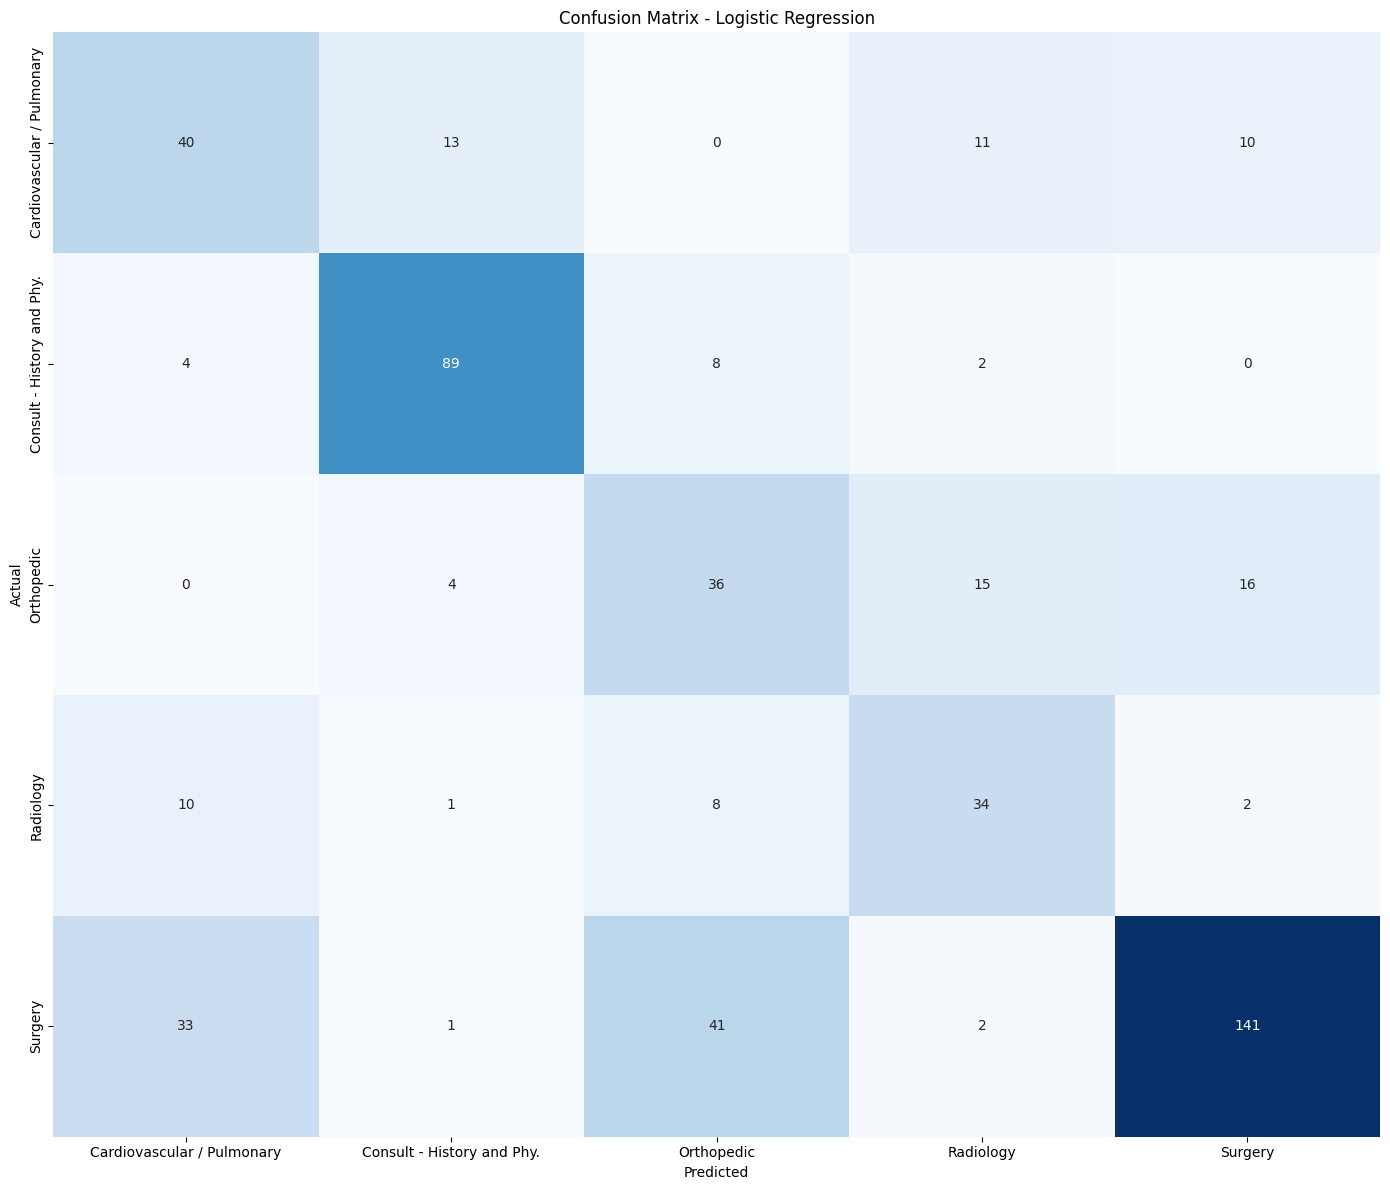

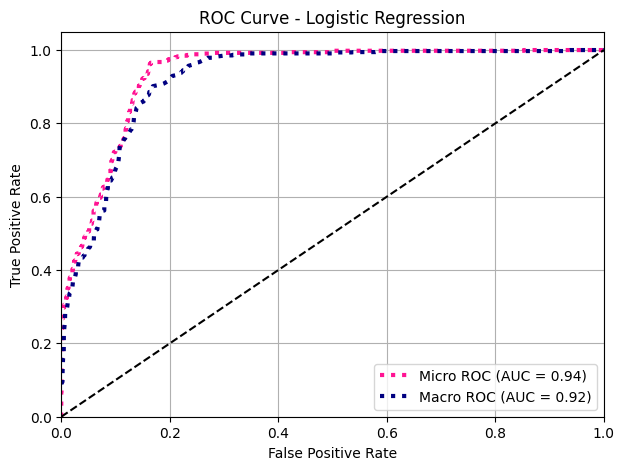


================ Linear SVM ================


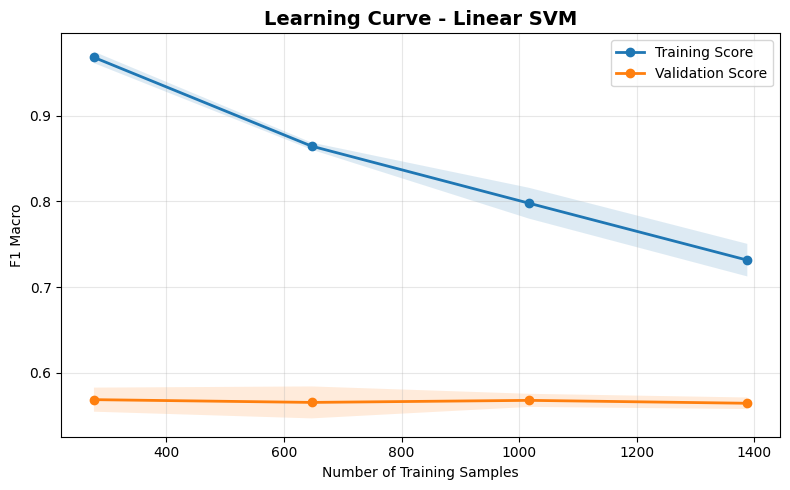


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.3261    0.2027    0.2500        74
Consult - History and Phy.     0.7759    0.8738    0.8219       103
                Orthopedic     0.2800    0.1972    0.2314        71
                 Radiology     0.5185    0.5091    0.5138        55
                   Surgery     0.7059    0.8257    0.7611       218

                  accuracy                         0.6276       521
                 macro avg     0.5213    0.5217    0.5156       521
              weighted avg     0.5880    0.6276    0.6022       521



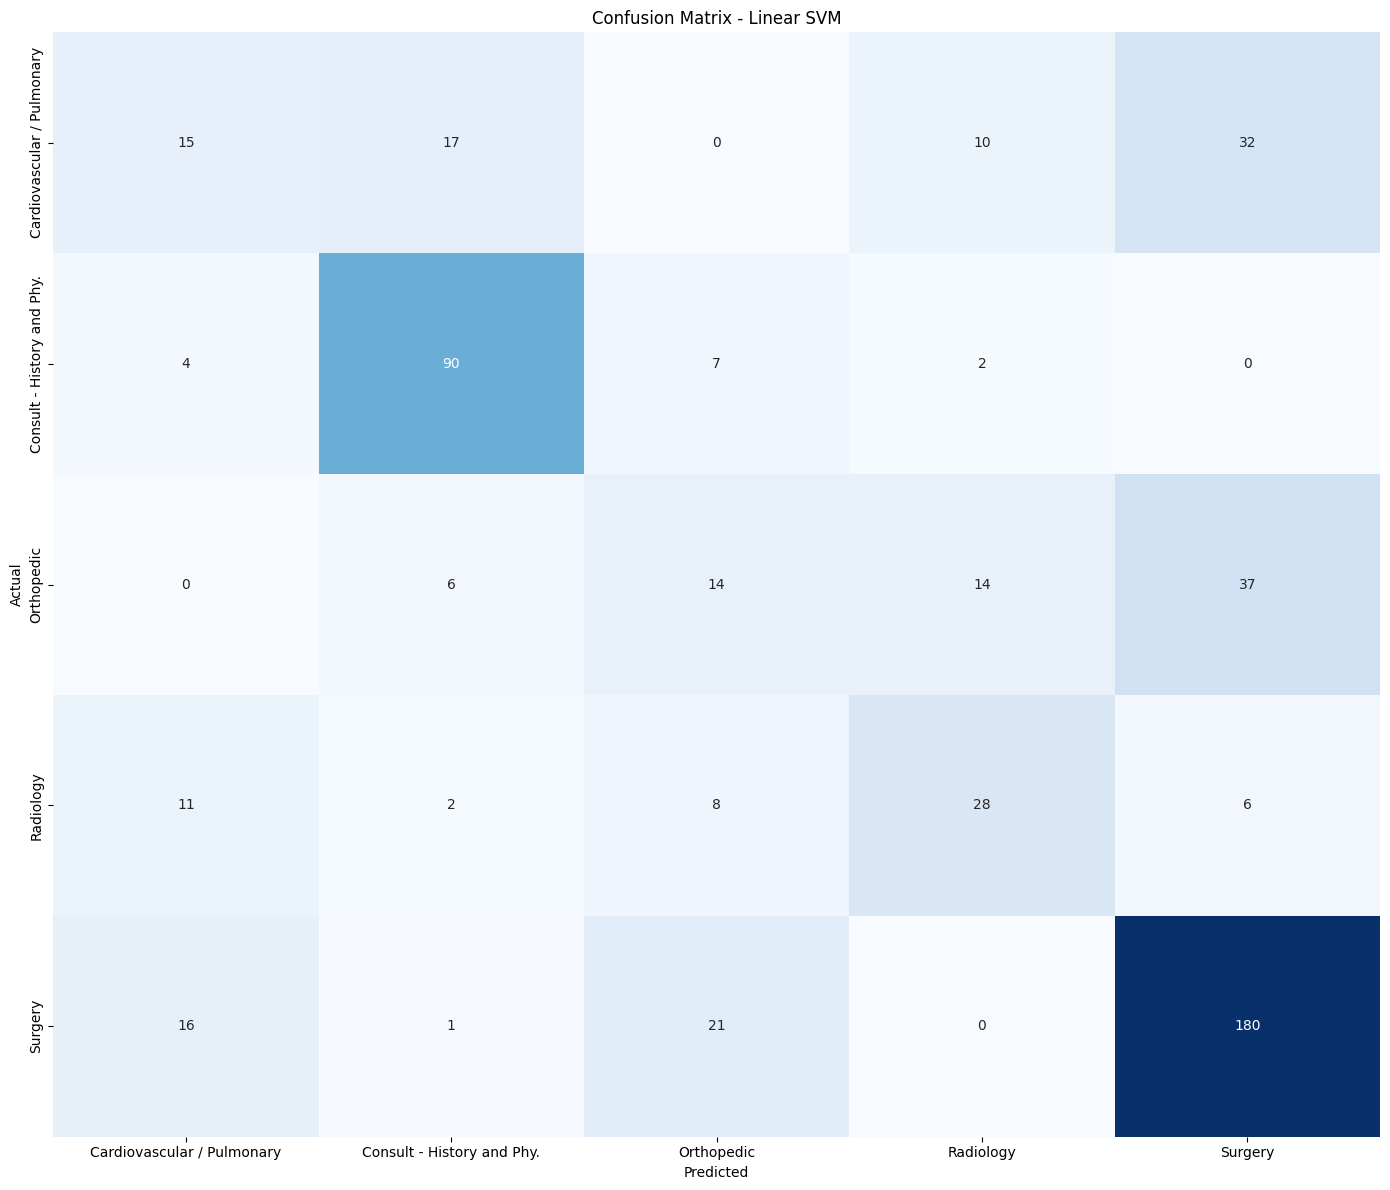

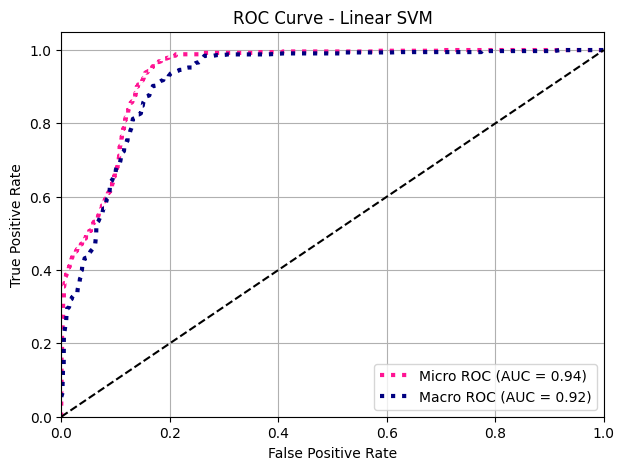


================ Random Forest ================


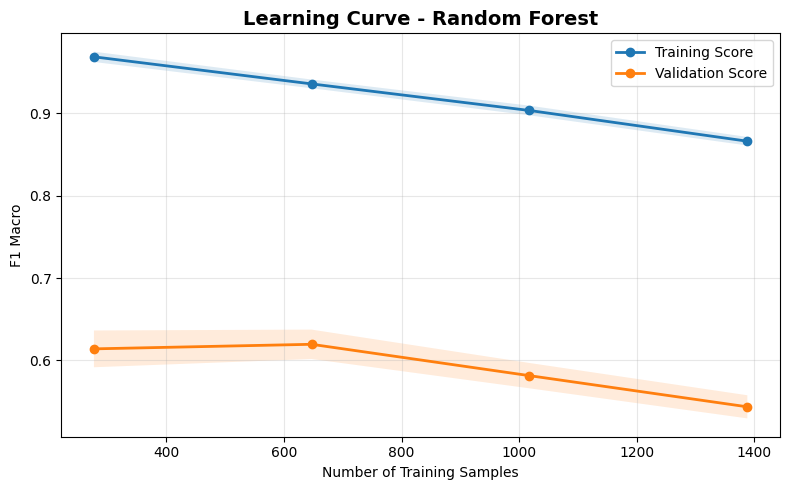


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1475    0.1216    0.1333        74
Consult - History and Phy.     0.7685    0.8058    0.7867       103
                Orthopedic     0.1905    0.2254    0.2065        71
                 Radiology     0.4394    0.5273    0.4793        55
                   Surgery     0.6683    0.6193    0.6429       218

                  accuracy                         0.5221       521
                 macro avg     0.4428    0.4599    0.4497       521
              weighted avg     0.5249    0.5221    0.5222       521



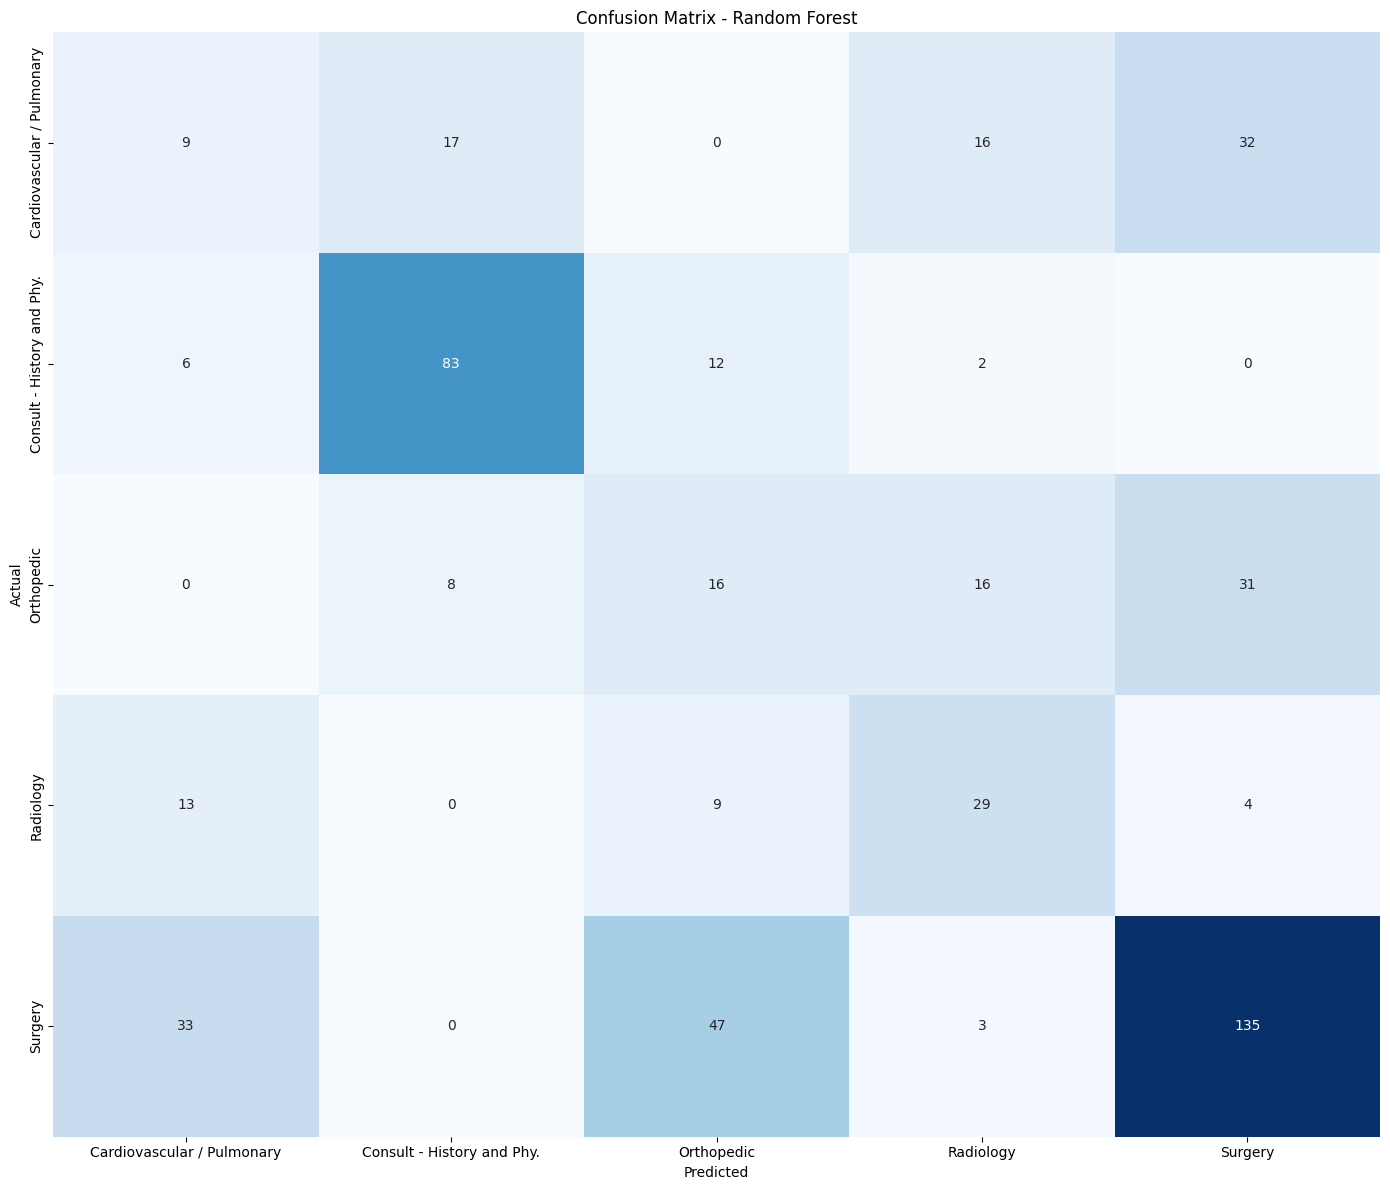

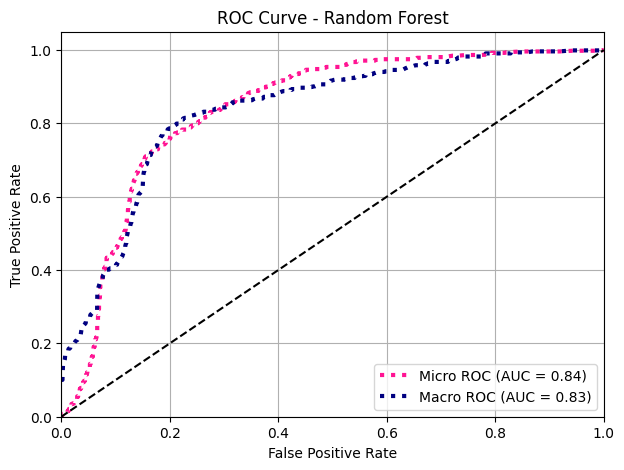


================ XGBoost ================


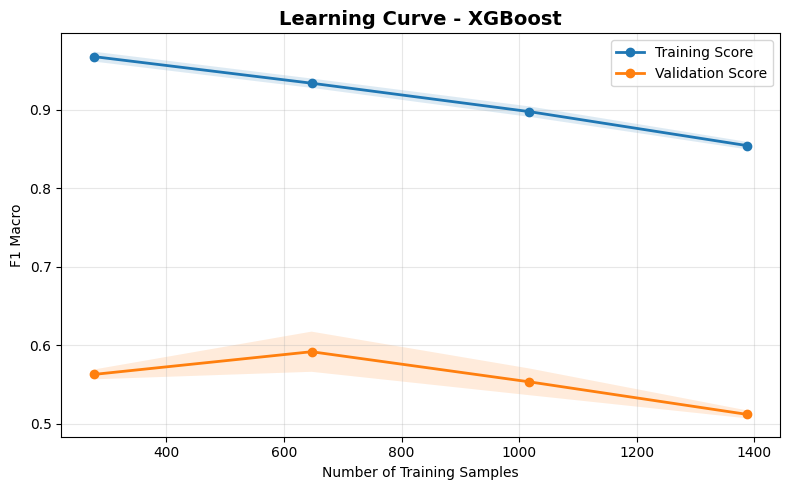


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1552    0.1216    0.1364        74
Consult - History and Phy.     0.7636    0.8155    0.7887       103
                Orthopedic     0.0938    0.0845    0.0889        71
                 Radiology     0.4167    0.4545    0.4348        55
                   Surgery     0.6419    0.6743    0.6577       218

                  accuracy                         0.5202       521
                 macro avg     0.4142    0.4301    0.4213       521
              weighted avg     0.4984    0.5202    0.5085       521



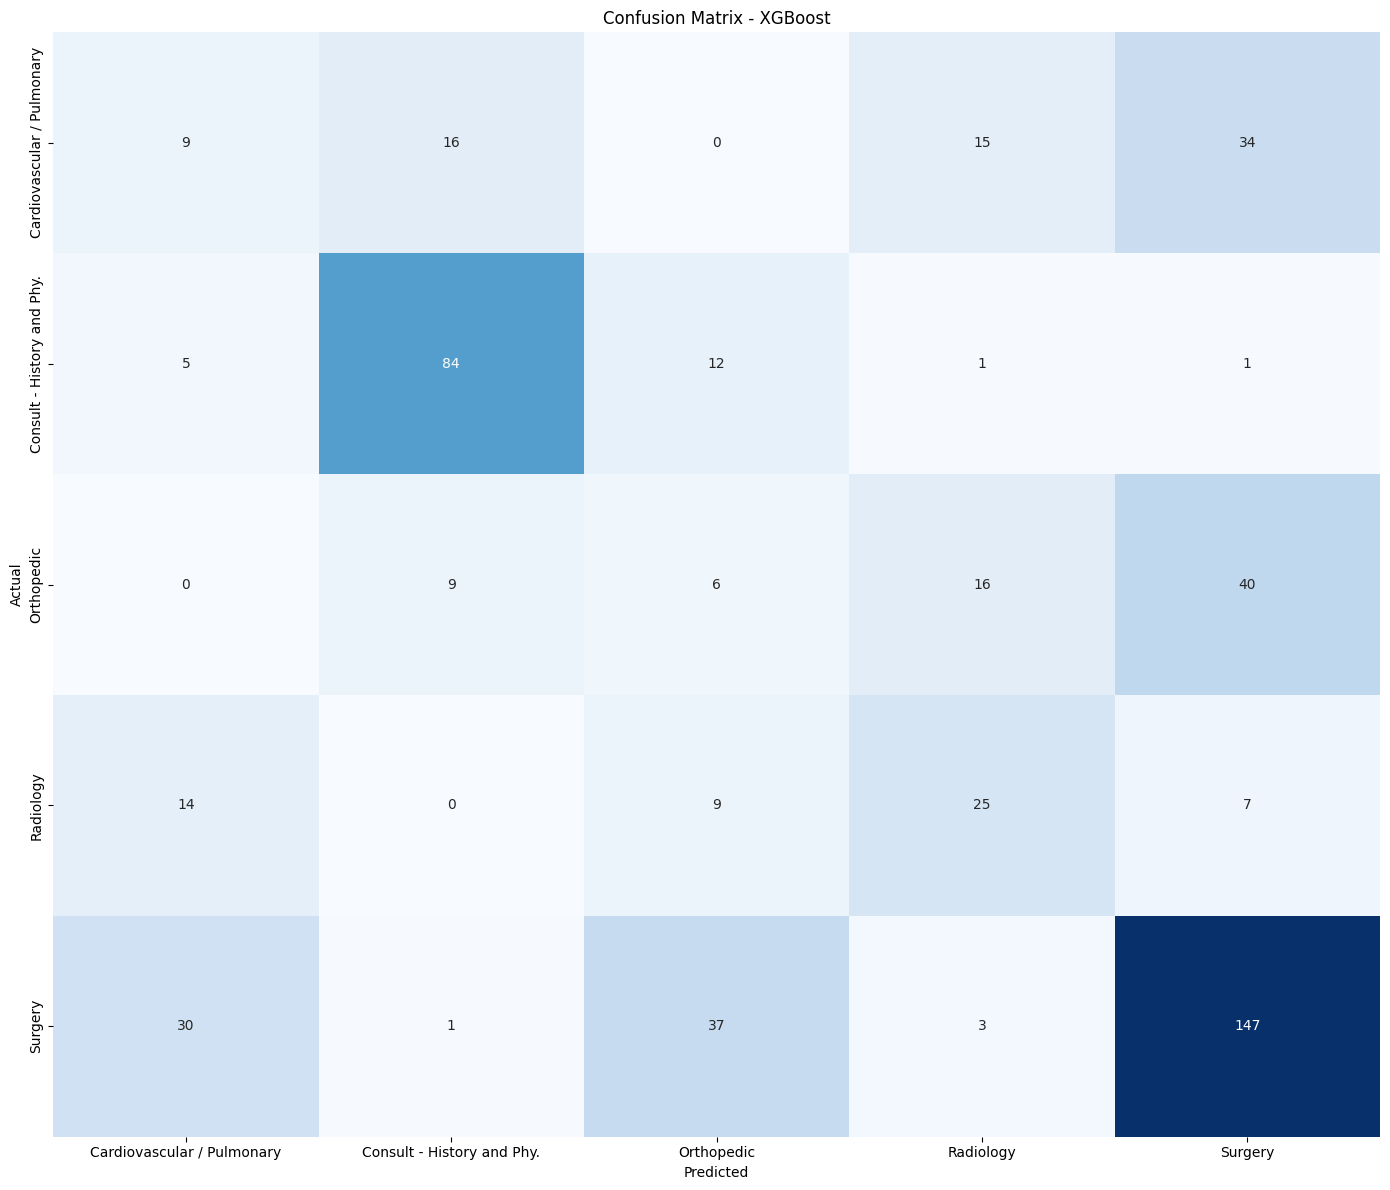

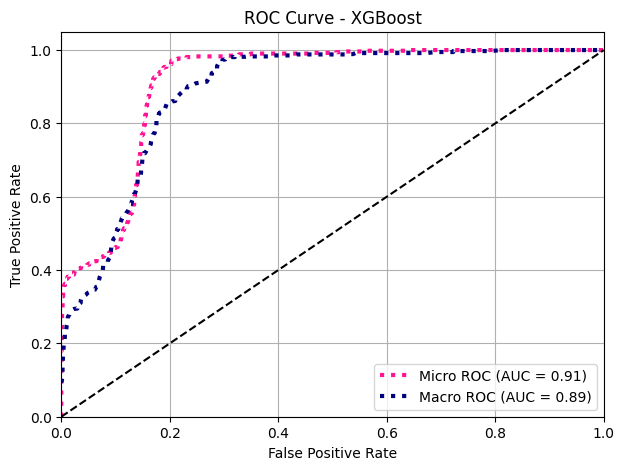


================ LightGBM ================


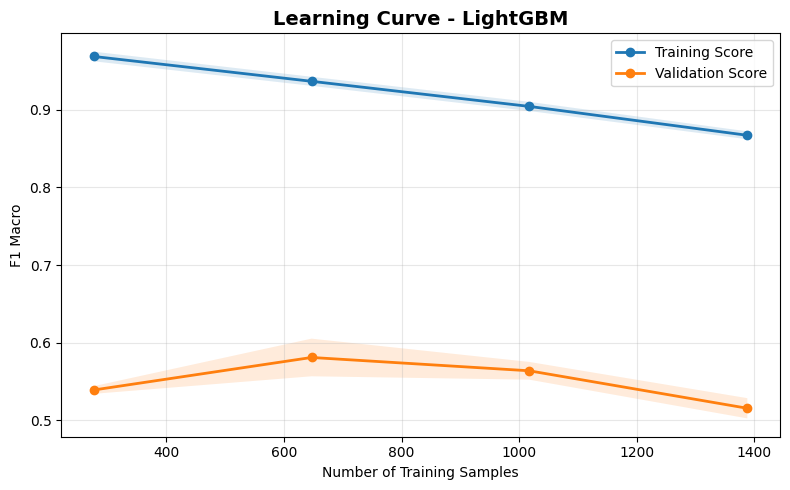


Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.1525    0.1216    0.1353        74
Consult - History and Phy.     0.7944    0.8252    0.8095       103
                Orthopedic     0.1528    0.1549    0.1538        71
                 Radiology     0.4462    0.5273    0.4833        55
                   Surgery     0.6560    0.6560    0.6560       218

                  accuracy                         0.5317       521
                 macro avg     0.4404    0.4570    0.4476       521
              weighted avg     0.5211    0.5317    0.5257       521



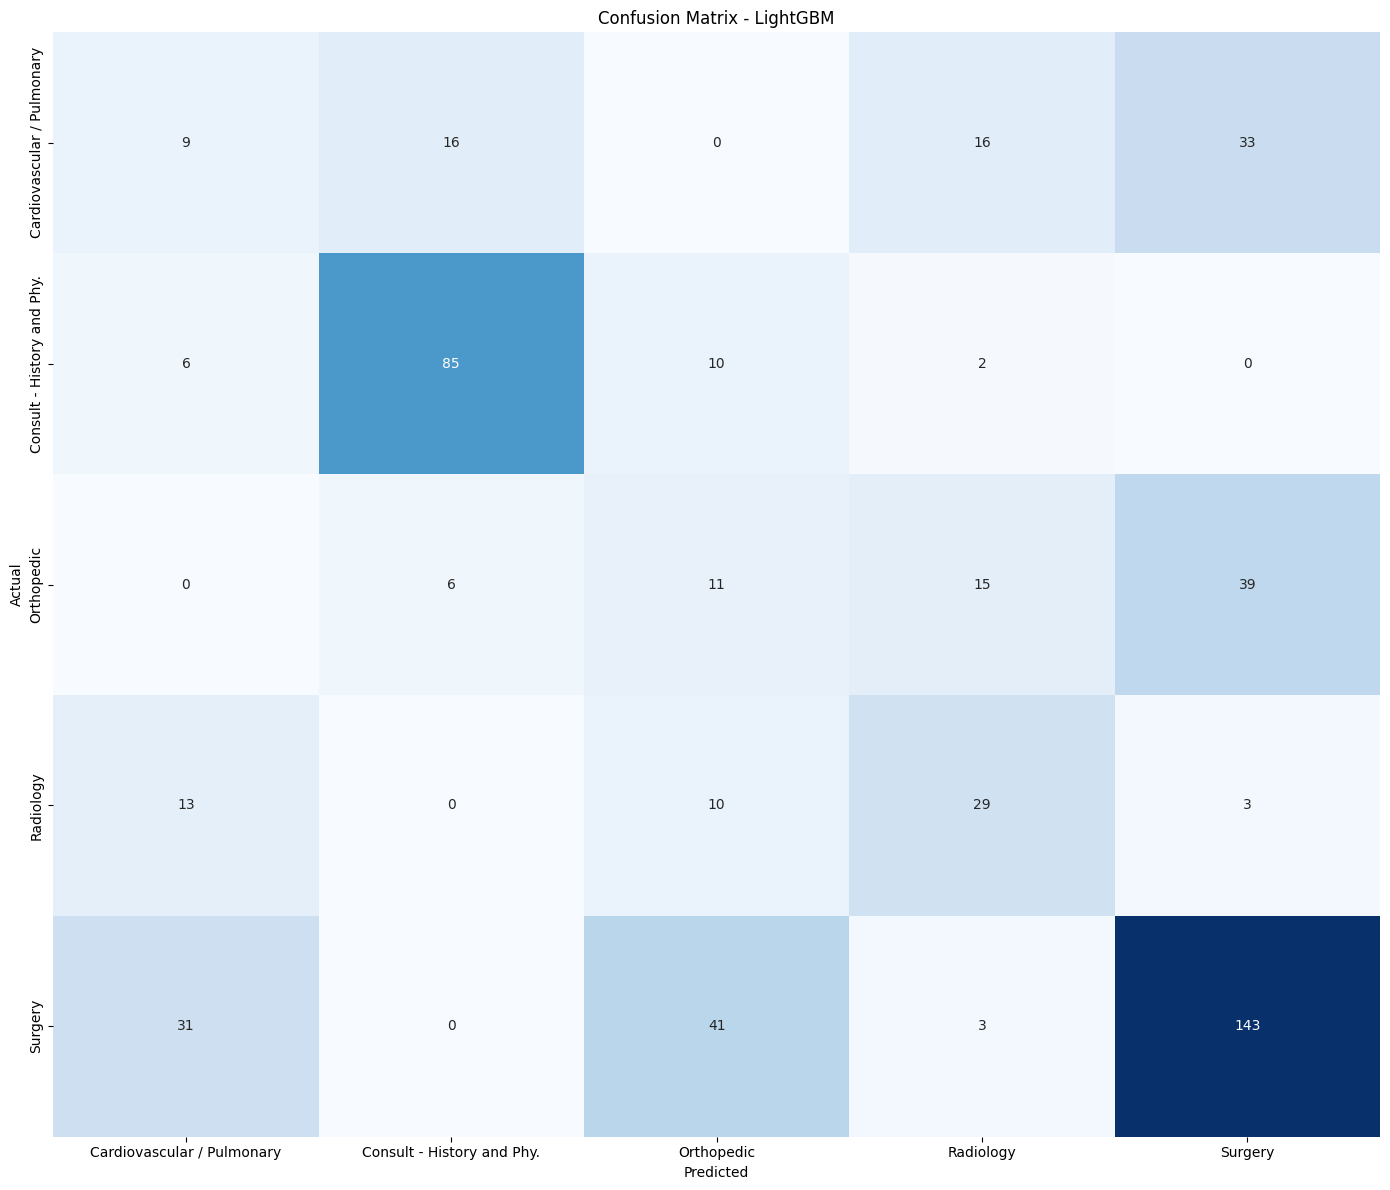

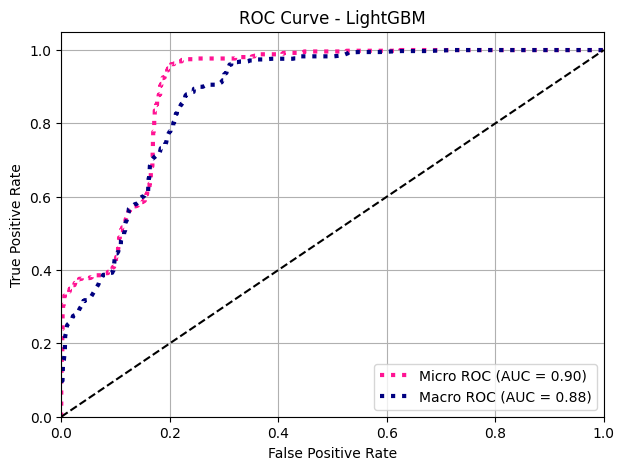


================ Stacking ================
Skip Learning Curve for Stacking (too computationally expensive).

Classification Report:
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary     0.8108    0.8108    0.8108        74
Consult - History and Phy.     0.9135    0.9223    0.9179       103
                Orthopedic     0.7500    0.8028    0.7755        71
                 Radiology     0.8800    0.8000    0.8381        55
                   Surgery     0.9217    0.9174    0.9195       218

                  accuracy                         0.8752       521
                 macro avg     0.8552    0.8507    0.8524       521
              weighted avg     0.8765    0.8752    0.8755       521



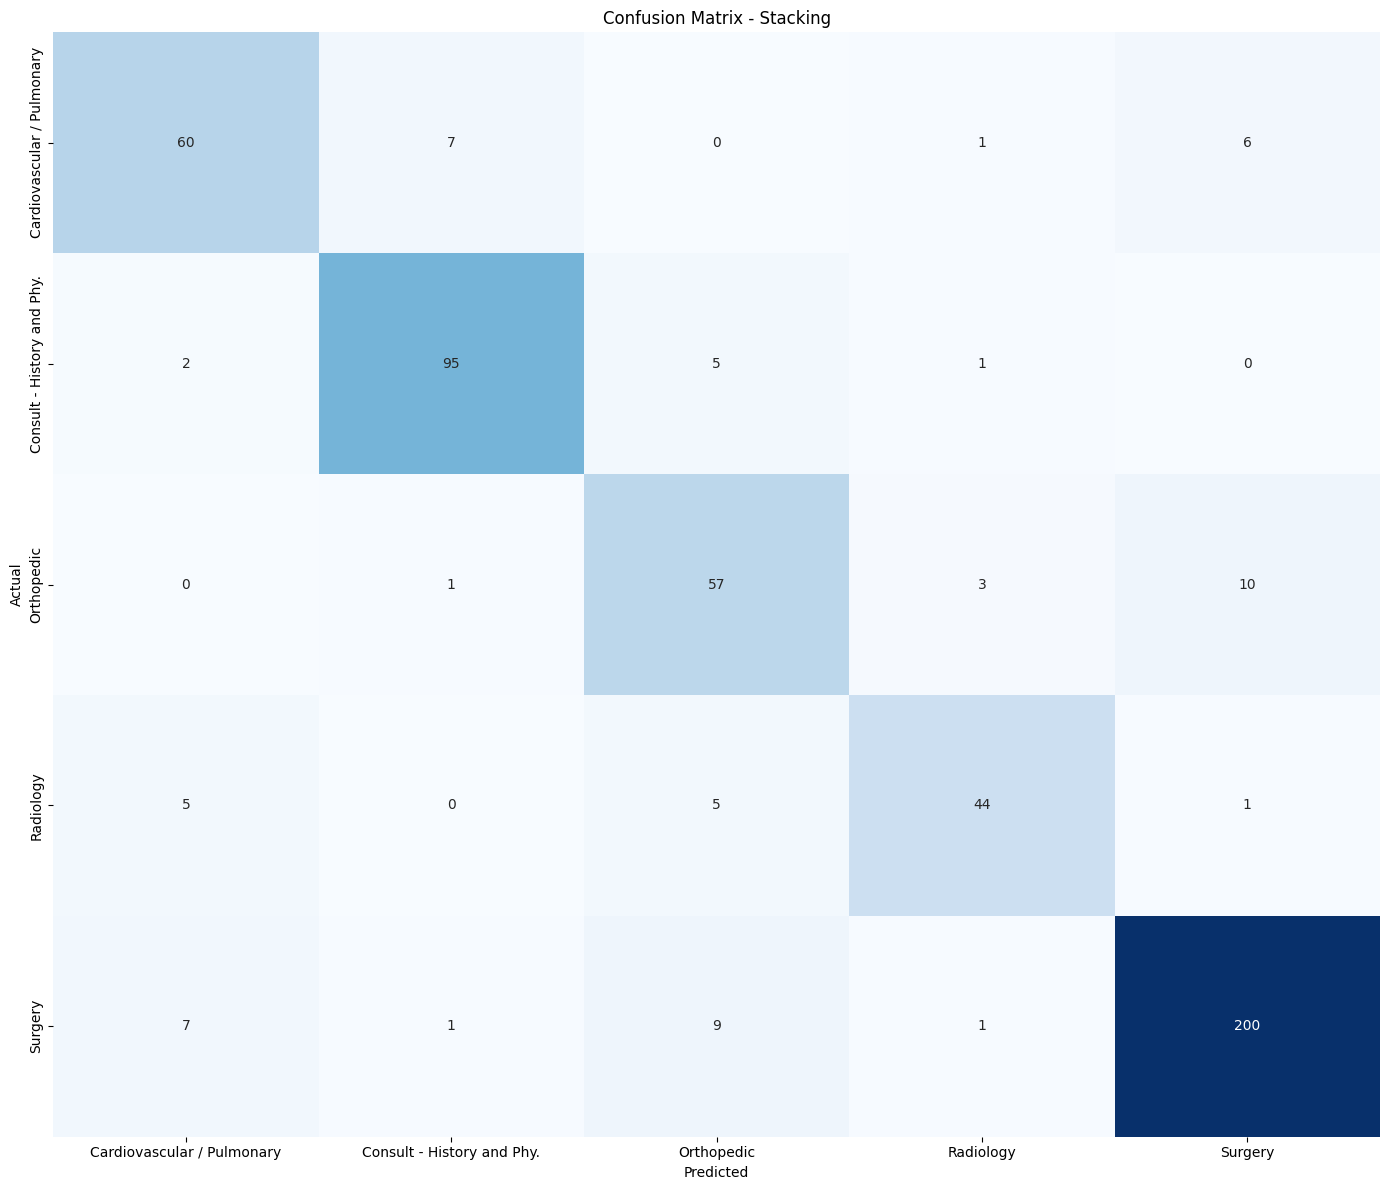

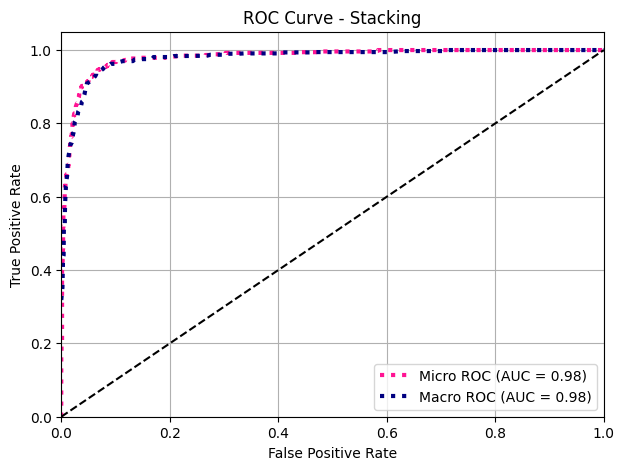


================ FINAL RESULT ================

                     Accuracy  Precision  Recall  F1-score
Model                                                     
Stacking               0.8752     0.8552  0.8507    0.8524
Logistic Regression    0.6526     0.6073  0.6353    0.6159
Linear SVM             0.6276     0.5213  0.5217    0.5156
LightGBM               0.5317     0.4404  0.4570    0.4476
Random Forest          0.5221     0.4428  0.4599    0.4497
XGBoost                0.5202     0.4142  0.4301    0.4213

 Mô hình tốt nhất: Stacking


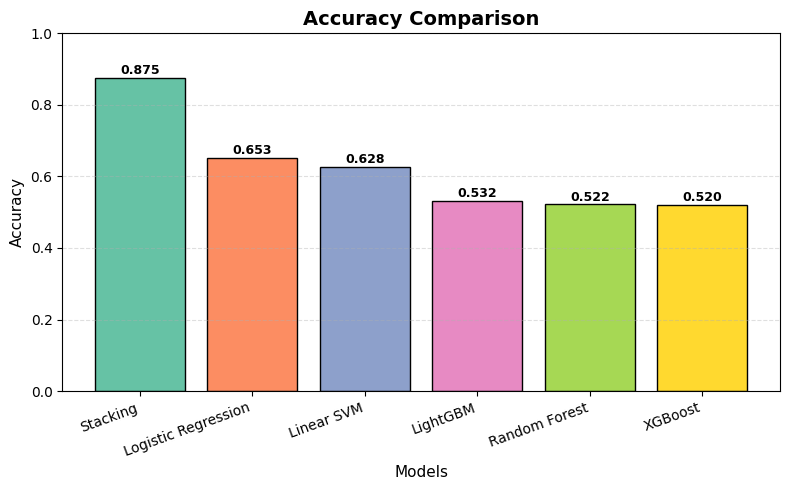

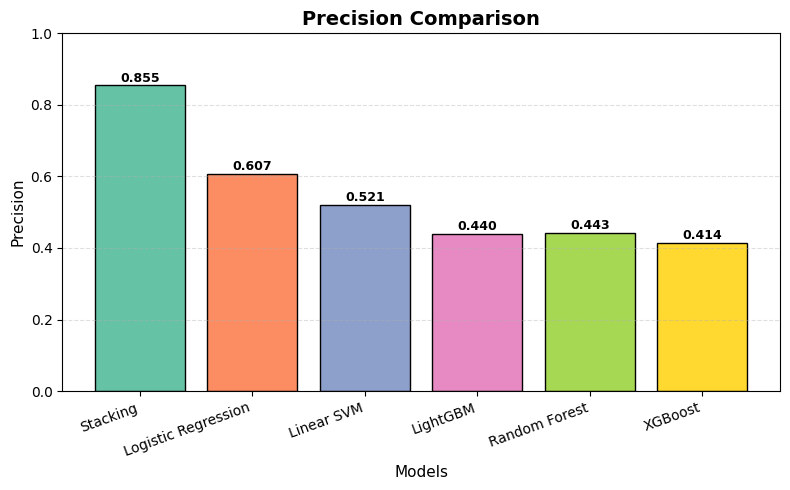

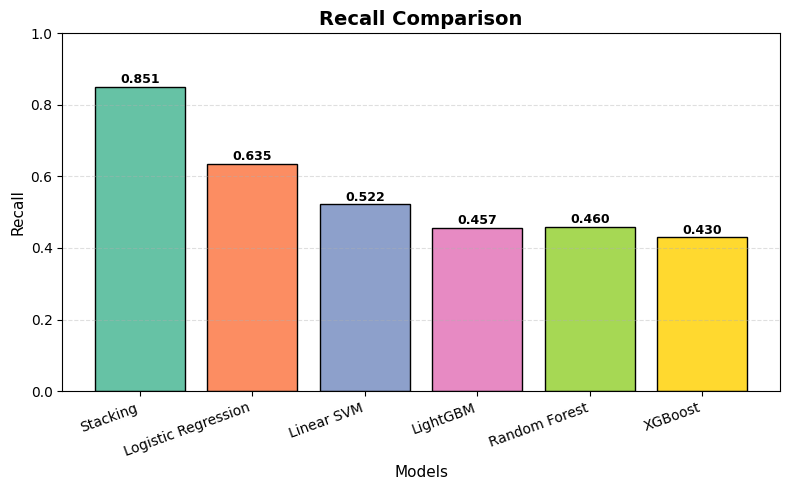

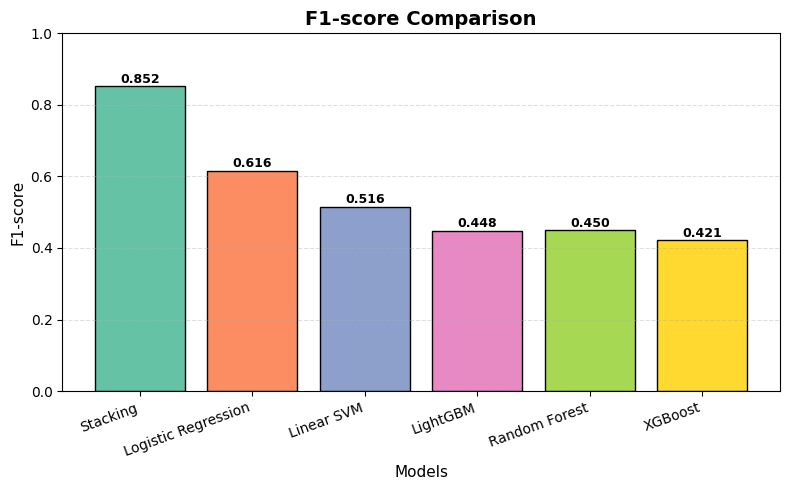

In [ ]:
selector = TruncatedSVD(
    n_components=300,
    random_state=42
)

results_dfsvd, best_modelsvd, allsvd_pipelines = evaluate_all_models(
    X_train,
    y_train_encoded,
    X_test,
    y_test_encoded,
    selector=selector,
    le=label_encoder
)
plot_metrics_bar(results_dfsvd)

### 📊 ĐÁNH GIÁ KẾT QUẢ MÔ HÌNH (FINAL RESULT)
**Stacking** vẫn đạt kết quả tốt nhất

### 📈 SO SÁNH ROC CURVE: STACKING VS XGBOOST

---

| Tiêu chí | 🥞 Stacking Classifier | 🚀 XGBoost | Chênh lệch |
| :--- | :---: | :---: | :--- |
| **Micro ROC (AUC)** | **0.98** | 0.91 | ➕ **+0.07** |
| **Macro ROC (AUC)** | **0.98** | 0.89 | ➕ **+0.09** |
| **Độ ổn định nhãn** | Hoàn hảo (Micro = Macro) | Lệch (Micro > Macro) | Stacking vượt trội trên mọi phân lớp |

---

**Stacking** đạt đỉnh hiệu năng phân loại (**AUC = 0.98**), tối ưu hóa hoàn toàn khả năng nhận diện lớp so với XGBoost (AUC 0.89 - 0.91).

# Mô hình tối ưu - TF-IDF + TruncatedSVD + stacking

In [253]:
import random

idx = random.sample(list(X_test.index), 5)

for i in idx:
    print("="*80)
    print("TRUE :", label_encoder.inverse_transform([y_test_encoded[X_test.index.get_loc(i)]])[0])

    pred = best_modelsvd.predict([X_test.loc[i]])
    print("PRED :", label_encoder.inverse_transform(pred)[0])

    print("\nTEXT:")
    print(X_test.loc[i][:600], "...")

TRUE : Consult - History and Phy.
PRED : Consult - History and Phy.

TEXT:
of present illness the is a 63 handed gentleman who present for further of multiple neurological symptom i asked him to discus each symptom individually a he had a very hard describing the nature of his problem he first mentioned that he neck pain he state that he had this for at least 15 it is worse movement it progressed very slowly over the course of 15 it is localized to the base of his neck and is sharp in quality he endorses a of gait instability this been present for a few and been slightly progressively worsening he describes that he feel unsteady on his foot and walk like a duck he fa ...
TRUE : Orthopedic
PRED : Orthopedic

TEXT:
diagnosis low back pain and degenerative lumbar disk the is a 59 who referred to physical secondary to low back pain and degenerative disk disease the state she had a cauterization of some sort to the nerve in her low back to help alleviate painful symptom the state that this 